# Universidad de Buenos Aires - FIUBA - LSE
# Aprendizaje Profundo - TP1
# Cohorte 27 - 5to bimestre 2026

## **Alumno 1:** Astorga, Víctor Hugo

## **Alumno 2:** González, Isabel

## **Alumno 3:** Souto, Matías Agustín

Este primer TP comienza la semana de la clase 2 y la ventana de entrega estará abierta hasta las **23:59 hs del domingo 15 de noviembre (hora de Argentina)**.

La resolución del TP puede realizarse de forma **individual, en parejas o hasta en grupos de 3 como máximo**. Sin embargo, no se recomienda repartir las preguntas entre los integrantes, sino que todos los integrantes deben trabajar conjuntamente en la resolución de cada pregunta. De esta manera, se promueve el debate, la discusión y la construcción de una conclusión compartida sobre cómo abordar y resolver cada pregunta.

Pueden utilizar tanto los contenidos vistos en clase, como otra bibliografía externa. Si se toman ideas de fuentes externas deben ser correctamente citadas incluyendo el correspondiente link o página de libro.

ESTE TP1 EQUIVALE A UN TERCIO DE SU NOTA FINAL.

El formato de entrega debe ser un link a un notebook de google colab. Importante permitir acceso a gvilcamiza.ext@fi.uba.ar y **habilitar los comentarios, para poder darles el feedback**. Si no lo hacen así no se podrá dar el feedback respectivo por cada pregunta.

**El desarrollo del TP se debe hacer obligatoriamente en un notebook**, ya sea en un Google Colab o en un Jupyter Notebook para quienes quieran desarrollarlo en su propia PC local (posteriormente deben subirlo a Google Drive). Pero no se aceptarán archivos `.py` o links a repos de github con múltiples archivos. El entregable debe ser un link a un único archivo en formato `.ipynb`.

El envío **se realizará en el siguiente link de google forms: [link](https://forms.gle/qUthoNdDRCsTxq4b8)**. Tanto los resultados, tablas, gráficas, como el código y las explicaciones deben quedar guardados y visualizables en el mismo notebook.

**NO SE VALIDARÁN ENVÍOS POR CORREO, EL ÚNICO MÉTODO DE ENTREGA ES SOLO POR EL FORMS.**

**Consideraciones a tener en cuenta:**
- Se entregará 1 solo colab para este TP1.
- Renombrar el archivo de la siguiente manera: **PRIMERAPELLIDOALUMNO1-PRIMERAPELLIDOALUMNO2-PRIMERAPELLIDOALUMNO3-TP1-Co26.ipynb**
O en caso hacerlo individual usar: **PRIMERAPELLIDO-PRIMERNOMBRE-TP1-Co26.ipynb**
- Los códigos deben poder ejecutarse.
- **IMPORTANTE:** Los resultados, cómo el código, los gráficos, los prints y las explicaciones deben quedar guardados y visualizables en el mismo notebook.
- No ocultar celdas, todas se deben poder ver desde el inicio.
- **Prestar mucha atención a cada consigna, responder las preguntas justo debajo del enunciado que corresponda.**
- Solo se revisarán los trabajos que hayan sido enviados por el forms.

# **PREGUNTA 1** (Temas de la clase 1 y 2)

## **Comparación de Gradiente Descendente y Adam en una Función de Costo No Convexa**

En este ejercicio se compararán los optimizadores Gradiente Descendente (GD) y Adam en la minimización de una función de costo basada en una red neuronal de una sola conexión sináptica:
$$
z = w x + b
$$
Con función de activación tangente hiperbólica:

$$
\hat{y} = a(z) = \tanh(z) = \tanh(w x + b)
$$

<br>

Se analizará la trayectoria de aprendizaje de ambos algoritmos y se evaluará su eficiencia con diferentes tasas de aprendizaje (learning rate).

<br>

La función de costo utilizada es el Error Cuadrático Medio (MSE):

$$
J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)^2
$$

$$
J(w, b) = \frac{1}{m} \sum_{i=1}^{m} ( \tanh(w x_i + b) - y_i )^2
$$

donde \\( w \\) y \\( b \\) son los parámetros que se busca optimizar.

<br>

Si bien es cierto, en estos experimentos buscamos tan solo comparar optimizadores (GD vs Adam), de igual forma se necesitará una especie de dataset. Este será sintético y solo de prueba, por ende tendrán cierta libertad para elegir sus valores. Sin embargo deberán tomar en cuenta que cumpla la siguiente estructura:

`x = np.linspace(ini, fin, n)`

donde `x` es un array de una sola dimensión y con `n` cantidad de valores ($n>=200$). Y tiene un rango de valores desde `ini` hasta `fin`. Recomiendo que sea simétrico, es decir, los mismos valores solo que con el signo cambiado, por ejemplo `ini=-3, fin=3`, `ini=-5, fin=5`, `ini=-1, fin=1`, etc. Queda a elección de ustedes.

<br>

Y con un target `y`:

`y = funcion_no_lineal(x) + ruido`

donde `y` es también un vector de una sola dimensión de tamaño `n` que sigue un patrón no lineal (elegido por ustedes) con respecto a `x` adicionando un ruido que puede ser creado con algunas de las funciones del paquete `np.random`.

El patrón no lineal puede ser una función trigonométrica, exponencial, logarítmica, sigmoidal, polinómica de grado mayor o igual a 3, o la combinación de varias de estas (recomendado), acotada de -1 a 1 en el eje vertical. Pero sean prudentes en la elección de la función no lineal, ya que recuerden que es una red de una sola conexión, por ende tampoco elijan algo tan complejo que al final provoque que el modelo no pueda converger. Pero tampoco vale usar una `tanh` sola, usen otra función, o si la van a usar debe estar combinada con otros patrones no lineales. Ya que al ser la función de activación tambien una `tanh`, el modelo la tendrá muy fácil converger a ella.

---
## Resolución - Pregunta 1

Antes de ir a cada inciso armamos lo que usan todos: el dataset, la red con su gradiente (que verificamos numéricamente antes de confiar en él), los optimizadores y los graficadores. Después respondemos cada inciso debajo de su enunciado.

El código está organizado en clases. `NeuralNetwork` sabe calcular su predicción, su costo y sus gradientes. Un `Optimizer` sabe recorrer una época: arma los batches, le pide los gradientes al modelo y actualiza los parámetros. Cada optimizador concreto (`GradientDescent`, `Adam`) solo define cómo se actualiza un parámetro. Así, GD y las dos variantes de Adam comparten exactamente el mismo modelo y el mismo recorrido de los datos, y lo único que cambia entre experimentos es la regla de actualización.

Usamos una semilla distinta para cada fuente de azar (ruido del dataset, inicialización y mezclado de los mini-batches). Así, si cambiamos una, no se mueven las otras, y los tres optimizadores arrancan siempre del mismo punto con los mismos datos.

La búsqueda del mínimo global con segundas derivadas (Hessiano), que usamos para validar los resultados y explicar la forma de la superficie, quedó en un **addendum al final de la Pregunta 1**. No hace falta para entrenar la red ni para comparar los optimizadores.

In [1]:
# PUNTO 1 - Configuración general (librerías, semillas, hiperparámetros)
import time
from abc import ABC, abstractmethod

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-",
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
    "lines.linewidth": 2.0,
})
pd.set_option("display.precision", 4)

SEED_DATA  = 7      # ruido del dataset sintético
SEED_INIT  = 35     # inicialización de w y b con np.random.randn() (ver justificación en 1a)
SEED_BATCH = 2026   # mezclado de los mini-batches de Adam

EPOCHS = 100
LRS = [0.1, 0.01, 0.001]

# --- Hiperparámetros de Adam (valores por defecto del paper de Kingma & Ba, 2015) ---
BETA1, BETA2, EPS = 0.9, 0.999, 1e-8
BATCH_SIZE = 32     # N = 512 da 16 mini-batches exactos por época

# --- Colores: un color fijo por optimizador y otro juego (con distinto trazo) por learning rate ---
OPTS = ["GD", "Adam full-batch", "Adam mini-batch"]
COLOR_OPT = {"GD": "#2a78d6", "Adam full-batch": "#eb6834", "Adam mini-batch": "#1baf7a"}
COLOR_LR  = {0.1: "#6250d6", 0.01: "#e34948", 0.001: "#eda100"}
LS_LR     = {0.1: "-", 0.01: "--", 0.001: ":"}
LS_OPT    = {"GD": "-", "Adam full-batch": "--", "Adam mini-batch": "-"}   # trazo distinto: si dos curvas coinciden, ambas se ven
LW_OPT    = {"GD": 2.4, "Adam full-batch": 2.4, "Adam mini-batch": 1.0}  # mini-batch más fino: tiene 16x más pasos

### Dataset

Probamos varias combinaciones antes de quedarnos con esta:

$$
f(x) = 0.6\,\sin(0.9x) + 0.25\left(\tfrac{x}{3}\right)^3 + 0.2\,e^{-(x-1)^2}
$$

con $x$ entre -3 y 3 y ruido gaussiano de desvío 0.1. Tiene una parte trigonométrica, una cúbica y una exponencial, y no usa tanh.

Lo que buscábamos era que la neurona pudiera aprender la forma general (una S creciente) pero no todo. La función sube hasta un máximo cerca de x = 1.5 y después baja, y del lado izquierdo tiene un mínimo cerca de x = -2. Una tanh es siempre monótona, así que esos tramos no los va a poder copiar. Nos sirve que sea así porque deja un error mínimo que no es culpa del optimizador, y eso después nos permite separar las dos cosas.

La campana exponencial la centramos en x = 1 a propósito. Con una función impar el sesgo óptimo da casi 0 y el eje b de la superficie 3D queda aburrido. Con la campana corrida, b también importa.

Usamos N = 512 puntos porque 512 = 16 x 32: con batch de 32 nos quedan 16 lotes exactos por época, sin un último lote más chico.

El dataset queda en un `DataFrame` con una columna de entrada (`x`) y una de salida (`y`), que es el formato que recibe `NeuralNetwork`.

N = 512 muestras, x en [-3, 3]
f(x) en [-0.659, 0.773]  -> acotada dentro de [-1, 1]
Ruido: media = -0.0134, desvío = 0.0936  -> MSE irreducible ~ 0.0089
Varianza de y = 0.3338  (costo de predecir siempre la media; sirve de escala para el R²)


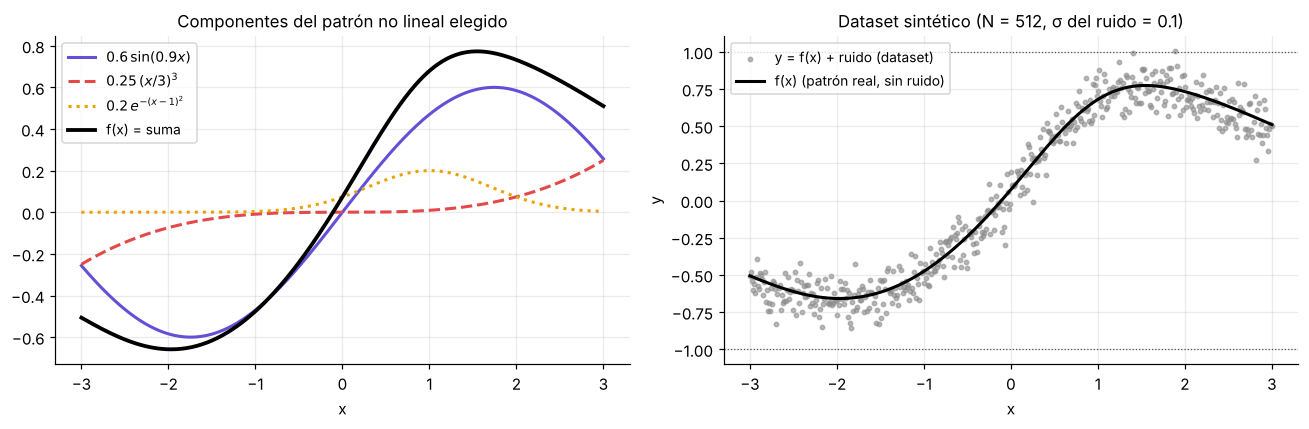

In [2]:
# Dataset sintético:  y = f(x) + ruido
N = 512                                  # n >= 200 (consigna); 512 = 16 x 32 -> mini-batches exactos
SIGMA = 0.1                              # desvío estándar del ruido gaussiano

def f_true(x):
    """Patrón no lineal = trigonométrica + polinómica (grado 3) + exponencial (campana desplazada)."""
    return 0.6 * np.sin(0.9 * x) + 0.25 * (x / 3) ** 3 + 0.2 * np.exp(-(x - 1) ** 2)

x = np.linspace(-3, 3, N)                # dominio simétrico
noise = np.random.default_rng(SEED_DATA).normal(0.0, SIGMA, size=N)
dataset = pd.DataFrame({"x": x, "y": f_true(x) + noise})

X, Y = dataset[["x"]], dataset["y"]      # entrada y target en el formato que recibe NeuralNetwork
y = dataset["y"].to_numpy()              # target como vector, para métricas y gráficos

print(f"N = {N} muestras, x en [{x.min():.0f}, {x.max():.0f}]")
print(f"f(x) en [{f_true(x).min():.3f}, {f_true(x).max():.3f}]  -> acotada dentro de [-1, 1]")
print(f"Ruido: media = {noise.mean():+.4f}, desvío = {noise.std():.4f}  -> MSE irreducible ~ {np.mean(noise**2):.4f}")
print(f"Varianza de y = {y.var():.4f}  (costo de predecir siempre la media; sirve de escala para el R²)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(x, 0.6 * np.sin(0.9 * x), label=r"$0.6\,\sin(0.9x)$", color="#6250d6")
ax.plot(x, 0.25 * (x / 3) ** 3, label=r"$0.25\,(x/3)^3$", color="#e34948", ls="--")
ax.plot(x, 0.2 * np.exp(-(x - 1) ** 2), label=r"$0.2\,e^{-(x-1)^2}$", color="#eda100", ls=":")
ax.plot(x, f_true(x), label="f(x) = suma", color="k", lw=2.5)
ax.set_title("Componentes del patrón no lineal elegido"); ax.set_xlabel("x"); ax.legend()

ax = axes[1]
ax.scatter(dataset["x"], dataset["y"], s=8, color="0.55", alpha=0.6, label="y = f(x) + ruido (dataset)")
ax.plot(x, f_true(x), color="k", lw=2, label="f(x) (patrón real, sin ruido)")
ax.axhline(1, color="0.3", lw=0.8, ls=":"); ax.axhline(-1, color="0.3", lw=0.8, ls=":")
ax.set_title(f"Dataset sintético (N = {N}, σ del ruido = {SIGMA})"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### Modelo, costo y gradiente

`NeuralNetwork` implementa $a = \tanh(z)$ con $z = XW^T + b$, donde $a$ es la salida $\hat y$. Acá hay una sola entrada y una sola neurona, así que $W$ es una matriz de 1 x 1 (el $w$ de la consigna) y $b$ un vector de largo 1, pero la clase toma las formas de las columnas de `X` e `y`. El costo $L$ es el MSE, o sea la $J(w, b)$ de la consigna.

`gradients` aplica la regla de la cadena en tres pasos, y cada derivada parcial tiene su variable en el código:

| Derivada | Fórmula | Variable en `gradients` |
|---|---|---|
| del MSE respecto de la salida | $\dfrac{\partial L}{\partial a_i} = \dfrac{2}{m}(a_i - y_i)$ | `dL_a` |
| de la tanh | $\dfrac{\partial a_i}{\partial z_i} = 1 - \tanh^2(z_i) = 1 - a_i^2$ | `da_z = d_tanh(Z)` |
| del costo respecto de $z$ | $\dfrac{\partial L}{\partial z_i} = \dfrac{\partial L}{\partial a_i}\,\dfrac{\partial a_i}{\partial z_i}$ | `dL_z = dL_a * da_z` |
| de $z$ respecto de cada parámetro | $\dfrac{\partial z_i}{\partial W} = x_i, \quad \dfrac{\partial z_i}{\partial b} = 1$ | `dz_w = X`, `dz_b = 1` |

Juntando todo queda el gradiente que devuelve la función (`w_diff` y `b_diff`):

$$
\frac{\partial L}{\partial W} = \left(\frac{\partial L}{\partial z}\right)^{T} X = \sum_{i=1}^{m} \frac{\partial L}{\partial z_i}\, x_i
\qquad\qquad
\frac{\partial L}{\partial b} = \sum_{i=1}^{m} \frac{\partial L}{\partial z_i}
$$

El factor $\partial a/\partial z = 1 - a^2$ (`da_z`) es la derivada de la tanh y termina explicando casi todo lo que pasa en este TP. Cuando la tanh se satura (salida pegada a +1 o -1), ese factor da casi cero, entonces `dL_z` y con él todo el gradiente desaparecen aunque el modelo se esté equivocando muchísimo (`dL_a` grande).

`train(optimizer, epochs)` guarda el costo y los parámetros en la época 0 (el punto inicial, sin entrenar) y al final de cada época (`loss_history`, `param_history`). El trabajo de cada época se lo delega al optimizador.

In [3]:
def d_tanh(x):
    return 1 - np.tanh(x) ** 2

class NeuralNetwork:
    """Red de una capa con activación tanh, entrenada con MSE.
    X es (n_samples, n_features) e y es (n_samples, n_neurons); W es (n_neurons, n_features) y b (n_neurons,)."""
    def __init__(self, X, y, W, b):
        self.X = self._as_matrix(X)  # (n_samples, n_features)
        self.y = self._as_matrix(y)  # (n_samples, n_neurons)
        W_shape, b_shape = self.param_shapes(self.X, self.y)
        self.W = np.array(W, dtype=float)
        self.b = np.array(b, dtype=float)
        if self.W.shape != W_shape or self.b.shape != b_shape:
            raise ValueError(
                f"W debe ser {W_shape} y b {b_shape} (neuronas x features), "
                f"se recibió W {self.W.shape} y b {self.b.shape}"
            )
        self.loss_history = []   # J al final de cada época (la posición 0 es el punto inicial)
        self.param_history = []  # (W, b) al final de cada época (la posición 0 es el punto inicial)

    @staticmethod
    def _as_matrix(A):
        A = np.asarray(A, dtype=float)
        return A.reshape(A.shape[0], -1)

    @staticmethod
    def param_shapes(X, y):
        """W es (n_neurons, n_features) y b es (n_neurons,).
        n_features sale de las columnas de X y n_neurons de las columnas de y"""
        n_features = NeuralNetwork._as_matrix(X).shape[1]
        n_neurons = NeuralNetwork._as_matrix(y).shape[1]
        return (n_neurons, n_features), (n_neurons,)

    @property
    def params(self):
        return {"W": self.W, "b": self.b}

    @params.setter
    def params(self, new_params):
        self.W, self.b = new_params["W"], new_params["b"]

    def gradients(self, X, y):
        n_samples = X.shape[0]
        Z = self._z(X)                               # (n_samples, n_neurons)
        dL_a = 2 * (np.tanh(Z) - y) / n_samples      # derivada del MSE
        da_z = d_tanh(Z)
        dL_z = dL_a * da_z                           # (n_samples, n_neurons)
        # Z = X @ W.T + b
        dz_w = X                                     # (n_samples, n_features)
        dz_b = np.ones(n_samples)                    # (n_samples,)
        w_diff = dL_z.T @ dz_w                       # (n_neurons, n_features)
        b_diff = dL_z.T @ dz_b                       # (n_neurons,)
        return {"W": w_diff, "b": b_diff}

    def train(self, optimizer, epochs=1):
        if not self.loss_history:                    # época 0: punto inicial, sin entrenar
            self._save_state()
        for epoch in range(epochs):
            optimizer.run_epoch(self)
            self._save_state()
        return self.loss_history

    def _save_state(self):
        self.loss_history.append(self.loss())
        self.param_history.append((self.W.copy(), self.b.copy()))

    def _z(self, X=None):
        X = self.X if X is None else self._as_matrix(X)
        return X @ self.W.T + self.b

    def predict(self, X=None):
        return np.tanh(self._z(X))

    def loss(self):
        return np.mean((self.predict() - self.y) ** 2)

def loss_at(model, W, b):
    """Costo J sobre los datos de `model`, evaluado en otros parámetros (W, b) sin modificar `model`."""
    return NeuralNetwork(model.X, model.y, W, b).loss()

W_shape, b_shape = NeuralNetwork.param_shapes(X, Y)
print(f"Forma de W: {W_shape}   forma de b: {b_shape}")

Forma de W: (1, 1)   forma de b: (1,)


#### Verificación a priori

Antes de usar el gradiente lo comparamos con diferencias finitas centradas en algunos puntos al azar. Si la derivada tuviera un error de signo, las curvas igual podrían "verse bien" y no nos daríamos cuenta.

In [4]:
# --- Verificación del gradiente: NeuralNetwork.gradients vs diferencias finitas centradas sobre loss() ---
FINITE_DIFFERENCE_STEP = 1e-6    # h de las diferencias finitas
NUMBER_OF_CHECK_POINTS = 5       # puntos (w, b) al azar donde se compara
MAX_RELATIVE_ERROR = 1e-7        # por debajo de esto, las dos derivadas coinciden

def analytic_gradient(model):
    """(dJ/dw, dJ/db) calculado por NeuralNetwork.gradients con la regla de la cadena."""
    gradients = model.gradients(model.X, model.y)
    return gradients["W"][0, 0], gradients["b"][0]

def numerical_gradient(model, step=FINITE_DIFFERENCE_STEP):
    """(dJ/dw, dJ/db) por diferencias finitas centradas: [J(θ + h) - J(θ - h)] / 2h, solo con loss()."""
    W, b = model.W, model.b
    dJ_dw = (loss_at(model, W + step, b) - loss_at(model, W - step, b)) / (2 * step)
    dJ_db = (loss_at(model, W, b + step) - loss_at(model, W, b - step)) / (2 * step)
    return dJ_dw, dJ_db

def relative_error(analytic, numerical):
    """Distancia entre los dos gradientes, relativa a su tamaño (no depende de la escala de J)."""
    analytic, numerical = np.array(analytic), np.array(numerical)
    return np.linalg.norm(analytic - numerical) / (np.linalg.norm(analytic) + np.linalg.norm(numerical))

check_points = np.random.default_rng(0).uniform(-3, 3, size=(NUMBER_OF_CHECK_POINTS, 2))
comparison_rows = []
for w_point, b_point in check_points:
    model_at_point = NeuralNetwork(X, Y, W=[[w_point]], b=[b_point])
    analytic_dw, analytic_db = analytic_gradient(model_at_point)
    numerical_dw, numerical_db = numerical_gradient(model_at_point)
    comparison_rows.append({
        "w": w_point, "b": b_point,
        "dJ/dw analítica": analytic_dw, "dJ/dw numérica": numerical_dw,
        "dJ/db analítica": analytic_db, "dJ/db numérica": numerical_db,
        "error relativo": relative_error((analytic_dw, analytic_db), (numerical_dw, numerical_db)),
    })
gradient_check = pd.DataFrame(comparison_rows)

display(gradient_check.style
        .format("{:.3e}", subset=["error relativo"])
        .format("{:.6f}", subset=["w", "b", "dJ/dw analítica", "dJ/dw numérica", "dJ/db analítica", "dJ/db numérica"]))
print("Gradiente verificado:", bool((gradient_check["error relativo"] < MAX_RELATIVE_ERROR).all()))

,w,b,dJ/dw analítica,dJ/dw numérica,dJ/db analítica,dJ/db numérica,error relativo
0,0.821770,-1.381280,-0.517247,-0.517247,-0.497514,-0.497514,2.345e-11
1,-2.754159,-2.900834,-0.177613,-0.177613,0.117722,0.117722,3.176e-10
2,1.879621,2.476533,-0.182879,-0.182879,0.193837,0.193837,9.434e-11
3,0.639815,1.376979,-0.781114,-0.781114,0.568188,0.568188,1.683e-11
4,0.261750,2.610435,-0.144851,-0.144851,0.082462,0.082462,4.712e-10


Gradiente verificado: True


### Optimizadores

`Optimizer` es una clase abstracta que se encarga de recorrer una época. Sin `batch_size` usa todo el dataset en un solo paso (full-batch). Con `batch_size`, mezcla las muestras al empezar cada época y las recorre sin reemplazo, dando un paso por mini-batch. Cada subclase solo implementa `_update`, la regla para actualizar un parámetro; el estado propio del optimizador (por ejemplo, los momentos de Adam) se guarda por nombre de parámetro.

Además, en cada actualización `Optimizer` guarda en `history` los parámetros resultantes, el tamaño del gradiente y el tamaño del paso. Las curvas de costo solo miran el final de cada época, y con este registro después podemos dibujar la trayectoria paso a paso y analizar por qué cada optimizador se mueve como se mueve.

Acá definimos la base y `GradientDescent`. `Adam` lo definimos en 1b, junto con su explicación.

In [5]:
class Optimizer(ABC):
    """Se encarga de recorrer una época: arma los batches, pide los gradientes al modelo
    y actualiza sus parámetros. Sin `batch_size` es full-batch. Con `batch_size` las muestras
    se mezclan en cada época y se da un paso por mini-batch.
    Cada subclase implementa `_update` para un parámetro. El estado propio del optimizador
    se guarda por nombre de parámetro.
    En `history` queda un registro por actualización (parámetros resultantes, |gradiente| y |paso|)."""
    def __init__(self, learning_rate=0.01, batch_size=None, seed=None):
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.shuffle_rng = np.random.default_rng(seed)
        self.step_count = 0
        self.history = []

    def run_epoch(self, model):
        for batch_indices in self._batches(model.X.shape[0]):
            gradients = model.gradients(model.X[batch_indices], model.y[batch_indices])
            model.params = self.step(model.params, gradients)

    def _batches(self, n_samples):
        batch_size = self.batch_size or n_samples
        if batch_size < n_samples:
            sample_order = self.shuffle_rng.permutation(n_samples)
        else:
            sample_order = np.arange(n_samples)
        for batch_start in range(0, n_samples, batch_size):
            yield sample_order[batch_start:batch_start + batch_size]

    def step(self, params, gradients):
        self.step_count += 1
        new_params = {name: self._update(name, params[name], gradients[name]) for name in params}
        self._log(params, new_params, gradients)
        return new_params

    def _log(self, params, new_params, gradients):
        self.history.append({
            "params": {name: value.copy() for name, value in new_params.items()},
            "grad_norm": self._norm(gradients),
            "step_norm": self._norm({name: new_params[name] - params[name] for name in params}),
            **self._extra_log(),
        })

    @staticmethod
    def _norm(arrays):
        """Norma euclídea del conjunto de parámetros (o gradientes) tomados como un único vector."""
        return float(np.sqrt(sum(np.sum(a ** 2) for a in arrays.values())))

    def _extra_log(self):
        """Datos adicionales que cada optimizador quiera registrar en cada actualización."""
        return {}

    @abstractmethod
    def _update(self, name, param, gradient):
        pass

class GradientDescent(Optimizer):
    def _update(self, name, param, gradient):
        return param - self.learning_rate * gradient

### Graficadores y herramientas de análisis

Para no repetir código en cada inciso:
- `plot_loss_curves` y `plot_fit` grafican las curvas de costo y el ajuste del modelo (aceptan un `ax` para usarlas en subplots).
- `epoch_params` y `update_path` sacan la trayectoria de (w, b) por época (de `param_history`) o por actualización (de `optimizer.history`).
- `cost_surface` y `gradient_norm_surface` evalúan $J$ y $|\nabla J|$ sobre una grilla. Usan la misma `NeuralNetwork`, así la superficie que se dibuja es exactamente la que ven los optimizadores.
- `plot_trajectories` y `plot_trajectories_3d` dibujan las trayectorias sobre las curvas de nivel y sobre la superficie.

In [6]:
def plot_loss_curves(histories, ax=None, title="Costo J(w, b) por época", colors=None, linestyles=None,
                     log_scale=False, reference=None, reference_label="J_ref"):
    """Grafica superpuestas las curvas de costo vs época (la época 0 es el punto inicial).
    `histories` es un dict {etiqueta: loss_history}, por ejemplo {"lr=0.1": red.loss_history}.
    Si se pasa `ax` se dibuja en ese subplot; `colors` y `linestyles` son dicts opcionales {etiqueta: valor}
    para que el mismo optimizador tenga el mismo estilo en todos los subplots.
    `reference` agrega una línea horizontal (por ejemplo, el mejor costo observado)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    for label, history in histories.items():
        color = colors.get(label) if colors else None
        ls = linestyles.get(label, "-") if linestyles else "-"
        ax.plot(range(len(history)), history, label=label, color=color, ls=ls)
    if reference is not None:
        ax.axhline(reference, color="k", lw=1, ls="-.", label=f"{reference_label} = {reference:.4f}")
    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.set_ylabel("J(w, b)")
    ax.set_xlim(0, max(len(h) for h in histories.values()) - 1)
    if log_scale:
        ax.set_yscale("log")
    ax.legend()
    return ax

def plot_fit(model, ax=None, title="Dataset vs modelo", color="tab:red", true_fn=None, reference_model=None,
             label="modelo entrenado"):
    """Grafica el dataset sintético y(x) junto con la función aprendida por `model`.
    `true_fn` agrega el patrón real sin ruido y `reference_model` otro modelo de referencia (punteado)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    x_ = model.X[:, 0]
    order = np.argsort(x_)
    ax.scatter(x_, model.y[:, 0], s=5, color="0.65", alpha=0.5, label="dataset (y)")
    if true_fn is not None:
        ax.plot(x_[order], true_fn(x_[order]), color="k", lw=1.3, ls="--", label="patrón real f(x)")
    if reference_model is not None:
        ax.plot(x_[order], reference_model.predict()[order, 0], color="0.35", lw=1, ls=":", label="mejor ajuste observado")
    ax.plot(x_[order], model.predict()[order, 0], color=color, lw=2.4, label=label)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    return ax

def epoch_params(model):
    """(w, b) al final de cada época (posición 0 = punto inicial), como dos arrays 1D.
    Asume una sola entrada y una sola neurona, como en este ejercicio."""
    w = np.array([W[0, 0] for W, _ in model.param_history])
    b = np.array([b_[0] for _, b_ in model.param_history])
    return w, b

def update_path(model, optimizer):
    """(w, b) después de cada actualización del optimizador (posición 0 = punto inicial)."""
    W_init, b_init = model.param_history[0]
    w = np.array([W_init[0, 0]] + [h["params"]["W"][0, 0] for h in optimizer.history])
    b = np.array([b_init[0]] + [h["params"]["b"][0] for h in optimizer.history])
    return w, b

def cost_along(model, w, b):
    """J evaluado en cada punto (w_k, b_k) de una trayectoria."""
    return np.array([loss_at(model, [[w_k]], [b_k]) for w_k, b_k in zip(w, b)])

def cost_surface(model, W_grid, B_grid):
    """J(w, b) en cada punto de una malla (W_grid, B_grid) de np.meshgrid."""
    J = np.empty(W_grid.shape)
    for idx in np.ndindex(W_grid.shape):
        J[idx] = loss_at(model, [[W_grid[idx]]], [B_grid[idx]])
    return J

def gradient_norm_surface(model, W_grid, B_grid):
    """|∇J(w, b)| en cada punto de una malla, usando NeuralNetwork.gradients."""
    G = np.empty(W_grid.shape)
    for idx in np.ndindex(W_grid.shape):
        probe = NeuralNetwork(model.X, model.y, [[W_grid[idx]]], [B_grid[idx]])
        G[idx] = Optimizer._norm(probe.gradients(probe.X, probe.y))
    return G

def window(paths, extra_points=(), pad=0.35):
    """Ventana (w_min, w_max, b_min, b_max) que contiene todas las trayectorias y puntos extra."""
    ws = np.concatenate([w for w, _ in paths.values()] + [[p[0] for p in extra_points]])
    bs = np.concatenate([b for _, b in paths.values()] + [[p[1] for p in extra_points]])
    return ws.min() - pad, ws.max() + pad, bs.min() - pad, bs.max() + pad

def plot_trajectories(paths, W_grid, B_grid, J_grid, ax=None, title="", start=None, target=None,
                      marks=None, n_levels=25):
    """Curvas de nivel de J y trayectorias en el plano (w, b).
    `paths` es {optimizador: (w, b)}; `marks` (opcional) es {optimizador: (w, b)} con puntos a resaltar.
    `start` es el punto inicial común y `target` el mejor punto observado (estrella)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5.5))
    levels = np.geomspace(J_grid.min() * 1.01, J_grid.max(), n_levels)
    ax.contour(W_grid, B_grid, J_grid, levels=levels, cmap="Greys", linewidths=0.7)
    for opt, (w, b) in paths.items():
        ax.plot(w, b, color=COLOR_OPT[opt], lw=LW_OPT[opt], label=opt)
        ax.plot(w[-1], b[-1], "o", color=COLOR_OPT[opt], ms=9, mec="k")
        if marks and opt in marks:
            ax.plot(*marks[opt], "o", color=COLOR_OPT[opt], ms=4.5, mec="k", mew=0.5)
    if start is not None:
        ax.plot(*start, "o", ms=10, mfc="white", mec="k", mew=2)
    if target is not None:
        ax.plot(*target, "*", ms=17, color="#eda100", mec="k")
    ax.set_title(title); ax.set_xlabel("w"); ax.set_ylabel("b"); ax.grid(False)
    return ax

def plot_trajectories_3d(paths, W_grid, B_grid, J_grid, model, ax, labels=None, start=None, target=None):
    """Superficie J(w, b) con las trayectorias encima. `model` aporta los datos para evaluar J en cada punto."""
    ax.plot_surface(W_grid, B_grid, J_grid, cmap="Greys", alpha=0.55, linewidth=0, antialiased=True, rstride=2, cstride=2)
    ax.contour(W_grid, B_grid, J_grid, levels=15, zdir="z", offset=0, cmap="Greys", linewidths=0.6)
    lift = 0.02 * (J_grid.max() - J_grid.min())   # pequeño desplazamiento vertical para que la línea no quede tapada
    for opt, (w, b) in paths.items():
        J_path = cost_along(model, w, b)
        label = labels.get(opt, opt) if labels else opt
        ax.plot(w, b, J_path + lift, color=COLOR_OPT[opt], lw=LW_OPT[opt] + 0.2, label=label, zorder=10)
        ax.scatter(w[-1], b[-1], J_path[-1] + lift, color=COLOR_OPT[opt], s=60, edgecolor="k", zorder=11)
    if start is not None:
        ax.scatter(*start, loss_at(model, [[start[0]]], [start[1]]) + lift, color="white", edgecolor="k",
                   s=90, linewidth=2, label="inicio común", zorder=12)
    if target is not None:
        ax.scatter(*target, loss_at(model, [[target[0]]], [target[1]]) + lift, color="#eda100", edgecolor="k",
                   marker="*", s=300, label="mejor punto observado", zorder=12)
    ax.set_xlabel("w"); ax.set_ylabel("b"); ax.set_zlabel("J(w, b)")
    ax.set_zlim(0, J_grid.max())
    return ax

### 1a) Implementación del Gradiente Descendente (1 punto)
- Implementar el algoritmo del Gradiente Descendente (GD) para minimizar \\( J(w, b) \\).
- Utilizar 100 épocas y 3 diferentes learning rates `(0.1, 0.01, 0.001)`.
- Inicializar valores de \\( w \\) y \\( b \\) de manera aleatoria con `np.random.randn()`.
- Graficar la función de Costo \\( J(w, b) \\) VS número de época para comparar cómo converge la función para cada uno de los 3 learning rates. Las 3 gráficas deben estar en el mismo plot y superpuestas para que la comparación visual sea más fácil. Deben graficarlas con diferente color y con leyenda para no confundirlas.

<br>

El optimizador del Gradiente Descendente se debe implementar haciendo el código desde cero y paso a paso. Se pueden usar librerías como `numpy`, `scipy`, `matplotlib` o similares. Pero no está permitido usar PyTorch ni TensorFlow o frameworks que ya contengan el optimizador desarrollado.

#### Resolución 1a)

GD clásico: en cada época se calcula el gradiente con las 512 muestras y se da un paso de tamaño lr por el gradiente, en sentido contrario. Es `GradientDescent` con `batch_size=None`, o sea 1 actualización por época. El paso es proporcional a la pendiente. Eso está bien cerca del mínimo (frena solo), pero en una zona plana casi no se mueve.

Sobre la inicialización: usamos `np.random.randn()` con semilla 35, con la forma que pide la red (`W_shape`, `b_shape`), y esos mismos valores los reutilizamos en 1b. Elegimos la semilla a propósito. Primero probamos con la 42, pero arranca en (0.50, -0.14), prácticamente encima del óptimo, y los tres optimizadores llegaban igual; no había nada para comparar. La 35 da (-1.89, -0.41): un modelo "dado vuelta" (con w negativo la curva baja donde los datos suben) y saturado. Es un arranque difícil, pero no raro: casi la mitad de las inicializaciones con randn tienen w negativo. Para no depender de esta elección, en 1c repetimos todo con 500 semillas.

`train_model` crea una red nueva con los pesos iniciales, la entrena con el optimizador que recibe y mide el tiempo. Como `NeuralNetwork` copia los pesos que recibe, todos los experimentos arrancan del mismo `w0`, `b0` sin pisarse.

In [7]:
# 1a) Gradiente Descendente (full-batch)
# Inicialización aleatoria con np.random.randn() (se guarda y se reutiliza en TODOS los optimizadores)
np.random.seed(SEED_INIT)
w0 = np.random.randn(*W_shape)
b0 = np.random.randn(*b_shape)
W0, B0 = w0[0, 0], b0[0]                  # los mismos valores como escalares, para gráficos y prints

start_model = NeuralNetwork(X, Y, w0, b0)
print(f"Punto inicial común: w0 = {W0:.4f}, b0 = {B0:.4f}  ->  J(w0, b0) = {start_model.loss():.4f}"
      f"  |grad J| = {Optimizer._norm(start_model.gradients(start_model.X, start_model.y)):.4f}")

def train_model(optimizer, w_init=w0, b_init=b0, epochs=EPOCHS):
    """Crea una red con los pesos iniciales dados, la entrena con `optimizer` y devuelve (red, tiempo en ms)."""
    model = NeuralNetwork(X, Y, w_init, b_init)
    t0 = time.perf_counter()
    model.train(optimizer, epochs)
    return model, (time.perf_counter() - t0) * 1e3

models = {opt: {} for opt in OPTS}       # red entrenada, por optimizador y learning rate
optimizers = {opt: {} for opt in OPTS}   # optimizador usado (guarda la historia de cada actualización)
times = {opt: {} for opt in OPTS}        # tiempo de entrenamiento (ms)

for lr in LRS:
    optimizers["GD"][lr] = GradientDescent(learning_rate=lr)
    models["GD"][lr], times["GD"][lr] = train_model(optimizers["GD"][lr])
    w_ep, b_ep = epoch_params(models["GD"][lr])
    print(f"GD  lr={lr:<6}  J(época 100) = {models['GD'][lr].loss_history[-1]:.5f}"
          f"   (w, b) final = ({w_ep[-1]:+.3f}, {b_ep[-1]:+.3f})")

Punto inicial común: w0 = -1.8897, b0 = -0.4136  ->  J(w0, b0) = 2.1842  |grad J| = 0.1464
GD  lr=0.1     J(época 100) = 0.03432   (w, b) final = (+0.446, +0.078)
GD  lr=0.01    J(época 100) = 2.15794   (w, b) final = (-1.730, -0.440)
GD  lr=0.001   J(época 100) = 2.18205   (w, b) final = (-1.875, -0.416)


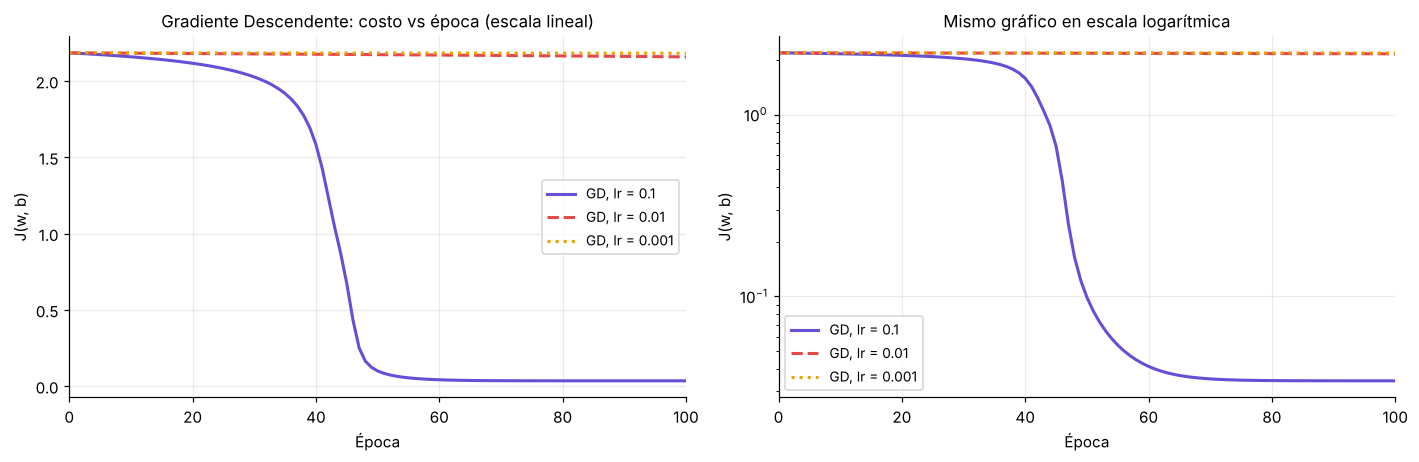

GD lr=0.1: J(época 40) = 1.58, J(época 50) = 0.099 | w cruza 0 en la época 45 | |grad| inicial = 0.146, máximo = 1.54 (época 46)


In [8]:
# --- Gráfico pedido: J vs época, los 3 learning rates superpuestos ---
gd_histories = {f"GD, lr = {lr}": models["GD"][lr].loss_history for lr in LRS}
gd_colors = {f"GD, lr = {lr}": COLOR_LR[lr] for lr in LRS}
gd_styles = {f"GD, lr = {lr}": LS_LR[lr] for lr in LRS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
plot_loss_curves(gd_histories, ax=axes[0], colors=gd_colors, linestyles=gd_styles,
                 title="Gradiente Descendente: costo vs época (escala lineal)")
plot_loss_curves(gd_histories, ax=axes[1], colors=gd_colors, linestyles=gd_styles, log_scale=True,
                 title="Mismo gráfico en escala logarítmica")
axes[0].legend(loc="center right")
plt.tight_layout(); plt.show()

# Datos que usamos en el análisis: dónde cruza w = 0 y cómo cambia el gradiente
w_ep, _ = epoch_params(models["GD"][0.1])
gd_grad = np.array([h["grad_norm"] for h in optimizers["GD"][0.1].history])
J_gd = np.array(models["GD"][0.1].loss_history)
print(f"GD lr=0.1: J(época 40) = {J_gd[40]:.2f}, J(época 50) = {J_gd[50]:.3f} | w cruza 0 en la época {np.argmax(w_ep > 0)}"
      f" | |grad| inicial = {gd_grad[0]:.3f}, máximo = {gd_grad.max():.2f} (época {gd_grad.argmax() + 1})")

Con lr = 0.1 es el único caso que converge, y la curva tiene forma de escalón. Durante unas 40 épocas casi no baja (de 2.18 a 1.58), entre la 40 y la 50 cae casi todo y después se queda quieto en 0.0343. En ningún momento el costo sube. En 1c se ve que ese valor final es, de hecho, el menor costo que alcanzó cualquier corrida.

El escalón se explica con el gradiente. Al principio la norma vale 0.146 porque la tanh está saturada, así que cada paso mueve los parámetros apenas 0.015. Cuando w se acerca a 0, el modelo sale de la saturación, el gradiente crece hasta cerca de 1.5 y ahí se acelera. El cruce de w = 0 (cuando la curva "se da vuelta") pasa en la época 45, justo en medio de la caída.

Con 0.01 y 0.001 hace el mismo camino, pero 10 y 100 veces más lento. Con 0.01, en 100 épocas llega a donde lr = 0.1 llegaba en 10 (J = 2.158). No está atrapado en un mínimo: le falta pendiente. Calculamos que necesitaría unas 500 épocas.

### 1b) Implementación de Adam (2 punto)  
- Implementar el algoritmo de Adam para minimizar \\( J(w, b) \\).  
- Utilizar 100 épocas y 3 diferentes learning rates `(0.1, 0.01, 0.001)`.
- Utilizar los mismos valores de \\( w \\) y \\( b \\) que se usaron para GD **(IMPORTANTE)**.
- Hacer 2 modelos, uno full-batch y otro con mini-batch.
- El batch size es a elección de ustedes, pero debe ser mayor o igual a 16.
- Graficar la función de Costo \\( J(w, b) \\) VS número de época para comparar cómo converge la función para ambos modelos y para los 3 learning rates. Deben haber 2 plots separados o 2 subplots, uno para las 3 gráficas de Adam full-batch y otro para las 3 gráficas de Adam mini-batch.

<br>

Al igual que para GD, ambas versiones del optimizador Adam también se deben implementar desde cero y paso a paso. Se pueden usar librerías como `numpy`, `scipy`, `matplotlib` o similares. Pero no está permitido usar PyTorch ni TensorFlow o frameworks que ya contengan el optimizador desarrollado.

#### Resolución 1b)

Implementamos Adam siguiendo el algoritmo 1 del paper (Kingma & Ba, 2015, https://arxiv.org/abs/1412.6980), con los valores por defecto β1 = 0.9, β2 = 0.999 y ε = 1e-8. La actualización es

$$
\theta_t = \theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}
$$

donde m es un promedio móvil del gradiente (inercia, memoria de unas 10 actualizaciones) y v uno del gradiente al cuadrado (escala, memoria de unas 1000). Lo que más nos sirvió para entender los resultados es que el cociente m/√v queda cerca de ±1 cuando el gradiente es consistente. Por eso Adam da pasos de tamaño parecido al lr, sea el gradiente grande o chico. GD, en cambio, da pasos de lr por gradiente.

`Adam` es otra subclase de `Optimizer`: solo implementa `_update`, y guarda m y v en diccionarios por nombre de parámetro (`"W"`, `"b"`). El recorrido de los datos es el de la clase base, así que los dos modelos salen de la misma clase cambiando solo `batch_size`. Full-batch (`batch_size=None`) usa las 512 muestras por paso, o sea 1 actualización por época. Mini-batch (`batch_size=32`, cumple el mínimo de 16 y es potencia de 2) da 16 actualizaciones por época. Algunas decisiones:

- Los datos se mezclan al empezar cada época y se recorren sin reemplazo, así cada muestra se usa una vez por época.
- El contador t de la corrección de sesgo es `step_count`, que es global y no se reinicia por época; si se reiniciara, la corrección volvería a inflar los pasos al arrancar cada época.
- El costo de cada época lo mide `NeuralNetwork` sobre el dataset completo, no como promedio de los lotes. Así es comparable con GD.
- Los dos parten de los mismos w0 y b0 de 1a.

Además, Adam agrega a `history` el valor de $\sqrt{\hat v}$ en cada paso, que usamos en 1d para explicar un frenado.

In [9]:
class Adam(Optimizer):
    """Adam (Kingma & Ba, 2015). m y v son promedios móviles del gradiente y de su cuadrado,
    guardados por nombre de parámetro. La corrección de sesgo usa `step_count`, el contador global
    de actualizaciones que incrementa `Optimizer.step` (no se reinicia por época)."""
    def __init__(self, learning_rate=0.001, batch_size=None, seed=None, beta1=BETA1, beta2=BETA2, eps=EPS):
        super().__init__(learning_rate, batch_size, seed)
        self.beta1, self.beta2, self.eps = beta1, beta2, eps
        self.m = {}       # 1er momento: promedio móvil del gradiente ("inercia" / dirección)
        self.v = {}       # 2do momento: promedio móvil del gradiente al cuadrado ("escala")
        self.v_hat = {}   # v con corrección de sesgo del último paso (para el diagnóstico)

    def _update(self, name, param, gradient):
        t = self.step_count
        self.m[name] = self.beta1 * self.m.get(name, 0.0) + (1 - self.beta1) * gradient
        self.v[name] = self.beta2 * self.v.get(name, 0.0) + (1 - self.beta2) * gradient ** 2
        m_hat = self.m[name] / (1 - self.beta1 ** t)          # corrección de sesgo
        self.v_hat[name] = self.v[name] / (1 - self.beta2 ** t)
        return param - self.learning_rate * m_hat / (np.sqrt(self.v_hat[name]) + self.eps)

    def _extra_log(self):
        return {"sqrt_v_hat": {name: np.sqrt(v_hat) for name, v_hat in self.v_hat.items()}}

In [10]:
# 1b) Adam full-batch y mini-batch: misma clase, solo cambia batch_size
for lr in LRS:
    optimizers["Adam full-batch"][lr] = Adam(learning_rate=lr)
    optimizers["Adam mini-batch"][lr] = Adam(learning_rate=lr, batch_size=BATCH_SIZE, seed=SEED_BATCH)
    for opt in ["Adam full-batch", "Adam mini-batch"]:
        models[opt][lr], times[opt][lr] = train_model(optimizers[opt][lr])
        w_ep, b_ep = epoch_params(models[opt][lr])
        print(f"{opt:<16} lr={lr:<6} J(época 100) = {models[opt][lr].loss_history[-1]:.5f}"
              f"  (w, b) final = ({w_ep[-1]:+.3f}, {b_ep[-1]:+.3f})  actualizaciones = {optimizers[opt][lr].step_count}")

Adam full-batch  lr=0.1    J(época 100) = 0.11280  (w, b) final = (+1.496, +0.204)  actualizaciones = 100


Adam mini-batch  lr=0.1    J(época 100) = 0.03452  (w, b) final = (+0.432, +0.064)  actualizaciones = 1600
Adam full-batch  lr=0.01   J(época 100) = 1.35955  (w, b) final = (-0.593, -1.742)  actualizaciones = 100


Adam mini-batch  lr=0.01   J(época 100) = 0.03432  (w, b) final = (+0.448, +0.083)  actualizaciones = 1600
Adam full-batch  lr=0.001  J(época 100) = 2.16493  (w, b) final = (-1.787, -0.523)  actualizaciones = 100


Adam mini-batch  lr=0.001  J(época 100) = 0.33390  (w, b) final = (+0.162, -0.439)  actualizaciones = 1600


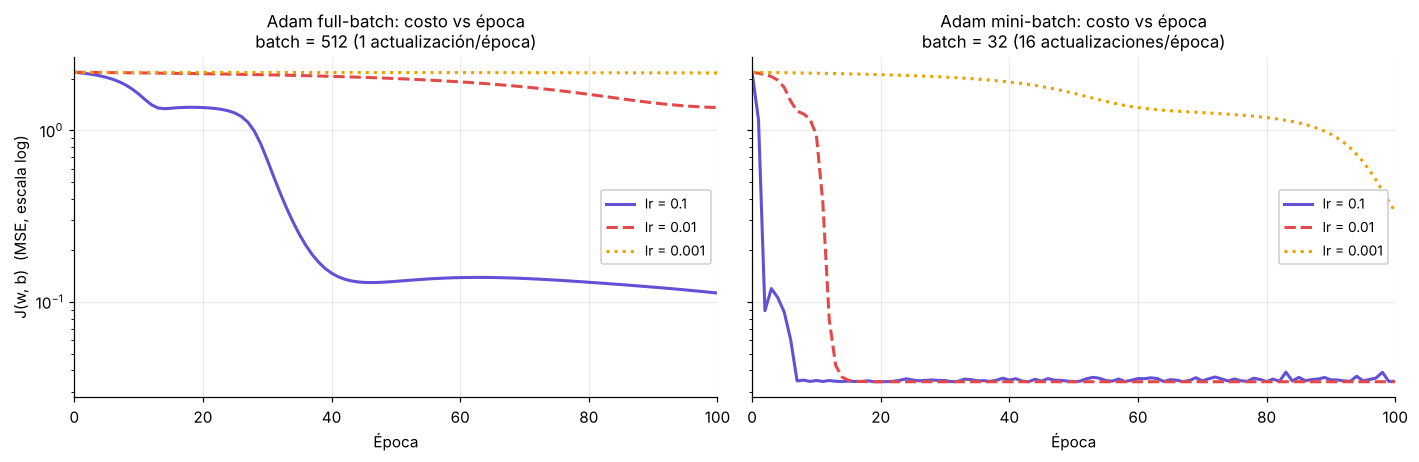

In [11]:
# --- Gráfico pedido: 2 subplots (Adam full-batch | Adam mini-batch), 3 learning rates cada uno ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, opt in zip(axes, ["Adam full-batch", "Adam mini-batch"]):
    histories = {f"lr = {lr}": models[opt][lr].loss_history for lr in LRS}
    extra = (f"batch = {N} (1 actualización/época)" if opt == "Adam full-batch"
             else f"batch = {BATCH_SIZE} ({N // BATCH_SIZE} actualizaciones/época)")
    plot_loss_curves(histories, ax=ax, log_scale=True, title=f"{opt}: costo vs época\n{extra}",
                     colors={f"lr = {lr}": COLOR_LR[lr] for lr in LRS},
                     linestyles={f"lr = {lr}": LS_LR[lr] for lr in LRS})
    ax.legend(loc="center right", framealpha=0.95)
axes[0].set_ylabel("J(w, b)  (MSE, escala log)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

Full-batch con lr = 0.1 arranca mucho más rápido que GD (en la época 13 ya está en 1.35, GD seguía en 2.15), se queda un rato en una meseta, vuelve a bajar y después se estanca cerca de 0.13. Termina en 0.113, más de tres veces lo que logra GD, en (1.50, 0.20), lejos de donde termina GD (0.45, 0.08). Al principio pensamos que era lentitud, pero en realidad se pasó del mínimo. Lo analizamos en 1d. Con 0.01 baja a ritmo constante hasta 1.36 y con 0.001 casi no se mueve.

Mini-batch con lr = 0.1 es lo más rápido de todo el TP: en la época 2 ya hizo el 90% de la bajada. Pero no se queda quieto: oscila alrededor de 0.035 y en 47 de las 100 épocas el costo sube respecto de la anterior. Con 0.01 queda el mejor resultado: llega en 12-14 épocas y termina en el mismo costo que GD con 0.1, sin oscilación visible. Con 0.001 todavía está bajando en la época 100 (0.334).

Hay una cuenta simple que explica casi todo el cuadro. Si Adam avanza más o menos lr por paso, para que w vaya de -1.89 a 0.45 (2.34 de distancia) hacen falta del orden de 2.34/lr pasos: 23 con 0.1, 234 con 0.01 y 2340 con 0.001. Full-batch tiene 100 pasos y mini-batch 1600. Con eso se ve quién puede llegar y quién no. Es condición necesaria, no suficiente: full-batch con 0.1 tiene pasos de sobra y aun así termina lejos.

### 1c) Comparativa de optimizadores (0.5 puntos)  
- Comparar el resultado y rendimiento de GD VS Adam (full-batch) VS Adam (mini-batch) para cada uno de los learning rates por separado. Hacerlo con gráficas y tablas. Deben haber 3 plots o 3 subplots, uno para cada learning rate. Y las leyendas deben diferenciar al optimizador por color.
- Graficar el dataset original sintético (y(x)) y compararlo con la función hallada por el modelo, para ver si efectivamente el modelo logró deducir un patrón no lineal parecido al patrón no lineal escogido para el dataset. Hacerlo para cada optimizador y cada learning rate en un plot grande de 9 subplots.
- Redactar conclusiones analíticas que resalten las diferencias entre cada optimizador. No solo deben comparar el resultado final del costo, sino también la velocidad de convergencia y otros aspectos que consideren relevantes. Le voy a tomar mucha importancia a este último punto, así que su análisis debe ser claro, detallado y con criterio acorde a los resultados obtenidos.

#### Resolución 1c)

Comparamos por learning rate, primero contando épocas y después contando actualizaciones, porque mini-batch da 16 pasos por época y nos parecía injusto mirar solo épocas. También repetimos todo con 500 inicializaciones para ver qué cosas se sostienen.

Para decir si un optimizador "llegó" necesitamos una referencia. Usamos $J_{ref}$, el menor costo observado en cualquier época de cualquiera de los 9 entrenamientos, y sus (w, b). Es una referencia empírica: sale de los propios entrenamientos. En el addendum verificamos con segundas derivadas que coincide con el mínimo global de $J$, así que en lo que sigue "converger" quiere decir llegar a $J_{ref}$.

En la tabla: "brecha vs J_ref" es cuánto quedó por encima de la referencia. "Época 90%" es cuándo logró el 90% de la bajada posible. "Época estable" es desde cuándo J ya no vuelve a salir del 10% sobre $J_{ref}$ (así penalizamos llegar y después irse). "Épocas con J en subida" cuenta oscilación o ruido. R² negativo significa peor que predecir siempre la media.

J_ref = 0.03431  (R² = 0.8972), alcanzado por Adam mini-batch con lr = 0.01 en la época 23  ->  (w_ref, b_ref) = (0.4468, 0.0800)


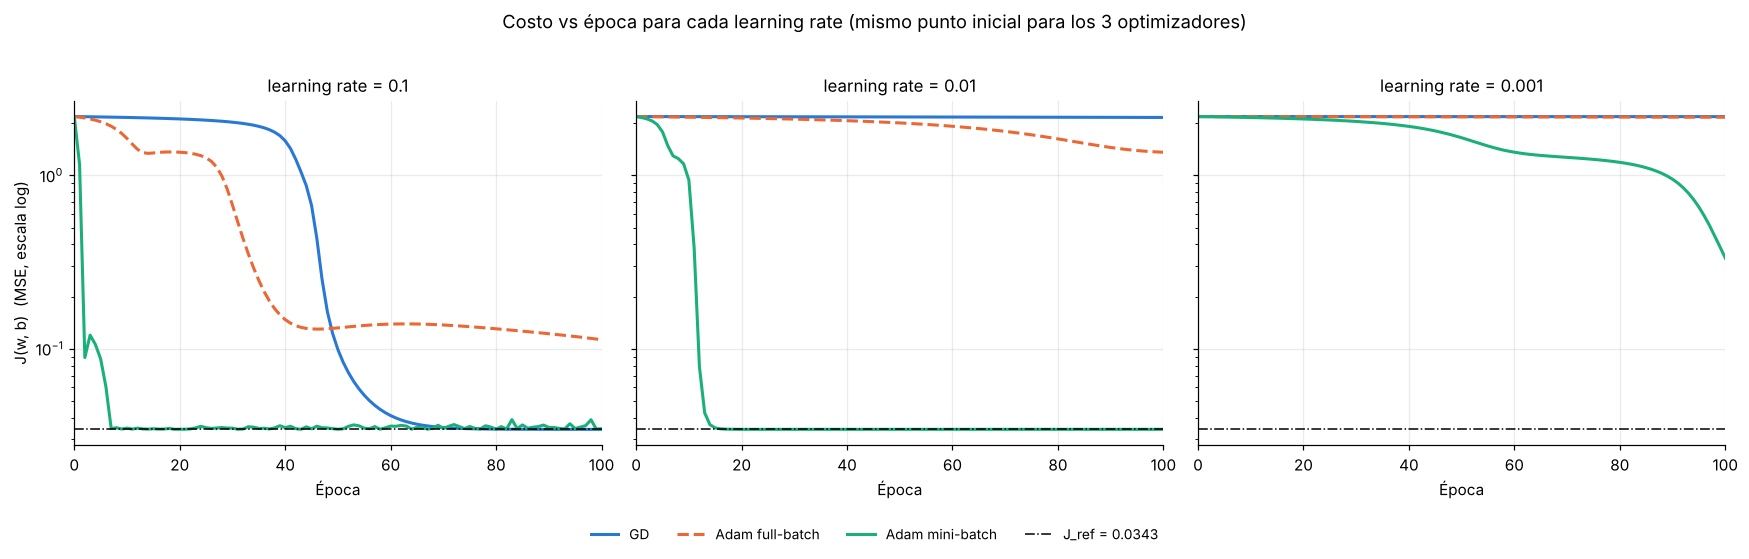

In [12]:
# Referencia empírica: el menor costo observado en TODOS los entrenamientos (cualquier optimizador, lr y época)
def find_best_observed(models):
    """Recorre todas las redes entrenadas y devuelve la época con menor costo:
    cuánto vale, quién la alcanzó (optimizador, lr, época) y los parámetros (W, b) en ese momento."""
    best = {"loss": np.inf}
    for opt in OPTS:
        for lr in LRS:
            model = models[opt][lr]
            best_epoch = int(np.argmin(model.loss_history))
            best_loss = model.loss_history[best_epoch]
            if best_loss < best["loss"]:
                W_at_best, b_at_best = model.param_history[best_epoch]
                best = {"loss": best_loss, "optimizer": opt, "learning_rate": lr, "epoch": best_epoch,
                        "W": W_at_best, "b": b_at_best}
    return best

best_observed = find_best_observed(models)
J_REF = best_observed["loss"]
ref_model = NeuralNetwork(X, Y, best_observed["W"], best_observed["b"])   # el mejor ajuste observado, para los gráficos
W_REF = ref_model.W[0, 0]
B_REF = ref_model.b[0]
R2_REF = 1 - J_REF / y.var()
print(f"J_ref = {J_REF:.5f}  (R² = {R2_REF:.4f}), alcanzado por {best_observed['optimizer']} "
      f"con lr = {best_observed['learning_rate']} en la época {best_observed['epoch']}"
      f"  ->  (w_ref, b_ref) = ({W_REF:.4f}, {B_REF:.4f})")

# 1c) Comparativa por learning rate: GD vs Adam full-batch vs Adam mini-batch
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, lr in zip(axes, LRS):
    plot_loss_curves({opt: models[opt][lr].loss_history for opt in OPTS}, ax=ax, log_scale=True,
                     colors=COLOR_OPT, linestyles=LS_OPT, reference=J_REF, title=f"learning rate = {lr}")
    ax.get_legend().remove()
axes[0].set_ylabel("J(w, b)  (MSE, escala log)"); axes[1].set_ylabel(""); axes[2].set_ylabel("")
fig.suptitle("Costo vs época para cada learning rate (mismo punto inicial para los 3 optimizadores)", y=1.02)
plt.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()

In [13]:
# --- Tabla de métricas: resultado final, velocidad y estabilidad ---
def epoch_90(J):
    """Primera época en la que se logró el 90% de la reducción posible (de J0 hasta J_ref)."""
    threshold = J_REF + 0.10 * (J[0] - J_REF)
    k = np.flatnonzero(J <= threshold)
    return int(k[0]) if k.size else np.nan

def stable_epoch(J, tol=1.10):
    """Primera época a partir de la cual J queda SIEMPRE dentro de +10% de J_ref (llegó y no se fue)."""
    outside = np.flatnonzero(J > tol * J_REF)
    if outside.size == 0:
        return 0
    return int(outside[-1] + 1) if outside[-1] + 1 < J.size else np.nan

rows = []
for lr in LRS:
    for opt in OPTS:
        J = np.array(models[opt][lr].loss_history)
        w_ep, b_ep = epoch_params(models[opt][lr])
        rows.append({
            "lr": str(lr), "optimizador": opt,
            "J final": J[-1],
            "brecha vs J_ref (%)": 100 * (J[-1] / J_REF - 1),
            "R² final": 1 - J[-1] / y.var(),
            "época 90% reducción": epoch_90(J),
            "época estable (J ≤ 1.1·J_ref)": stable_epoch(J),
            "épocas con J en subida": int(np.sum(np.diff(J) > 1e-12)),
            "actualizaciones": optimizers[opt][lr].step_count,
            "w final": w_ep[-1], "b final": b_ep[-1],
            "dist. a (w_ref, b_ref)": np.hypot(w_ep[-1] - W_REF, b_ep[-1] - B_REF),
            "tiempo (ms)": times[opt][lr],
        })
table = pd.DataFrame(rows).set_index(["lr", "optimizador"])
fmt = {"J final": "{:.5f}", "brecha vs J_ref (%)": lambda v: f"{round(v, 1) + 0.0:.1f}", "R² final": lambda v: f"{round(v, 3) + 0.0:.3f}",
       "época 90% reducción": lambda v: "no alcanza" if np.isnan(v) else f"{int(v)}",
       "época estable (J ≤ 1.1·J_ref)": lambda v: "no alcanza" if np.isnan(v) else f"{int(v)}",
       "w final": "{:+.3f}", "b final": "{:+.3f}", "dist. a (w_ref, b_ref)": "{:.3f}", "tiempo (ms)": "{:.1f}"}
print(f"Referencia: J_ref = {J_REF:.5f}, (w_ref, b_ref) = ({W_REF:.3f}, {B_REF:.3f}), R² = {R2_REF:.3f}. "
      f"Punto inicial: (w0, b0) = ({W0:.3f}, {B0:.3f}), J0 = {start_model.loss():.4f}")
display(table.style.format(fmt))

Referencia: J_ref = 0.03431, (w_ref, b_ref) = (0.447, 0.080), R² = 0.897. Punto inicial: (w0, b0) = (-1.890, -0.414), J0 = 2.1842


En los 9 gráficos agregamos, además de los datos y de la curva real, el mejor ajuste observado (punteado, el modelo en $(w_{ref}, b_{ref})$). La distancia entre la curva de color y la punteada es error del optimizador; la distancia entre la punteada y la negra es error del modelo.

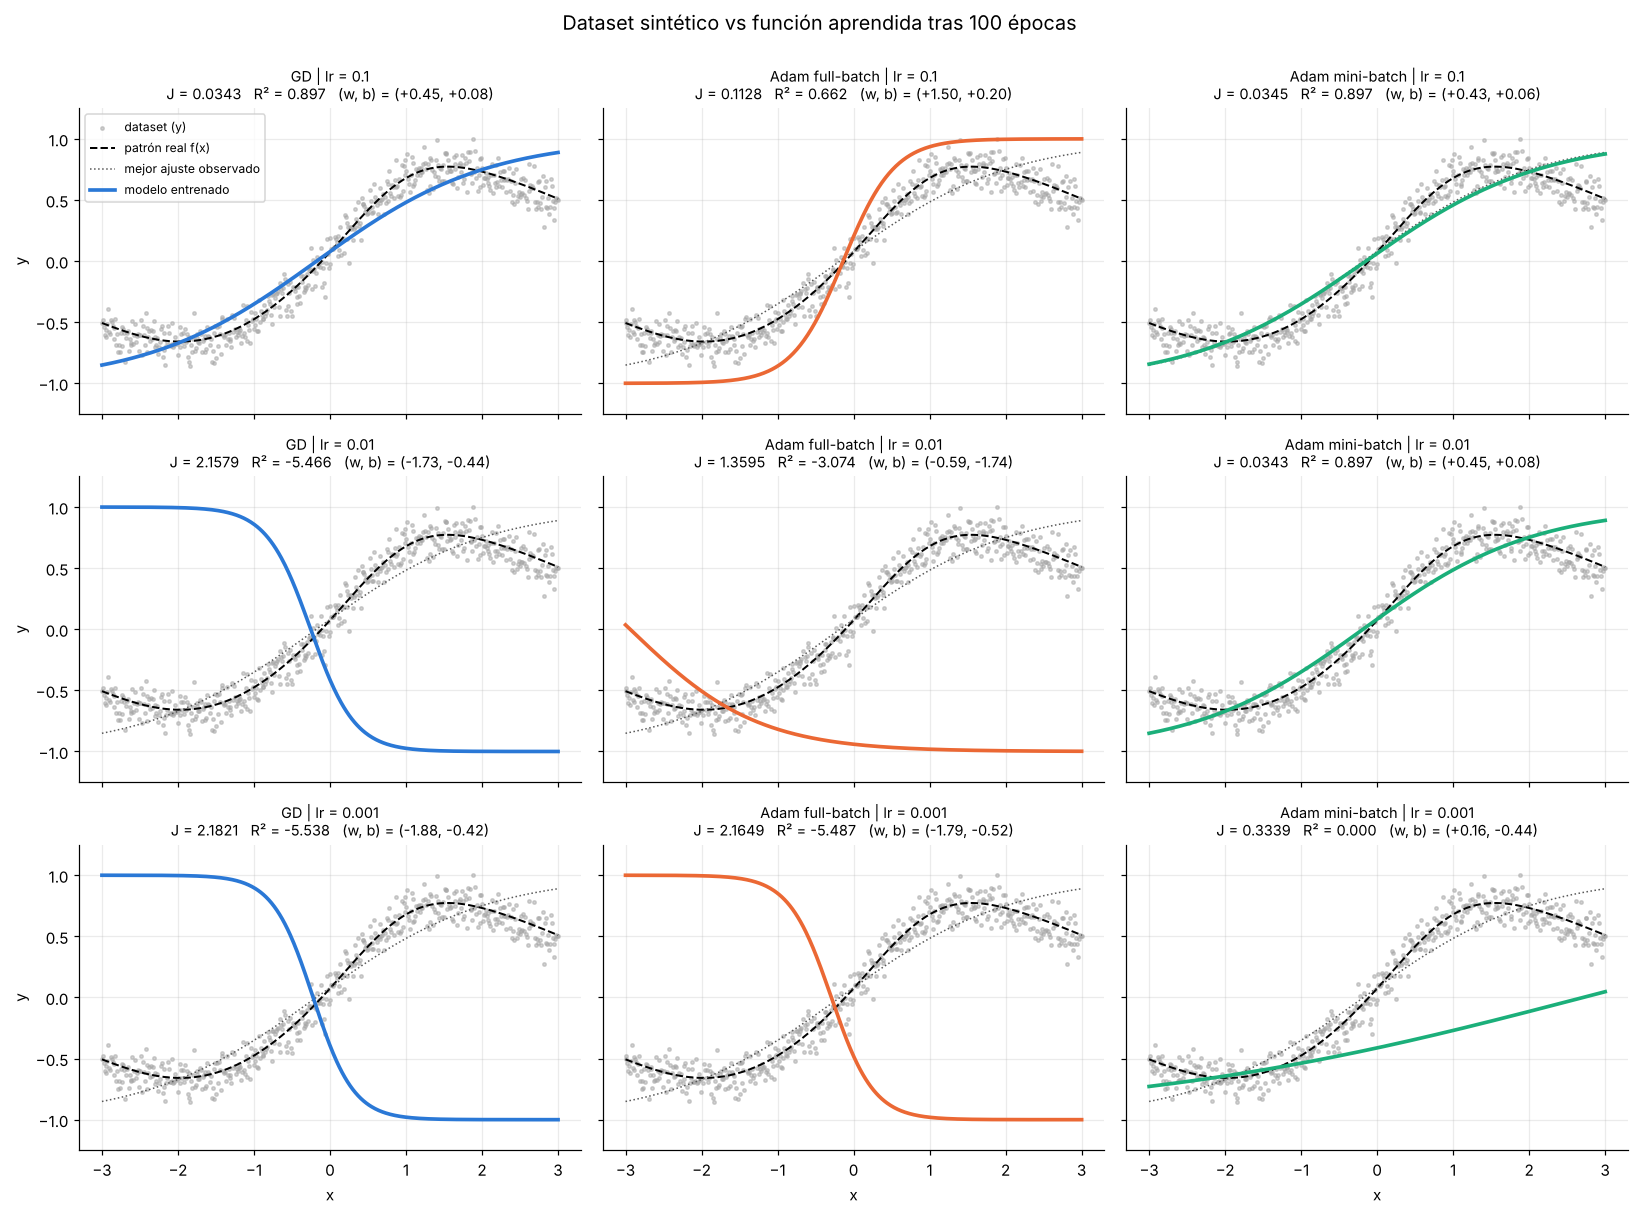

In [14]:
# --- 9 subplots: dataset vs función hallada, para cada optimizador (columnas) y learning rate (filas) ---
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True, sharey=True)
for i, lr in enumerate(LRS):
    for j, opt in enumerate(OPTS):
        model = models[opt][lr]
        w_ep, b_ep = epoch_params(model)
        R2 = round(1 - model.loss_history[-1] / y.var(), 3) + 0.0   # (+0.0 evita imprimir "-0.000")
        plot_fit(model, ax=axes[i, j], color=COLOR_OPT[opt], true_fn=f_true, reference_model=ref_model,
                 title=f"{opt} | lr = {lr}\nJ = {model.loss_history[-1]:.4f}   R² = {R2:.3f}   "
                       f"(w, b) = ({w_ep[-1]:+.2f}, {b_ep[-1]:+.2f})")
        axes[i, j].title.set_fontsize(9.5)
        axes[i, j].set_ylim(-1.25, 1.25)
        if i < 2: axes[i, j].set_xlabel("")
        if j > 0: axes[i, j].set_ylabel("")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Dataset sintético vs función aprendida tras 100 épocas", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

Por época, los tres procesan las mismas 512 muestras, pero mini-batch actualiza 16 veces y los otros una. Queríamos saber si mini-batch gana porque da mejores pasos o solamente porque da más, así que graficamos el costo contra la cantidad de actualizaciones, usando la trayectoria que guarda cada optimizador en `history`.

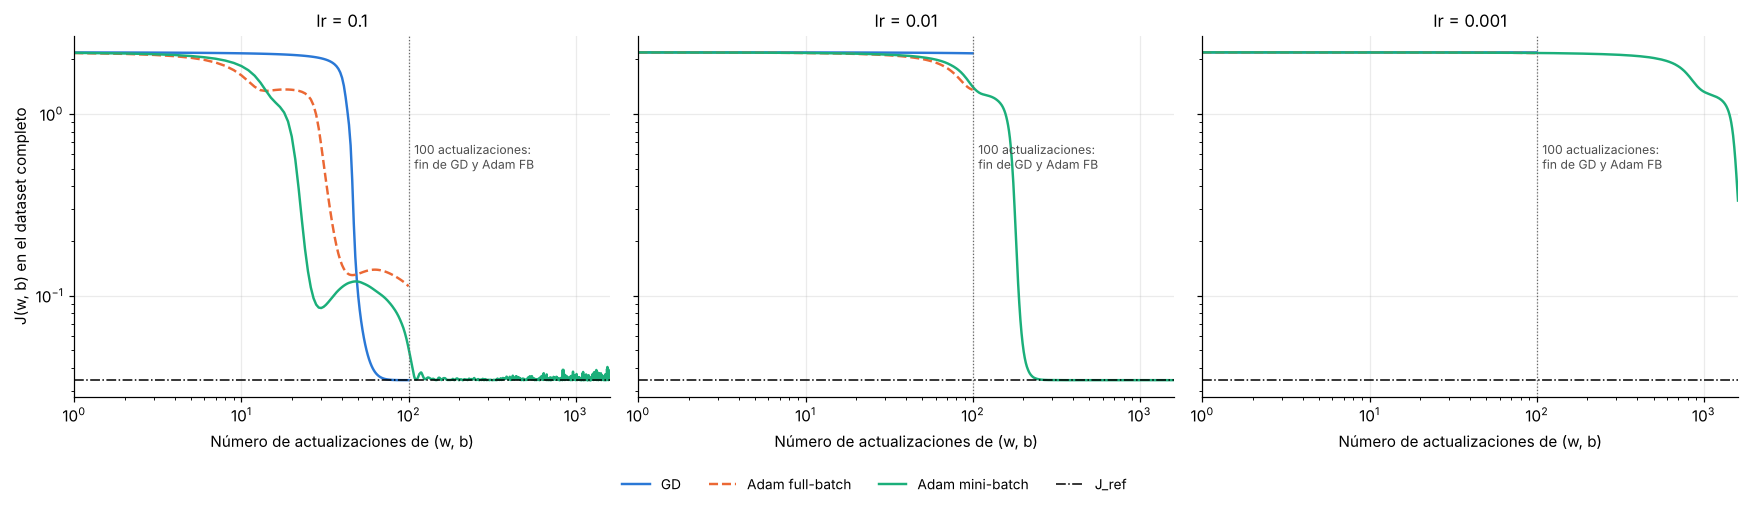

lr=0.1    tras 100 actualizaciones:  GD = 0.0343 | Adam FB = 0.1128 | Adam MB = 0.0513 (solo ~6 épocas)
lr=0.01   tras 100 actualizaciones:  GD = 2.1579 | Adam FB = 1.3595 | Adam MB = 1.4139 (solo ~6 épocas)
lr=0.001  tras 100 actualizaciones:  GD = 2.1821 | Adam FB = 2.1649 | Adam MB = 2.1677 (solo ~6 épocas)


In [15]:
# --- Mirada complementaria: costo vs NÚMERO DE ACTUALIZACIONES (no vs épocas) ---
def cost_per_update(opt, lr):
    """J sobre el dataset completo después de cada actualización (posición 0 = punto inicial)."""
    model = models[opt][lr]
    return cost_along(model, *update_path(model, optimizers[opt][lr]))

J_per_update = {(opt, lr): cost_per_update(opt, lr) for opt in OPTS for lr in LRS}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, lr in zip(axes, LRS):
    for opt in OPTS:
        Jk = J_per_update[(opt, lr)]
        ax.plot(np.arange(1, Jk.size), Jk[1:], color=COLOR_OPT[opt], ls=LS_OPT[opt], label=opt, lw=1.6)
    ax.axhline(J_REF, color="k", lw=1, ls="-.", label="J_ref")
    ax.axvline(EPOCHS, color="0.4", lw=0.8, ls=":")
    ax.text(EPOCHS * 1.08, 0.5, "100 actualizaciones:\nfin de GD y Adam FB", fontsize=8, color="0.3")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1, N // BATCH_SIZE * EPOCHS)
    ax.set_title(f"lr = {lr}"); ax.set_xlabel("Número de actualizaciones de (w, b)")
axes[0].set_ylabel("J(w, b) en el dataset completo")
plt.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()

for lr in LRS:
    print(f"lr={lr:<6} tras 100 actualizaciones:  GD = {J_per_update[('GD', lr)][EPOCHS]:.4f} | "
          f"Adam FB = {J_per_update[('Adam full-batch', lr)][EPOCHS]:.4f} | "
          f"Adam MB = {J_per_update[('Adam mini-batch', lr)][EPOCHS]:.4f} (solo ~6 épocas)")

Para ver si lo de la semilla 35 se generaliza, repetimos los 9 experimentos con 500 inicializaciones (seed s + randn, igual que en 1a, con s de 0 a 499). Cada corrida de mini-batch tiene además su propio mezclado (semilla 10000 + s). Usamos las mismas clases que en 1a y 1b, sin una versión aparte: así lo que se mide es exactamente lo que se implementó. Son 4500 entrenamientos con un bucle de Python por actualización, que uno detrás de otro tardan unos 3 minutos. Como cada corrida es independiente de las demás, las repartimos entre los núcleos del procesador con `joblib`: cada corrida sigue siendo la misma función, solo cambia quién la ejecuta. La aceleración depende de cuántos núcleos haya (en Colab suelen ser 2).

Inicializaciones: 48% arrancan con w0 < 0 (curva invertida) | 45% arrancan con J0 > 1 | la semilla 35 tiene J0 = 2.184 (percentil 99%)


4500 entrenamientos completados en 122 s usando 2 núcleos
Control: con la semilla 35, el loop reproduce exactamente GD y Adam full-batch de 1a/1b


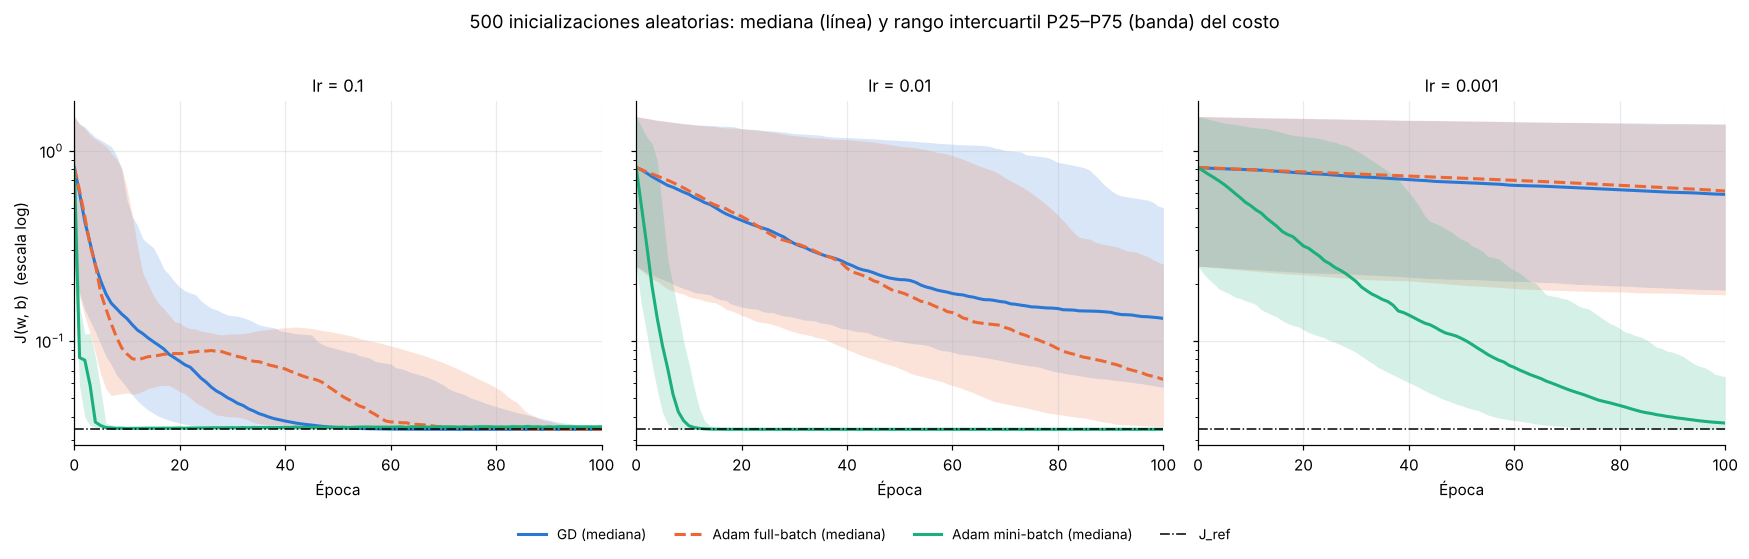

In [16]:
# Robustez: ¿las conclusiones dependen del punto inicial? -> 500 inicializaciones np.random.randn()
import os
from joblib import Parallel, delayed

def make_optimizer(opt, lr, shuffle_seed=SEED_BATCH):
    """Crea el optimizador `opt` ("GD", "Adam full-batch" o "Adam mini-batch") con learning rate `lr`."""
    if opt == "GD":
        return GradientDescent(learning_rate=lr)
    if opt == "Adam full-batch":
        return Adam(learning_rate=lr)
    return Adam(learning_rate=lr, batch_size=BATCH_SIZE, seed=shuffle_seed)

# 500 inicializaciones distintas, cada una generada exactamente como en 1a (np.random.seed + np.random.randn)
SEEDS = np.arange(500)
inits = []
for s in SEEDS:
    np.random.seed(s)
    inits.append((np.random.randn(*W_shape), np.random.randn(*b_shape)))
J0s = np.array([loss_at(start_model, w_s, b_s) for w_s, b_s in inits])
W0s = np.array([w_s[0, 0] for w_s, _ in inits])
print(f"Inicializaciones: {np.mean(W0s < 0):.0%} arrancan con w0 < 0 (curva invertida) | "
      f"{np.mean(J0s > 1):.0%} arrancan con J0 > 1 | la semilla {SEED_INIT} tiene J0 = {start_model.loss():.3f} "
      f"(percentil {np.mean(J0s < start_model.loss()):.0%})")

def loss_curve(opt, lr, seed, w_init, b_init):
    """Una corrida completa: entrena desde (w_init, b_init) y devuelve solo su costo por época."""
    model_s, _ = train_model(make_optimizer(opt, lr, shuffle_seed=10_000 + seed), w_init, b_init)
    return model_s.loss_history

def robustness_curves(opt, lr):
    """Entrena las 500 inicializaciones con un mismo optimizador y lr, y devuelve una matriz (500, 101)
    con el costo por época de cada corrida. Las corridas son independientes entre sí, así que joblib
    las reparte entre los núcleos disponibles: cada una es la misma `loss_curve` que se usaría en un for."""
    trainings = [delayed(loss_curve)(opt, lr, seed, w_init, b_init)
                 for seed, (w_init, b_init) in zip(SEEDS, inits)]
    return np.array(Parallel(n_jobs=-1)(trainings))   # Parallel devuelve los resultados en el mismo orden

t0 = time.perf_counter()
multi = {}   # (optimizador, lr) -> matriz (500, 101) con el costo por época de cada corrida
for lr in LRS:
    for opt in OPTS:
        multi[(opt, lr)] = robustness_curves(opt, lr)
elapsed = time.perf_counter() - t0
n_trainings = len(SEEDS) * len(LRS) * len(OPTS)
print(f"{n_trainings} entrenamientos completados en {elapsed:.0f} s usando {os.cpu_count()} núcleos")

# Control: la semilla 35 dentro del loop reproduce las corridas de 1a/1b (GD y Adam FB no dependen del mezclado)
for opt in ["GD", "Adam full-batch"]:
    assert all(np.array_equal(multi[(opt, lr)][SEED_INIT], models[opt][lr].loss_history) for lr in LRS)
print(f"Control: con la semilla {SEED_INIT}, el loop reproduce exactamente GD y Adam full-batch de 1a/1b")

rows = []
for lr in LRS:
    finals = np.stack([multi[(opt, lr)][:, -1] for opt in OPTS])     # (3, 500)
    winner = np.argmin(finals, axis=0)
    for k, opt in enumerate(OPTS):
        Jm = multi[(opt, lr)]; Jf = Jm[:, -1]
        stable = np.array([stable_epoch(Ji) for Ji in Jm])
        rows.append({"lr": str(lr), "optimizador": opt,
                     "J final mediana": np.median(Jf),
                     "J final P25": np.percentile(Jf, 25), "J final P75": np.percentile(Jf, 75),
                     "% corridas en J ≤ 1.1·J_ref": 100 * np.mean(Jf <= 1.10 * J_REF),
                     "época estable (mediana de las que llegan)": np.nanmedian(stable) if np.any(~np.isnan(stable)) else np.nan,
                     "% corridas donde es el mejor de los 3": 100 * np.mean(winner == k)})
table_multi = pd.DataFrame(rows).set_index(["lr", "optimizador"])
display(table_multi.style.format({"J final mediana": "{:.4f}", "J final P25": "{:.4f}", "J final P75": "{:.4f}",
                                  "% corridas en J ≤ 1.1·J_ref": "{:.0f}", "% corridas donde es el mejor de los 3": "{:.0f}",
                                  "época estable (mediana de las que llegan)": lambda v: "—" if np.isnan(v) else f"{v:.0f}"}))

ep = np.arange(EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, lr in zip(axes, LRS):
    for opt in OPTS:
        p25, p50, p75 = np.percentile(multi[(opt, lr)], [25, 50, 75], axis=0)
        ax.fill_between(ep, p25, p75, color=COLOR_OPT[opt], alpha=0.18, lw=0)
        ax.plot(ep, p50, color=COLOR_OPT[opt], ls=LS_OPT[opt], label=f"{opt} (mediana)")
    ax.axhline(J_REF, color="k", lw=1, ls="-.", label="J_ref")
    ax.set_yscale("log"); ax.set_xlim(0, EPOCHS); ax.set_xlabel("Época"); ax.set_title(f"lr = {lr}")
axes[0].set_ylabel("J(w, b)  (escala log)")
fig.suptitle("500 inicializaciones aleatorias: mediana (línea) y rango intercuartil P25–P75 (banda) del costo", y=1.02)
plt.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()

### Conclusiones 1c

Lo primero que sacamos es que no hay un ganador fijo: depende del learning rate. Con 0.1, GD termina exacto en $J_{ref}$ y Adam mini-batch casi (0.6% arriba), mientras que Adam full-batch queda 229% arriba por el sobrepaso. Con 0.01 solo llega mini-batch; GD casi no se mueve (2.158) y full-batch queda a mitad de camino (1.360). Con 0.001 no llega ninguno, aunque mini-batch avanza bastante (0.334).

En los 9 gráficos, las tres corridas que convergen quedan pegadas al mejor ajuste observado, y las tres fallan en lo mismo: no siguen el máximo cerca de 1.5 ni la bajada posterior. Eso es límite de una sola neurona, no del optimizador (en el addendum cuantificamos cuánto del error es del modelo y cuánto del ruido). Las corridas que no salieron de la meseta muestran la S invertida, con R² cerca de -5.5.

Sobre velocidad: depende de en qué unidad se mida. Por épocas mini-batch gana lejos (90% de la bajada en la época 2 con lr 0.1, contra 48 de GD). Pero contando actualizaciones la ventaja casi desaparece: con 100 pasos y lr 0.01, mini-batch llega a 1.41 y full-batch a 1.36, prácticamente igual. Es decir, un paso calculado con 32 muestras vale casi lo mismo que uno con 512, y mini-batch gana porque con el mismo cómputo por época da 16 pasos. Nos parece el argumento más concreto a favor de mini-batch que sacamos del TP. En tiempo de reloj, nuestro mini-batch tarda unas 10 veces más por época, pero es por el bucle de Python sobre los lotes, no por hacer más cuentas.

GD es lento de una manera particular: avanza lr por la pendiente, entonces en la meseta inicial pasó 40 épocas casi quieto. Adam no tiene ese problema porque su paso no depende del tamaño del gradiente.

Sobre estabilidad: GD fue el único monótono en todos los casos. Con estos lr está lejos del límite en el que GD empieza a oscilar cerca del mínimo (en el addendum lo calculamos con la curvatura: haría falta un lr mayor a 1.76). Full-batch con 0.1 oscila (21 épocas con subida) por la inercia. Mini-batch tiene un ruido que no se va con lr fijo: con 0.1 el costo flota entre 0.0344 y 0.039; con 0.01 el ruido es diez veces menor. Para eliminarlo habría que bajar el lr a medida que avanzan las épocas.

Sobre el lr en general: en GD la velocidad es lr por pendiente; en Adam es más o menos lr. O sea que Adam saca la dependencia con la escala del gradiente, pero no con el learning rate. Con 100 pasos y lr 0.01, full-batch recorrió 1.30 en w y necesitaba 2.34.

Las 500 semillas nos obligaron a corregir una conclusión. La semilla 35 resultó estar en el percentil 99 de costo inicial, o sea, es de las más difíciles. Con lr 0.1, en el caso típico convergen los tres; GD y full-batch rinden parecido (77% y 80% de corridas llegan cerca de $J_{ref}$). Mini-batch llega más seguido (91%) y más rápido, pero solo en el 8% es el que termina más bajo, porque su ruido lo deja en 0.0354. Entonces lo de "full-batch es peor que GD con 0.1" es de esta semilla y no lo generalizaríamos. Con 0.01 mini-batch llega en el 100% de las corridas, full-batch en el 31% y GD en el 5%. Con 0.001 solo mini-batch se acerca (52%). Lo que sí se sostiene es el orden de robustez: mini-batch, después full-batch, después GD.

Para este problema nos quedaríamos con Adam mini-batch y lr 0.01: llega desde todos los arranques que probamos, en unas 10-14 épocas y sin ruido apreciable. GD con 0.1 termina igual de bien y es más simple, pero bajar el lr diez veces o arrancar en una meseta lo deja quieto. Imaginamos que en una red con millones de parámetros, cada uno con gradientes de escala distinta, la ventaja de Adam pesa todavía más que acá.

### 1d) Visualización en 3D de la trayectoria de aprendizaje (0.5 puntos)
- Graficar en 3D la trayectoria del aprendizaje de los 3 optimizadores sobre la superficie de la función de costo \\( J(w, b) \\). Se debe elegir un solo learning rate, el que consideres que se nota mejor la diferencia.
- Las 3 trayectorias deben estar en la misma superficie 3D y empezar en el mismo punto.
- Recomiendo utilizar `mpl_toolkits.mplot3d` y `np.meshgrid`, pero queda a su criterio la elección de funciones a usar para lograr el gráfico. También si desean pueden hacer que el gráfico sea animado usando `matplotlib.animation` y `IPython.display`.
- Comparar y redactar cómo se mueven en el espacio de parámetros y qué diferencias existen en la convergencia. La comparación debe ser clara y detallada.

#### Resolución 1d)

Antes de dibujar las trayectorias quisimos ver cómo es el terreno. Evaluamos $J$ y $|\nabla J|$ en una grilla con la misma `NeuralNetwork` (funciones `cost_surface` y `gradient_norm_surface`) y marcamos las mesetas: zonas con pendiente casi nula y costo alto. El análisis de curvatura (dónde la superficie deja de ser convexa) lo hicimos con el Hessiano y está en el addendum.

|grad J| en el punto inicial = 0.146  vs  mediana en la ventana = 0.242  vs  máximo = 2.47


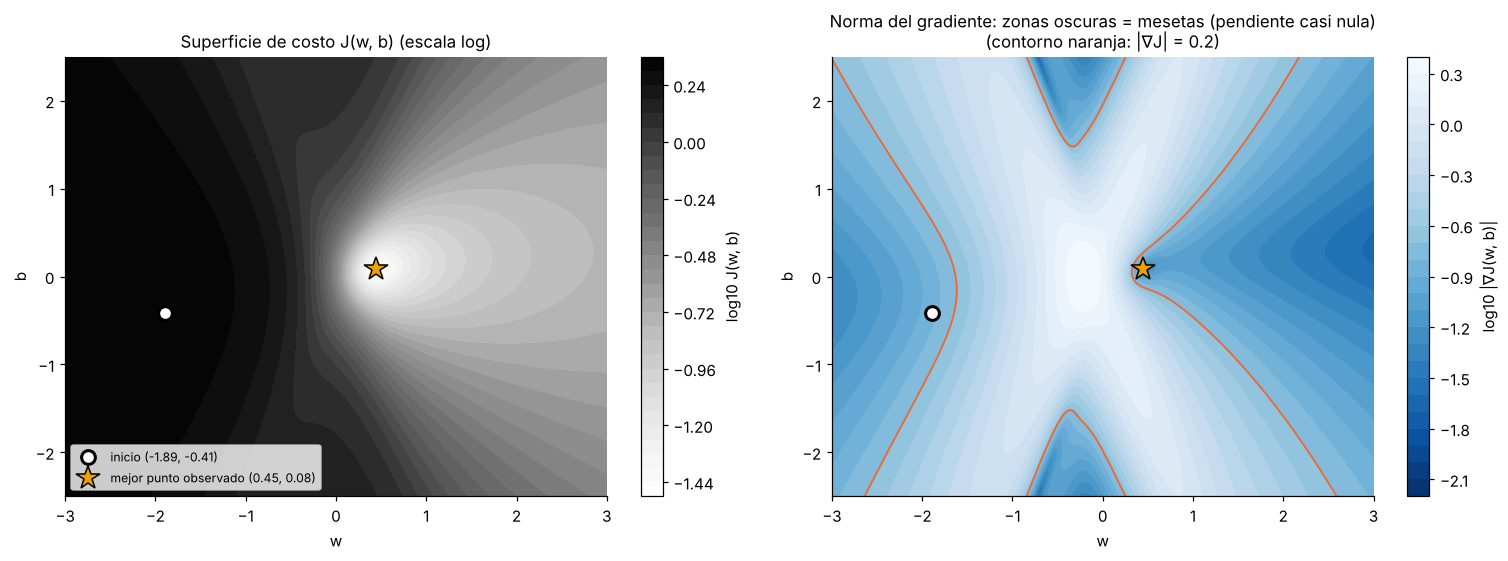

In [17]:
# 1d) Antes de la trayectoria: ¿cómo es el "terreno" J(w, b)?
w_lin = np.linspace(-3, 3, 241); b_lin = np.linspace(-2.5, 2.5, 201)
W_land, B_land = np.meshgrid(w_lin, b_lin)
J_land = cost_surface(start_model, W_land, B_land)
G_land = gradient_norm_surface(start_model, W_land, B_land)

print(f"|grad J| en el punto inicial = {Optimizer._norm(start_model.gradients(start_model.X, start_model.y)):.3f}"
      f"  vs  mediana en la ventana = {np.median(G_land):.3f}  vs  máximo = {G_land.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
cf = axes[0].contourf(W_land, B_land, np.log10(J_land), levels=30, cmap="Greys")
plt.colorbar(cf, ax=axes[0], label="log10 J(w, b)")
axes[0].set_title("Superficie de costo J(w, b) (escala log)")
im = axes[1].contourf(W_land, B_land, np.log10(G_land + 1e-12), levels=30, cmap="Blues_r")
plt.colorbar(im, ax=axes[1], label="log10 |∇J(w, b)|")
axes[1].contour(W_land, B_land, G_land, levels=[0.2], colors="#eb6834", linewidths=1.2)
axes[1].set_title("Norma del gradiente: zonas oscuras = mesetas (pendiente casi nula)\n(contorno naranja: |∇J| = 0.2)")
for a in axes:
    a.plot(W0, B0, "o", ms=9, mfc="white", mec="k", mew=2, label=f"inicio ({W0:.2f}, {B0:.2f})")
    a.plot(W_REF, B_REF, "*", ms=16, color="#eda100", mec="k", label=f"mejor punto observado ({W_REF:.2f}, {B_REF:.2f})")
    a.set_xlabel("w"); a.set_ylabel("b"); a.grid(False)
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

Hay mesetas en los cuatro lados y todas vienen de la saturación de la tanh. A la izquierda está el modelo invertido y saturado (J cerca de 2.2), que es donde arrancamos. A la derecha la tanh se vuelve casi un escalón (J entre 0.12 y 0.14). Arriba y abajo, con |b| grande, la salida queda clavada en ±1. En el medio hay un canal con gradientes de hasta 2.5. El punto inicial tiene gradiente 0.146, por debajo de la mediana de la ventana (0.24). En el addendum se ve además que casi toda esta ventana es no convexa: lo único con forma de pozo es una isla alrededor del mínimo.

Para elegir el lr del 3D no quisimos hacerlo a ojo. Para cada lr calculamos la distancia promedio, época a época, entre las posiciones de cada par de optimizadores, y nos quedamos con el de mayor separación.

In [18]:
# --- ¿Qué learning rate muestra mejor la diferencia? Lo medimos en vez de elegir "a ojo" ---
# Separación = distancia promedio (a lo largo de las 101 épocas) entre las posiciones (w, b) de cada par de optimizadores.
def separation(lr):
    positions = {opt: np.column_stack(epoch_params(models[opt][lr])) for opt in OPTS}
    pairs = [(OPTS[i], OPTS[j]) for i in range(3) for j in range(i + 1, 3)]
    return np.mean([np.linalg.norm(positions[a] - positions[b], axis=1).mean() for a, b in pairs])

sep = {lr: separation(lr) for lr in LRS}
for lr in LRS:
    print(f"lr = {lr:<6} separación media entre trayectorias = {sep[lr]:.3f}")
LR_3D = max(sep, key=sep.get)
print(f"\n-> Learning rate elegido para la visualización 3D: {LR_3D}")

lr = 0.1    separación media entre trayectorias = 1.355
lr = 0.01   separación media entre trayectorias = 1.653
lr = 0.001  separación media entre trayectorias = 0.749

-> Learning rate elegido para la visualización 3D: 0.01


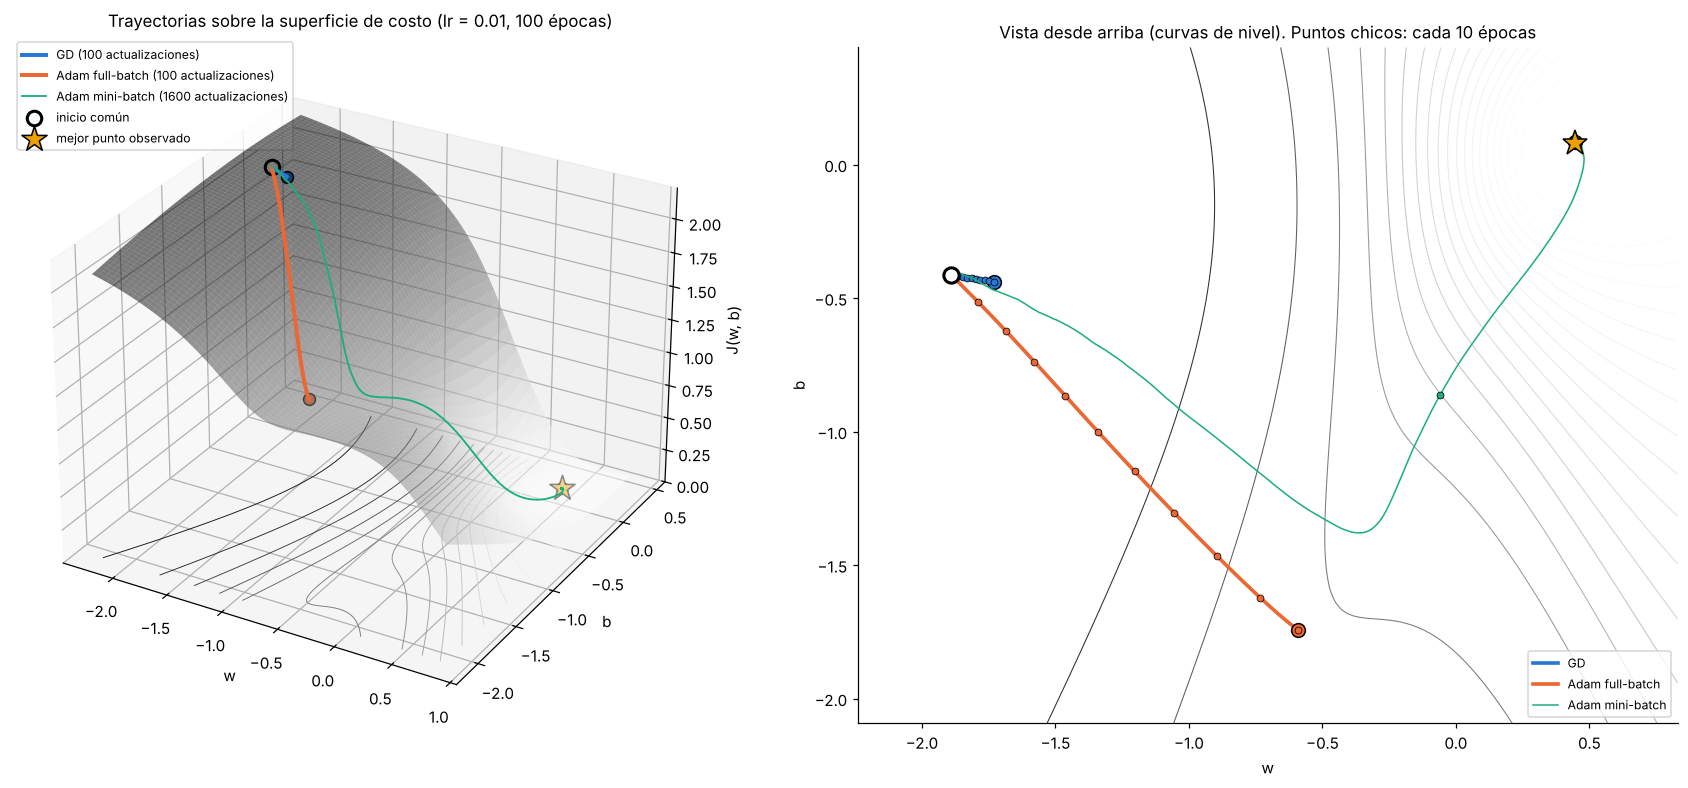

In [19]:
# --- Trayectorias de los 3 optimizadores sobre la superficie 3D de J(w, b) (mismo punto de partida) ---
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registra la proyección 3D)

paths = {lr: {opt: update_path(models[opt][lr], optimizers[opt][lr]) for opt in OPTS} for lr in LRS}
w_lo, w_hi, b_lo, b_hi = window(paths[LR_3D], extra_points=[(W_REF, B_REF)])
W3, B3 = np.meshgrid(np.linspace(w_lo, w_hi, 140), np.linspace(b_lo, b_hi, 140))
J3 = cost_surface(start_model, W3, B3)

fig = plt.figure(figsize=(16, 7))
ax = fig.add_subplot(1, 2, 1, projection="3d")
plot_trajectories_3d(paths[LR_3D], W3, B3, J3, start_model, ax, start=(W0, B0), target=(W_REF, B_REF),
                     labels={opt: f"{opt} ({optimizers[opt][LR_3D].step_count} actualizaciones)" for opt in OPTS})
ax.view_init(elev=28, azim=-60)
ax.set_title(f"Trayectorias sobre la superficie de costo (lr = {LR_3D}, 100 épocas)")
ax.legend(loc="upper left", fontsize=8)

ax2 = fig.add_subplot(1, 2, 2)
marks = {opt: tuple(p[::10] for p in epoch_params(models[opt][LR_3D])) for opt in OPTS}   # cada 10 épocas
plot_trajectories(paths[LR_3D], W3, B3, J3, ax=ax2, start=(W0, B0), target=(W_REF, B_REF), marks=marks,
                  title="Vista desde arriba (curvas de nivel). Puntos chicos: cada 10 épocas")
ax2.set_aspect("equal", adjustable="box")
ax2.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

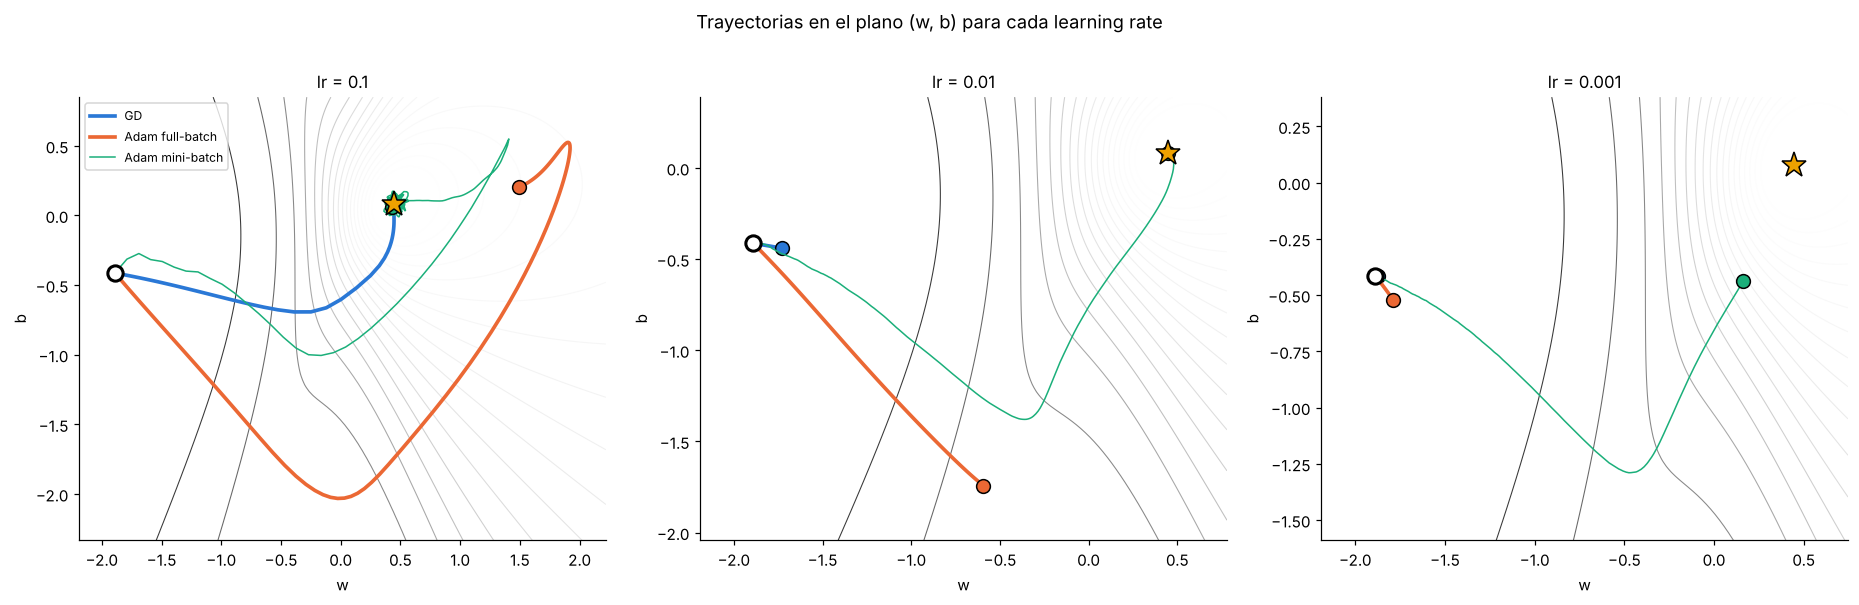

In [20]:
# --- Complemento: vista desde arriba para LOS TRES learning rates (mismo inicio) ---
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, lr in zip(axes, LRS):
    w_lo, w_hi, b_lo, b_hi = window(paths[lr], extra_points=[(W_REF, B_REF)], pad=0.3)
    Wm, Bm = np.meshgrid(np.linspace(w_lo, w_hi, 120), np.linspace(b_lo, b_hi, 120))
    plot_trajectories(paths[lr], Wm, Bm, cost_surface(start_model, Wm, Bm), ax=ax, n_levels=22,
                      start=(W0, B0), target=(W_REF, B_REF), title=f"lr = {lr}")
axes[0].legend(loc="best", fontsize=8)
fig.suptitle("Trayectorias en el plano (w, b) para cada learning rate", y=1.01)
plt.tight_layout(); plt.show()

Para entender por qué se mueven así, usamos lo que guarda cada optimizador en `history`: el tamaño del gradiente y el tamaño del paso en cada actualización. La línea punteada es el paso "nominal" de Adam al comienzo (lr en cada parámetro, lr·√2 en el plano).

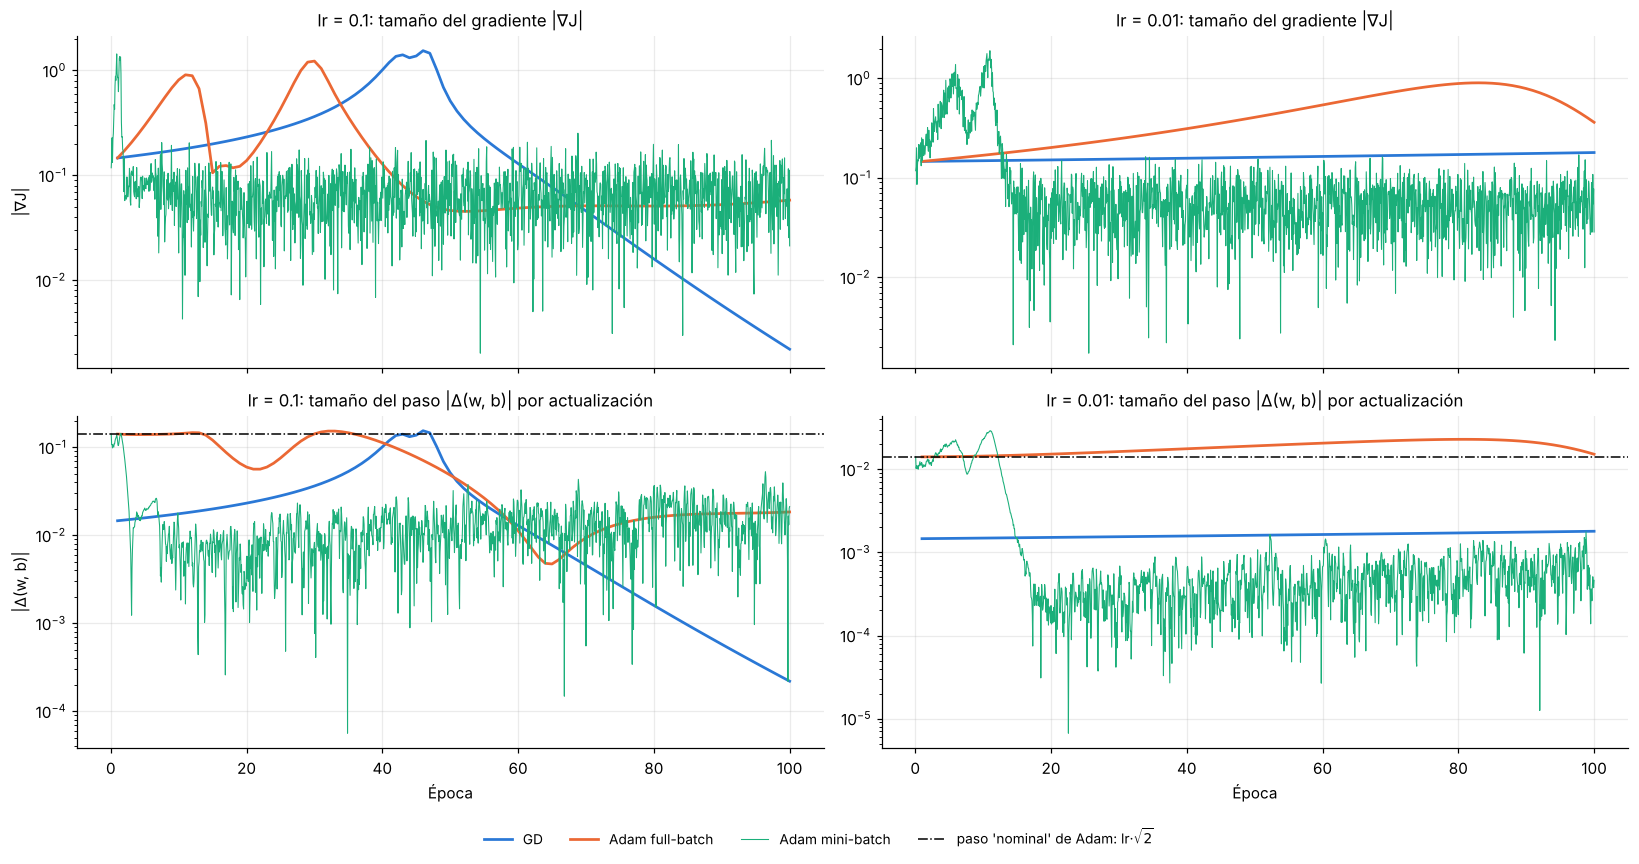

Adam full-batch, lr = 0.1
 época |   w     |  |∇J|   | sqrt(v_hat_w) | |paso|
    1  | -1.790  | 0.1464  |    0.1447     | 0.1414
   10  | -0.882  | 0.8131  |    0.4236     | 0.1430
   20  | -0.026  | 0.1381  |    0.4357     | 0.0597
   30  | +0.675  | 1.2284  |    0.5066     | 0.1422
   40  | +1.537  | 0.1282  |    0.4746     | 0.1130
   50  | +1.865  | 0.0463  |    0.4239     | 0.0483
   60  | +1.919  | 0.0487  |    0.3863     | 0.0113
   80  | +1.779  | 0.0510  |    0.3335     | 0.0160
  100  | +1.496  | 0.0580  |    0.2977     | 0.0184


In [21]:
# --- Diagnóstico: ¿por qué se mueven así? Tamaño del gradiente vs tamaño del paso que da cada optimizador ---
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True)
for col, lr in enumerate([0.1, 0.01]):
    for opt in OPTS:
        history = optimizers[opt][lr].history
        updates_per_epoch = len(history) / EPOCHS
        ep_k = np.arange(1, len(history) + 1) / updates_per_epoch        # actualización -> época equivalente
        lw = 0.7 if opt == "Adam mini-batch" else 1.8
        axes[0, col].plot(ep_k, [h["grad_norm"] for h in history], color=COLOR_OPT[opt], lw=lw, label=opt)
        axes[1, col].plot(ep_k, [h["step_norm"] for h in history], color=COLOR_OPT[opt], lw=lw, label=opt)
    axes[1, col].axhline(lr * np.sqrt(2), color="k", ls="-.", lw=1, label=r"paso 'nominal' de Adam: lr·$\sqrt{2}$")
    axes[0, col].set_title(f"lr = {lr}: tamaño del gradiente |∇J|")
    axes[1, col].set_title(f"lr = {lr}: tamaño del paso |Δ(w, b)| por actualización")
    for a in axes[:, col]: a.set_yscale("log")
    axes[1, col].set_xlabel("Época")
axes[0, 0].set_ylabel("|∇J|"); axes[1, 0].set_ylabel("|Δ(w, b)|")
plt.tight_layout()
fig.legend(*axes[1, 0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.05), frameon=False)
plt.show()

# Evidencia numérica del "frenado" de Adam full-batch con lr = 0.1 (memoria larga de v con beta2 = 0.999)
history = optimizers["Adam full-batch"][0.1].history
w_ep, _ = epoch_params(models["Adam full-batch"][0.1])
print("Adam full-batch, lr = 0.1")
print(" época |   w     |  |∇J|   | sqrt(v_hat_w) | |paso|")
for e in [1, 10, 20, 30, 40, 50, 60, 80, 100]:
    h = history[e - 1]
    print(f"  {e:3d}  | {w_ep[e]:+.3f}  | {h['grad_norm']:.4f}  |    {h['sqrt_v_hat']['W'][0, 0]:.4f}     | {h['step_norm']:.4f}")

Teníamos una hipótesis sobre por qué full-batch con lr 0.1 se pasa y después vuelve lento (inercia por un lado, memoria larga de v por el otro). Para comprobarla, repetimos esa corrida cambiando una pieza por vez. Con la clase `Adam` esto es solo cambiar un argumento.

In [22]:
# --- Ablación: ¿qué pieza de Adam causa el sobrepaso y el frenado de Adam full-batch con lr = 0.1? ---
# Misma corrida (mismo inicio, lr = 0.1, full-batch) apagando o acortando una pieza por vez.
variants = [
    ("Adam original (β1=0.9, β2=0.999)",            dict(),            EPOCHS),
    ("sin momento (β1=0)",                          dict(beta1=0.0),   EPOCHS),
    ("memoria de escala más corta (β2=0.99)",       dict(beta2=0.99),  EPOCHS),
    ("memoria de escala mucho más corta (β2=0.9)",  dict(beta2=0.9),   EPOCHS),
    ("Adam original con 300 épocas",                dict(),            300),
]
rows = []
for name, kwargs, n_epochs in variants:
    model_v, _ = train_model(Adam(learning_rate=0.1, **kwargs), epochs=n_epochs)
    J = np.array(model_v.loss_history)
    w_ep, _ = epoch_params(model_v)
    rows.append({"variante": name, "J final": J[-1], "brecha vs J_ref (%)": 100 * (J[-1] / J_REF - 1),
                 "w máximo alcanzado": w_ep.max(), "época estable": stable_epoch(J), "épocas": n_epochs})
display(pd.DataFrame(rows).set_index("variante").style.format(
    {"J final": "{:.5f}", "brecha vs J_ref (%)": lambda v: f"{round(v, 1) + 0.0:.1f}", "w máximo alcanzado": "{:+.2f}",
     "época estable": lambda v: "no alcanza" if np.isnan(v) else f"{int(v)}"}))

,J final,brecha vs J_ref (%),w máximo alcanzado,época estable,épocas
variante,,,,,
"Adam original (β1=0.9, β2=0.999)",0.11280,228.7,+1.92,no alcanza,100
sin momento (β1=0),0.03431,0.0,+0.45,25,100
memoria de escala más corta (β2=0.99),0.11081,222.9,+1.93,no alcanza,100
memoria de escala mucho más corta (β2=0.9),0.03966,15.6,+2.25,no alcanza,100
Adam original con 300 épocas,0.03431,0.0,+1.92,149,300


Animación de lo mismo con lr = 0.01, época por época. Se puede pausar y avanzar cuadro a cuadro; sirve para ver la velocidad de cada uno, que en el gráfico estático no se nota.

In [23]:
# --- Animación (opcional en la consigna): la "carrera" de los 3 optimizadores, época a época ---
plt.rcParams["animation.embed_limit"] = 40   # MB
w_lo, w_hi, b_lo, b_hi = window(paths[LR_3D], extra_points=[(W_REF, B_REF)])
fig, ax = plt.subplots(figsize=(7.2, 5.8))
ax.contour(W3, B3, J3, levels=np.geomspace(J3.min() * 1.01, J3.max(), 25), cmap="Greys", linewidths=0.7)
ax.plot(W_REF, B_REF, "*", ms=18, color="#eda100", mec="k", zorder=5)
ax.plot(W0, B0, "o", ms=9, mfc="white", mec="k", mew=2, zorder=5)
lines, points = {}, {}
for opt in OPTS:
    lines[opt], = ax.plot([], [], color=COLOR_OPT[opt], lw=LW_OPT[opt], label=opt)
    points[opt], = ax.plot([], [], "o", color=COLOR_OPT[opt], ms=10, mec="k", zorder=6)
ax.set_xlim(w_lo, w_hi); ax.set_ylim(b_lo, b_hi); ax.set_xlabel("w"); ax.set_ylabel("b"); ax.grid(False)
ax.legend(loc="lower right", fontsize=8)
title = ax.set_title("")
SHORT = {"GD": "GD", "Adam full-batch": "Adam FB", "Adam mini-batch": "Adam MB"}
updates_per_epoch = {opt: optimizers[opt][LR_3D].step_count // EPOCHS for opt in OPTS}
epoch_positions = {opt: epoch_params(models[opt][LR_3D]) for opt in OPTS}

def update_frame(e):
    for opt in OPTS:
        w_path, b_path = paths[LR_3D][opt]
        k = e * updates_per_epoch[opt]
        lines[opt].set_data(w_path[:k + 1], b_path[:k + 1])
        w_ep, b_ep = epoch_positions[opt]
        points[opt].set_data([w_ep[e]], [b_ep[e]])
    title.set_text(f"lr = {LR_3D}  |  época {e:3d}\n" +
                   "   ".join(f"{SHORT[o]}: J = {models[o][LR_3D].loss_history[e]:.3f}" for o in OPTS))
    return list(lines.values()) + list(points.values()) + [title]

anim = animation.FuncAnimation(fig, update_frame, frames=range(0, EPOCHS + 1, 2), interval=120, blit=False)
plt.close(fig)
with plt.rc_context({"savefig.dpi": 72}):     # resolución moderada para que el notebook no pese demasiado
    display(HTML(anim.to_jshtml()))

### Análisis 1d

El lr con mayor separación fue 0.01 (1.65, contra 1.36 con 0.1 y 0.75 con 0.001), así que el 3D es con ese. Agregamos igual la vista desde arriba para los tres lr, porque con 0.1 aparece algo que con 0.01 no se ve: el sobrepaso.

**GD (lr 0.01).** Se mueve en la dirección de máxima bajada, perpendicular a las curvas de nivel. Al inicio la derivada en w es 6.5 veces la de b, así que se mueve casi solo en w (el primer paso apunta unos 9° hacia abajo). Pero cada paso es 0.01 x 0.146, unos 0.0015. En 100 épocas recorre 0.16 y en el 3D casi ni se ve. No está atrapado en un mínimo, está en la meseta.

**Adam full-batch (lr 0.01).** El primer paso es exactamente (+0.01, -0.01): en la primera actualización m/√v vale el signo del gradiente, así que mueve los dos parámetros lo mismo, sin importar que la pendiente en b sea 6.5 veces menor. Por eso la trayectoria es una recta a 45° que lleva b hacia -1.74, cuando el óptimo está en +0.08. Sale de la meseta, que GD no puede, pero no va en la dirección de máximo descenso. Avanza entre 0.014 y 0.022 por época (un poco más que el lr cuando el gradiente crece, porque √v tiene memoria larga y va atrasado) y termina a mitad de la ladera (J = 1.36).

**Adam mini-batch (lr 0.01).** Empieza con la misma diagonal, pero da 16 pasos por época. Hacia la época 10 entra al canal, baja b hasta -1.38, gira (cruza w = 0 en la época 11) y desde la 14 queda en el pozo. Lo que nos llamó la atención: una vez ahí, el gradiente de cada lote sigue siendo de 0.05 por el ruido, pero los signos se alternan, entonces m se promedia a casi cero mientras v mantiene la magnitud. El paso cae a 0.0005. Adam termina filtrando solo el ruido del mini-batch.

**Con lr 0.1.** GD hace una curva suave y entra al mínimo sin pasarse; como dijimos en 1c, para oscilar necesitaría un lr mucho mayor (ver addendum). Full-batch hace un rodeo enorme: baja b hasta -2.0, cruza el canal con la inercia acumulada (w = 0 en la época 21) y se pasa hasta w = 1.92 (época 59), ya en la meseta derecha. De ahí vuelve muy despacio. La tabla del diagnóstico muestra por qué: al cruzar el canal vio gradientes de 1.2 y √v quedó en 0.5. En la meseta el gradiente es 0.05, pero √v sigue en 0.3-0.4 porque se "acuerda" del canal, y el paso queda en 0.011-0.018, unas diez veces menos de lo normal. Mini-batch también se pasa (hasta w = 1.41), pero vuelve enseguida porque tiene 16 veces más pasos, y después orbita el mínimo con pasos de 0.015. Ese es el ruido que se ve en su curva de costo.

**Ablación.** Confirmó la hipótesis. Sin momento (β1 = 0) no se pasa (w máximo 0.45) y llega a $J_{ref}$ en la época 25, antes que GD. Con β2 = 0.9 (memoria de unos 10 pasos) se pasa todavía más, pero vuelve rápido y termina en 0.040. Con β2 = 0.99 casi no cambia, porque una memoria de 100 pasos sigue cubriendo toda la corrida. Con 300 épocas, el Adam original también converge (estable desde la 149). O sea: el momento produce el sobrepaso y la memoria larga de v hace lenta la vuelta. No es que Adam no funcione: en 100 pasos no le alcanza para corregirse.

En resumen: GD es preciso pero depende del terreno, y en las mesetas que genera la tanh saturada se queda. Adam no depende de la escala del gradiente y por eso escapa, pero deforma la dirección (las diagonales) y carga inercia y memoria que lo pueden hacer pasarse. Mini-batch le da muchas más oportunidades de corregir, y por eso con lr 0.01 es el único que, desde este arranque difícil, llega al mínimo y se queda.

---
## Addendum - Pregunta 1: mínimo global, curvatura y no convexidad

Esto no forma parte de la red ni de los optimizadores: ninguno de los dos usa segundas derivadas. Lo hicimos para validar la referencia empírica $J_{ref}$ que usamos en 1c y 1d, y para explicar con la curvatura algunas cosas que se vieron en las trayectorias.

Como el modelo tiene solo 2 parámetros, podemos darnos el lujo de encontrar el mínimo global a fuerza bruta y refinarlo con Newton. En una red real no se podría hacer.

### Hessiano

Derivando otra vez el gradiente, con $t_i = \hat y_i$ y $s_i = 1 - t_i^2$:

$$
\frac{\partial^2 J}{\partial z_i^2} = \frac{2}{m}\, s_i \left(s_i - 2\,t_i\,(t_i - y_i)\right), \qquad
H = \begin{pmatrix} \sum h_i x_i^2 & \sum h_i x_i \\ \sum h_i x_i & \sum h_i \end{pmatrix}
$$

donde $h_i = \partial^2 J/\partial z_i^2$. El segundo término dentro del paréntesis puede ser negativo cuando el modelo se equivoca y está saturado; de ahí sale la no convexidad. Igual que con el gradiente, lo verificamos contra la derivada numérica, en este caso de `NeuralNetwork.gradients`.

In [24]:
# Addendum) Hessiano analítico de J(w, b). Solo se usa para ANALIZAR la superficie, nunca para entrenar.
def hessian(model, W, b):
    """Hessiano 2x2 de J respecto de (w, b) para los datos de `model`, evaluado en (W, b)."""
    probe = NeuralNetwork(model.X, model.y, W, b)
    x_, y_ = probe.X[:, 0], probe.y[:, 0]
    t = probe.predict()[:, 0]
    s = 1.0 - t ** 2
    h = (2.0 / x_.size) * s * (s - 2.0 * t * (t - y_))      # d2J/dz_i^2
    return np.array([[np.sum(h * x_ * x_), np.sum(h * x_)],
                     [np.sum(h * x_),      np.sum(h)]])

def gradient_vector(model, W, b):
    """Gradiente de J como vector (dJ/dw, dJ/db), a partir de NeuralNetwork.gradients."""
    probe = NeuralNetwork(model.X, model.y, W, b)
    g = probe.gradients(probe.X, probe.y)
    return np.array([g["W"][0, 0], g["b"][0]])

# Verificación: Hessiano analítico vs derivada numérica (centrada) del gradiente analítico
w_c, b_c, h = 0.7, -0.4, 1e-6
H_num = np.column_stack([
    (gradient_vector(start_model, [[w_c + h]], [b_c]) - gradient_vector(start_model, [[w_c - h]], [b_c])) / (2 * h),
    (gradient_vector(start_model, [[w_c]], [b_c + h]) - gradient_vector(start_model, [[w_c]], [b_c - h])) / (2 * h),
])
H_an = hessian(start_model, [[w_c]], [b_c])
print(f"Hessiano verificado: error relativo = {np.linalg.norm(H_num - H_an) / np.linalg.norm(H_num):.1e}")

Hessiano verificado: error relativo = 4.1e-11


### El mejor costo posible (J*) y validación de $J_{ref}$

Evaluamos J en una grilla de 481 x 321 puntos y refinamos el mejor con Newton. Esto no es un cuarto optimizador para comparar, es una regla para medir a los otros tres.

In [25]:
# J*: búsqueda exhaustiva en grilla + refinamiento con Newton (2do orden)
Wg, Bg = np.meshgrid(np.linspace(-6, 6, 481), np.linspace(-4, 4, 321))
Jg = cost_surface(start_model, Wg, Bg)
i_min = np.unravel_index(np.argmin(Jg), Jg.shape)
theta = np.array([Wg[i_min], Bg[i_min]])
for _ in range(20):                                   # Newton: converge cuadráticamente cerca del mínimo
    W_t, b_t = [[theta[0]]], [theta[1]]
    theta = theta - np.linalg.solve(hessian(start_model, W_t, b_t), gradient_vector(start_model, W_t, b_t))
W_STAR, B_STAR = theta
star_model = NeuralNetwork(X, Y, [[W_STAR]], [B_STAR])
J_STAR = star_model.loss()
eig = np.linalg.eigvalsh(hessian(start_model, [[W_STAR]], [B_STAR]))

y_star = star_model.predict()[:, 0]
model_bias = np.mean((y_star - f_true(x)) ** 2)      # lo que el modelo NO puede representar de f(x)
noise_mse  = np.mean((y - f_true(x)) ** 2)           # lo que nadie puede predecir (ruido)
R2_STAR = 1 - J_STAR / y.var()

print(f"Mínimo global:  w* = {W_STAR:.4f},  b* = {B_STAR:.4f}")
print(f"J* = {J_STAR:.5f}   |grad J(w*,b*)| = {np.linalg.norm(gradient_vector(start_model, [[W_STAR]], [B_STAR])):.1e}   R²* = {R2_STAR:.4f}")
print(f"Autovalores del Hessiano en el mínimo: {eig[0]:.4f}, {eig[1]:.4f}  -> ambos > 0 (mínimo genuino)")
print(f"Número de condición kappa = {eig[1] / eig[0]:.2f}  -> cerca del mínimo el 'cuenco' es casi redondo")
print(f"Descomposición aproximada de J*: error de modelo (sesgo) = {model_bias:.4f} + ruido = {noise_mse:.4f}"
      f"  (suma = {model_bias + noise_mse:.4f})")

from numpy.lib.stride_tricks import sliding_window_view
neighbours = sliding_window_view(Jg, (3, 3))
mask = np.ones((3, 3), bool); mask[1, 1] = False
min_neighbours = np.where(mask, neighbours, np.inf).min(axis=(2, 3))
n_local_minima = int(np.sum(Jg[1:-1, 1:-1] < min_neighbours))
print(f"Mínimos locales interiores encontrados en la grilla (w en [-6,6], b en [-4,4]): {n_local_minima}")

# Validación de la referencia empírica usada en 1c y 1d
print(f"\nValidación: J_ref = {J_REF:.5f} vs J* = {J_STAR:.5f}  -> J_ref queda {100 * (J_REF / J_STAR - 1):.3f}% arriba;"
      f" (w_ref, b_ref) está a {np.hypot(W_REF - W_STAR, B_REF - B_STAR):.4f} de (w*, b*)")
print(f"Estabilidad de GD cerca del mínimo: oscilaría recién con lr > 2/λmax = {2 / eig[1]:.2f}")

Mínimo global:  w* = 0.4466,  b* = 0.0801
J* = 0.03431   |grad J(w*,b*)| = 4.4e-18   R²* = 0.8972
Autovalores del Hessiano en el mínimo: 0.8284, 1.1379  -> ambos > 0 (mínimo genuino)
Número de condición kappa = 1.37  -> cerca del mínimo el 'cuenco' es casi redondo
Descomposición aproximada de J*: error de modelo (sesgo) = 0.0238 + ruido = 0.0089  (suma = 0.0327)
Mínimos locales interiores encontrados en la grilla (w en [-6,6], b en [-4,4]): 1

Validación: J_ref = 0.03431 vs J* = 0.03431  -> J_ref queda 0.000% arriba; (w_ref, b_ref) está a 0.0001 de (w*, b*)
Estabilidad de GD cerca del mínimo: oscilaría recién con lr > 2/λmax = 1.76


El mejor ajuste posible es $\tanh(0.447x + 0.080)$, con J* = 0.0343 y R² = 0.897. La referencia empírica $J_{ref}$ que usamos en el cuerpo queda prácticamente encima, así que llamar "converger" a llegar a $J_{ref}$ era correcto: ningún optimizador podía bajar de ahí.

De ese error, aproximadamente 0.024 viene de que una neurona no puede dibujar los tramos que suben y bajan, y 0.009 es el ruido. O sea que cerca del 70% del error final es limitación del modelo, que es lo que se veía en los 9 subplots de 1c.

Dos cosas más. En la grilla hay un único mínimo, así que si un optimizador no llega no es porque cayó en un mínimo local. Y alrededor del mínimo el "pozo" es casi redondo (autovalores 0.83 y 1.14). La dificultad, entonces, no está cerca del mínimo sino lejos, como se vio en 1d. El autovalor mayor también explica por qué GD fue monótono en todos los casos: cerca del mínimo solo oscilaría con un lr mayor a 2/λmax = 1.76, y 0.1 está muy lejos.

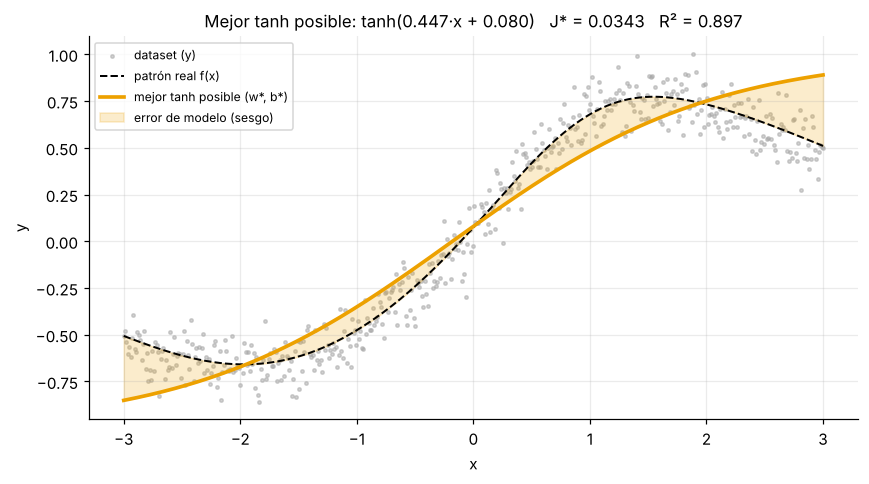

In [26]:
# --- La mejor tanh posible vs el patrón real: qué parte del error es del modelo y cuál es ruido ---
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_fit(star_model, ax=ax, color="#eda100", true_fn=f_true, label="mejor tanh posible (w*, b*)",
         title=f"Mejor tanh posible: tanh({W_STAR:.3f}·x + {B_STAR:.3f})   J* = {J_STAR:.4f}   R² = {R2_STAR:.3f}")
ax.fill_between(np.sort(x), f_true(np.sort(x)), y_star[np.argsort(x)], color="#eda100", alpha=0.2,
                label="error de modelo (sesgo)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### No convexidad

Con el Hessiano calculamos en cada punto de la grilla de 1d el autovalor mínimo: si es negativo, la superficie se curva hacia abajo en alguna dirección y ahí no es convexa.

En la ventana w∈[-3,3], b∈[-2.5,2.5]: 97% del área es NO convexa (Hessiano con un autovalor < 0)


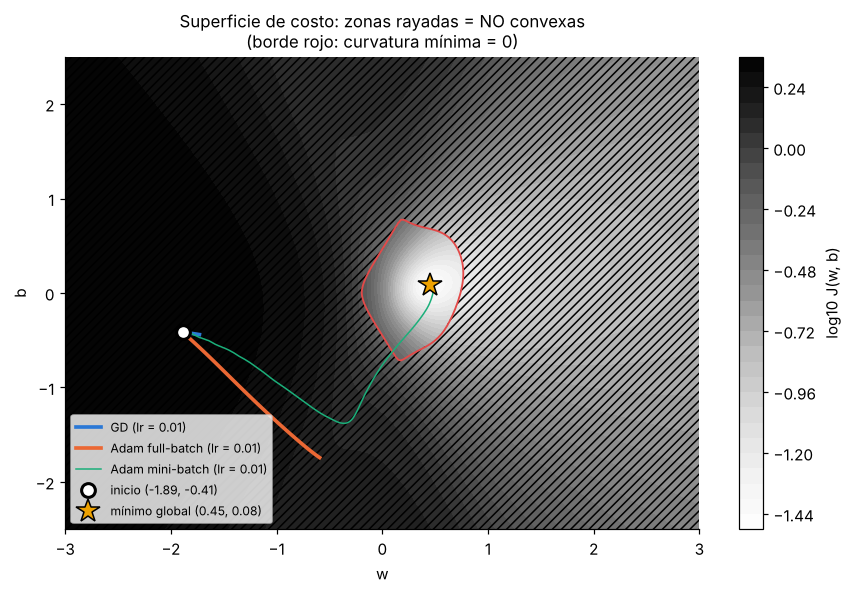

In [27]:
# --- ¿Dónde es convexa J(w, b)? Autovalor mínimo del Hessiano en la ventana de 1d ---
lam_min = np.empty(W_land.shape)
for idx in np.ndindex(W_land.shape):
    lam_min[idx] = np.linalg.eigvalsh(hessian(start_model, [[W_land[idx]]], [B_land[idx]]))[0]
print(f"En la ventana w∈[-3,3], b∈[-2.5,2.5]: {np.mean(lam_min < 0):.0%} del área es NO convexa (Hessiano con un autovalor < 0)")

fig, ax = plt.subplots(figsize=(8, 5.5))
cf = ax.contourf(W_land, B_land, np.log10(J_land), levels=30, cmap="Greys")
ax.contourf(W_land, B_land, (lam_min < 0).astype(float), levels=[0.5, 1.5], colors="none", hatches=["////"])
ax.contour(W_land, B_land, lam_min, levels=[0], colors="#e34948", linewidths=1.2)
plt.colorbar(cf, ax=ax, label="log10 J(w, b)")
for opt in OPTS:
    ax.plot(*paths[LR_3D][opt], color=COLOR_OPT[opt], lw=LW_OPT[opt], label=f"{opt} (lr = {LR_3D})")
ax.plot(W0, B0, "o", ms=9, mfc="white", mec="k", mew=2, label=f"inicio ({W0:.2f}, {B0:.2f})")
ax.plot(W_STAR, B_STAR, "*", ms=16, color="#eda100", mec="k", label=f"mínimo global ({W_STAR:.2f}, {B_STAR:.2f})")
ax.set_xlim(w_lin[0], w_lin[-1]); ax.set_ylim(b_lin[0], b_lin[-1])
ax.set_xlabel("w"); ax.set_ylabel("b"); ax.grid(False)
ax.set_title("Superficie de costo: zonas rayadas = NO convexas\n(borde rojo: curvatura mínima = 0)")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

Nos sorprendió lo poco convexa que es: el 97% de la ventana tiene curvatura negativa en alguna dirección. Lo único con forma de pozo es una isla alrededor del mínimo (borde rojo). Las mesetas de 1d caen todas en la zona rayada, y las tres trayectorias pasan casi todo el tiempo ahí: solo mini-batch entra a la isla convexa dentro de las 100 épocas. Esto explica por qué la comparación entre optimizadores depende tanto del punto inicial, y por qué las garantías de convergencia de GD para funciones convexas no sirven de mucho acá: valen recién cuando el optimizador ya llegó al pozo.

# **PREGUNTA 2** (Temas de la clase 3)

# Caso: Predicción del gasto promedio de los usuarios usando redes neuronales

**Descarga del dataset:**  
El conjunto de datos puede descargarse en el siguiente [enlace](https://drive.google.com/file/d/1e_FRepCpHBWWGj3TYG4HY7WHALCyR4wQ/view?usp=sharing)

---

## Descripción general:

El dataset recopila información sobre las compras realizadas por distintos clientes en una tienda durante el último año.  
Cada registro representa una transacción e incluye datos tanto del cliente como del producto adquirido.

---

## El dataset contiene la siguiente información:

- **User_ID:** Código identificador único del cliente que efectuó la compra.  
- **Product_ID:** Código identificador único del producto adquirido.  
- **Age:** Rango de edad del cliente.  
- **Gender:** Género del cliente (F: Femenino, M: Masculino).  
- **Marital_Status:** Estado civil del cliente (0: Soltero, 1: Casado).  
- **City_Category:** Tipo de zona donde se encuentra la sucursal donde se realizó la compra.  
  - A: Barrio de clase alta  
  - B: Barrio de clase media  
  - C: Barrio de clase media-baja  
- **Stay_In_Current_City_Years:** Número de años que el cliente ha venido comprando en la tienda desde su primera visita.  
- **Product_Category:** Categoría del producto comprado.  
- **Product_Subcategory_1:** Subcategoría principal del producto.  
- **Product_Subcategory_2:** Subcategoría secundaria del producto.  
- **Purchase:** Monto pagado por el producto en esa transacción.

---

## Objetivo del caso de estudio:

Desarrollar un **modelo predictivo** capaz de estimar el **gasto promedio** que realizará un cliente, a partir de su información demográfica, sus patrones de compra, gustos y comportamiento. Tener en cuenta que se busca que el modelo prediga el gasto promedio por cliente, no el gasto en cada nueva transacción individual. Y la idea sería que una vez que el modelo ya esté listo y entrenado, se use para estimar apartir de datos de clientes relativamente nuevos, que solo llevan unas pocas visitas y compras en la tienda. Por ende, el modelo debería poder hacer una inferencia de los datos sin depender de la cantidad de compras de cada cliente.


---
## Resolución - Pregunta 2

Seguimos la misma lógica que en la Pregunta 1: primero entender bien los datos y después modelar. La resolución avanza en orden:

1. **2a)** Exploramos el dataset, decidimos qué columnas sirven, cómo tratar los nulos y cómo codificar cada variable. Después pasamos de una fila por transacción a una fila por cliente, armamos las features y revisamos con experimentos concretos dónde está el riesgo de data leakage.
2. **2b)** Definimos la MLP en PyTorch y elegimos activación, función de costo, optimizador, learning rate, dropout y cantidad de épocas con experimentos, no a ojo. Cada experimento se repite con 3 semillas para distinguir una mejora real de una casualidad.
3. **2c)** Evaluamos el modelo final: curvas por época, real vs predicho, el camino de iteración que nos llevó hasta ahí y una prueba del caso de uso que plantea el enunciado (clientes nuevos con pocas compras).
4. **2d)** Medimos una sola vez sobre un conjunto de test que no usamos para ninguna decisión y cerramos con las conclusiones.

El dataset se descarga solo en Colab con `gdown` desde el link del enunciado. Si se corre en local, alcanza con dejar `dataset_compras.csv` al lado del notebook.

In [28]:
# PREGUNTA 2 - Configuración (librerías, semillas, carga del dataset)
import os
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

SEED_P2 = 42
DEVICE = "cpu"   # la red es chica: en CPU entrena en segundos y los resultados son reproducibles

# Colores de la Pregunta 2 (misma paleta que la Pregunta 1)
C_TRAIN, C_VAL, C_TEST = "#2a78d6", "#eb6834", "#1baf7a"
C_ACCENT = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948", "#eda100"]

# Dataset del enunciado (Google Drive). En Colab se descarga solo; localmente basta con tener el archivo al lado del notebook.
DATA_ID = "1e_FRepCpHBWWGj3TYG4HY7WHALCyR4wQ"
DATA_PATH = "dataset_compras.csv"
if not os.path.exists(DATA_PATH):
    import gdown
    gdown.download(id=DATA_ID, output=DATA_PATH, quiet=True)

raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} transacciones x {raw.shape[1]} columnas")


182,721 transacciones x 11 columnas


### 2a) EDA y preparación del dataset (2 puntos)
Realizar el análisis exploratorio del dataset (EDA) con las herramientas vistas en materias anteriores.
- Analizar qué columnas sirven para lograr el objetivo y cuáles no (drop) en base al contexto del negocio y a lo entendido del caso de estudio (feature engineering).
- Analizar con qué columnas vale la pena hacer un tratamiento de valores nulos o si simplemente se debe dropear toda la columna porque ya no tiene salvación.
- Analizar a qué variables se les debe hacer label encoding, a cuáles one-hot encoding, ordinal encoding o mapping encoding. Explicar detalladamente los criterios utilizados para tomar esas decisiones.
- Transformar, agrupar, combinar y operar la data de tal manera que sea útil para extraer patrones de gastos y tendencias de gustos de cada cliente. **Tener mucho cuidado con el data leakage, ocurre mucho cuando se usan proporciones como nuevas columnas**.



Redactar las conclusiones preliminares que puedan notar de cada feature y justificar el porqué de cada encoding, limpieza o transformación aplicada. Cada justificación se debe redactar a detalle y sustentar con gráficas y/o tablas.


#### Resolución 2a)

**Primera mirada.** Antes de decidir nada, revisamos qué tipo tiene cada columna, cuántos valores distintos toma, cuántos nulos tiene y si hay filas repetidas.

In [29]:
# 2a) Primera mirada: tipos, valores distintos, nulos y duplicados
resumen = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "valores distintos": raw.nunique(),
    "nulos": raw.isna().sum(),
    "% nulos": 100 * raw.isna().mean(),
    "ejemplo": raw.iloc[0],
})
display(resumen.style.format({"% nulos": "{:.1f}"}))
display(raw.head())
print(f"Filas idénticas repetidas: {raw.duplicated().sum():,} ({100 * raw.duplicated().mean():.1f}% del total)")


,tipo,valores distintos,nulos,% nulos,ejemplo
User_ID,int64,7432,0,0.0,1044096
Product_ID,str,2455,0,0.0,P00017122
Age,str,7,0,0.0,46-50
Gender,str,2,0,0.0,F
Marital_Status,int64,2,0,0.0,1
City_Category,str,3,0,0.0,B
Stay_In_Current_City_Years,str,5,0,0.0,1
Product_Category,int64,20,0,0.0,10
Product_Subcategory_1,float64,33,41818,22.9,45.000000
Product_Subcategory_2,float64,16,105260,57.6,nan


,User_ID,Product_ID,Age,Gender,Marital_Status,City_Category,Stay_In_Current_City_Years,Product_Category,Product_Subcategory_1,Product_Subcategory_2,Purchase
0,1044096,P00017122,46-50,F,1,B,1,10,45.0,NaN,1810
1,1071818,P00074517,36-45,M,0,A,3,11,27.0,NaN,12351
2,1022986,P00013694,36-45,M,1,A,5+,4,28.0,NaN,127
3,1094684,P00049122,36-45,M,1,A,1,16,9.0,8.0,2214
4,1004157,P00006469,46-50,M,1,A,5+,3,NaN,NaN,7142


Filas idénticas repetidas: 2,249 (1.2% del total)


Lo que sale de esta tabla:

- Son 182.721 transacciones de 7.432 clientes y 2.455 productos.
- Solo dos columnas tienen nulos: `Product_Subcategory_1` (22,9%) y `Product_Subcategory_2` (57,6%). Las analizamos más abajo.
- `Product_Category` y las subcategorías vienen como números, pero son **códigos**: la categoría 10 no es "el doble" que la 5. Eso define cómo las vamos a codificar.
- `Stay_In_Current_City_Years` y `Age` vienen como texto con rangos ("5+", "26-35"), así que hay que mapearlas a números.
- `Purchase` toma solo 1.833 valores distintos en 182 mil filas. Es una pista que confirmamos después: cada producto tiene un precio fijo.
- Hay 2.249 filas idénticas (1,2%). Antes de borrarlas conviene entender de dónde salen.

**¿Qué es una fila y qué hay que predecir?** El dataset tiene una fila por transacción, pero el objetivo es el **gasto promedio por cliente**. Así que la unidad de análisis es el cliente, y la variable objetivo es el promedio de `Purchase` de cada uno. Lo primero es verificar si los datos demográficos de un cliente son los mismos en todas sus transacciones. Si es así, se pueden tomar como un atributo del cliente.

Clientes cuyos datos demográficos cambian entre transacciones: {'Age': 0, 'Gender': 0, 'Marital_Status': 0, 'City_Category': 0, 'Stay_In_Current_City_Years': 0}

7,432 clientes. Compras por cliente: mínimo 10, mediana 18, máximo 50
Gasto promedio por cliente: media 6,750, desvío 3,298, rango [275, 17,231]


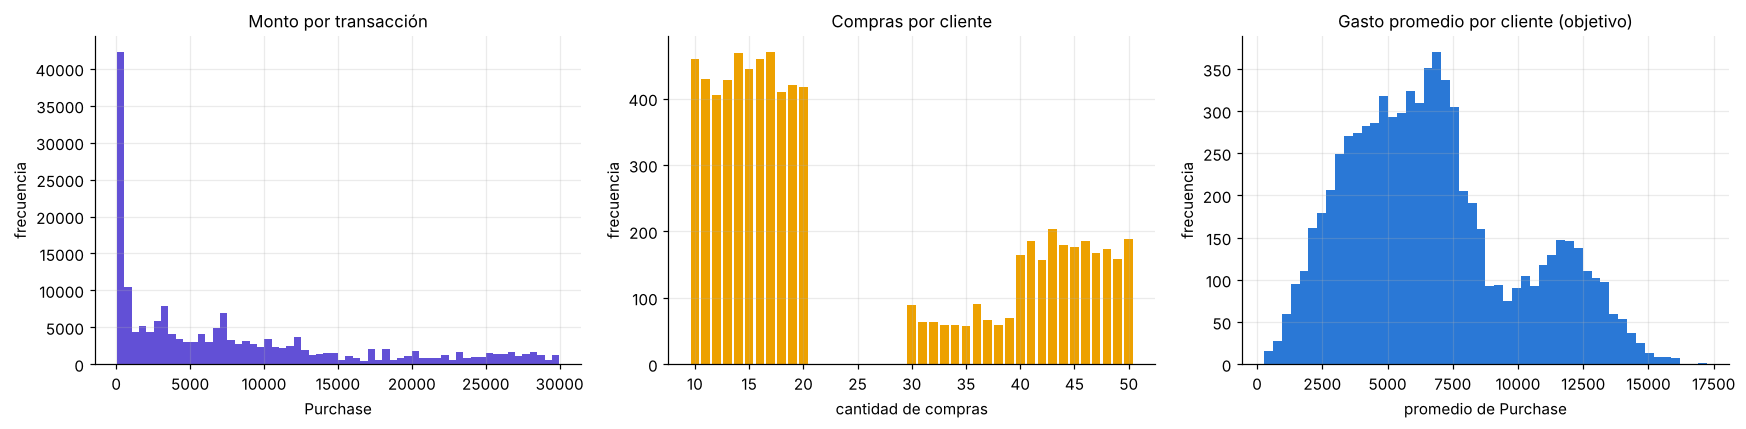

Ningún cliente tiene entre 21 y 29 compras: True
Correlación entre cantidad de compras y gasto promedio: +0.60


,clientes,gasto promedio
10 a 20 compras,"4,813","5,108"
30 a 50 compras,"2,619","9,767"


In [30]:
# 2a) Unidad de análisis: el objetivo es por CLIENTE, no por transacción
compras_por_cliente = raw.groupby("User_ID").size()
DEMO_COLS = ["Age", "Gender", "Marital_Status", "City_Category", "Stay_In_Current_City_Years"]
varia_dentro = (raw.groupby("User_ID")[DEMO_COLS].nunique() > 1).sum()
print("Clientes cuyos datos demográficos cambian entre transacciones:", varia_dentro.to_dict())

target = raw.groupby("User_ID")["Purchase"].mean().rename("gasto_promedio")   # variable objetivo
print(f"\n{target.size:,} clientes. Compras por cliente: mínimo {compras_por_cliente.min()}, "
      f"mediana {compras_por_cliente.median():.0f}, máximo {compras_por_cliente.max()}")
print(f"Gasto promedio por cliente: media {target.mean():,.0f}, desvío {target.std():,.0f}, "
      f"rango [{target.min():,.0f}, {target.max():,.0f}]")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(raw["Purchase"], bins=60, color=C_ACCENT[3])
axes[0].set_title("Monto por transacción"); axes[0].set_xlabel("Purchase")
conteo = compras_por_cliente.value_counts().sort_index()
axes[1].bar(conteo.index, conteo.values, width=0.8, color=C_ACCENT[5])
axes[1].set_title("Compras por cliente"); axes[1].set_xlabel("cantidad de compras")
axes[2].hist(target, bins=50, color=C_TRAIN)
axes[2].set_title("Gasto promedio por cliente (objetivo)"); axes[2].set_xlabel("promedio de Purchase")
for ax in axes: ax.set_ylabel("frecuencia")
plt.tight_layout(); plt.show()

r_n = np.corrcoef(compras_por_cliente.loc[target.index], target)[0, 1]
print(f"Ningún cliente tiene entre 21 y 29 compras: {not compras_por_cliente.between(21, 29).any()}")
print(f"Correlación entre cantidad de compras y gasto promedio: {r_n:+.2f}")
display(target.groupby(np.where(compras_por_cliente.loc[target.index] <= 20, "10 a 20 compras", "30 a 50 compras"))
        .agg(["count", "mean"]).rename(columns={"count": "clientes", "mean": "gasto promedio"}).style.format("{:,.0f}"))


- Los datos demográficos no cambian nunca dentro de un mismo cliente. Son atributos fijos y alcanza con tomar el primero.
- El objetivo va de 275 a 17.231, con media 6.750 y una forma bimodal: hay un grupo grande alrededor de 5.000-7.000 y otro más chico cerca de 12.000.
- La cantidad de compras por cliente tiene una forma artificial: **ningún cliente tiene entre 21 y 29 compras**. Hay un grupo de 10 a 20 compras (4.813 clientes) y otro de 30 a 50 (2.619).
- La cantidad de compras está bastante correlacionada con el gasto promedio (+0,60): el grupo de 30 a 50 compras gasta en promedio casi el doble. Es tentador usarla como feature, pero el enunciado pide lo contrario: el modelo tiene que servir para **clientes nuevos con pocas compras** y "no depender de la cantidad de compras". En la sección de leakage mostramos que, además, no aporta nada una vez que se conocen los gustos del cliente.

In [31]:
# 2a) Duplicados: ¿errores de carga o el mismo producto comprado más de una vez?
dup = raw.duplicated()
con_dup = raw.loc[dup, "User_ID"].unique()
grupo_n = np.where(compras_por_cliente <= 20, "10 a 20 compras", "30 a 50 compras")
print(f"{len(con_dup):,} clientes tienen al menos una fila repetida.")
display(pd.Series(compras_por_cliente.index.isin(con_dup), index=compras_por_cliente.index)
        .groupby(grupo_n).mean().mul(100).rename("% de clientes con alguna fila repetida").to_frame().style.format("{:.1f}"))

n_sin_dup = raw.drop_duplicates().groupby("User_ID").size()
fuera = (n_sin_dup.between(21, 29) | (n_sin_dup < 10)).sum()
print(f"Si borráramos las repetidas, {fuera} clientes quedarían con una cantidad de compras que el dataset original "
      f"nunca tiene (menos de 10, o entre 21 y 29).")


1,657 clientes tienen al menos una fila repetida.


,% de clientes con alguna fila repetida
10 a 20 compras,5.7
30 a 50 compras,52.8


Si borráramos las repetidas, 40 clientes quedarían con una cantidad de compras que el dataset original nunca tiene (menos de 10, o entre 21 y 29).


**Decidimos no borrar las filas repetidas.** Hay dos indicios de que son compras reales del mismo producto (la misma persona comprando dos veces lo mismo) y no errores de carga:

1. Aparecen mucho más en los clientes que compran más (52,8% de los clientes con 30-50 compras tiene alguna, contra 5,7% de los de 10-20). Es lo esperable si cada compra es una elección: cuantas más compras, más probable repetir un producto.
2. Si las borráramos, 40 clientes quedarían con una cantidad de compras que el dataset nunca tiene (menos de 10, o entre 21 y 29). Es decir, las repetidas forman parte de cómo se generaron las compras de cada cliente.

Como el objetivo es un promedio por cliente, una compra repetida tiene que pesar dos veces en ese promedio.

**¿Qué columnas sirven?** Miramos dos niveles. Las variables demográficas son del cliente, así que las comparamos contra su gasto promedio. Las del producto son de cada transacción, así que las comparamos contra el monto de cada compra. Para tener una medida común, calculamos qué parte de la varianza explica cada columna sola (el R² que se obtiene prediciendo con la media de cada grupo).

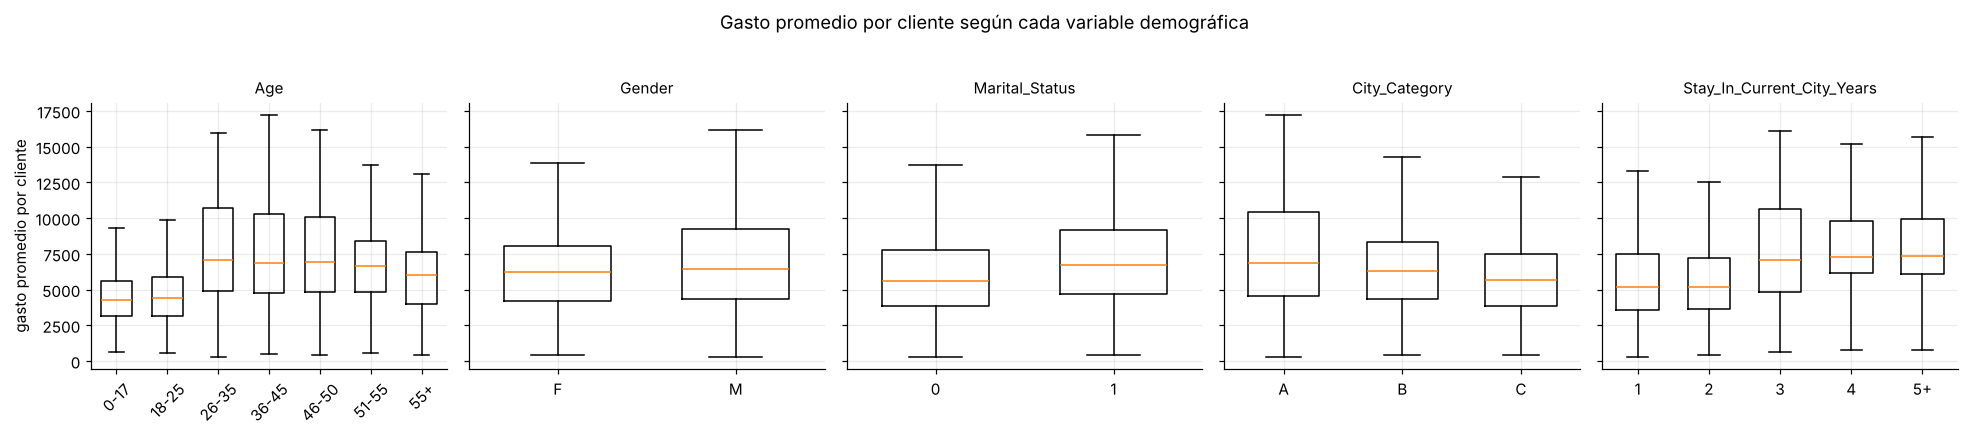

,nivel,valores,R² que explica sola
columna,,,
Age,cliente,7,0.097
Gender,cliente,2,0.005
Marital_Status,cliente,2,0.018
City_Category,cliente,3,0.030
Stay_In_Current_City_Years,cliente,5,0.085
Product_Category,transacción,20,0.764
Product_Subcategory_1,transacción,34,0.232
Product_Subcategory_2,transacción,17,0.011
Product_Category + Product_Subcategory_1,transacción,374,0.850


Product_ID: 2,455 productos. Desvío máximo del monto dentro de un mismo producto: 0.0  -> cada producto tiene UN precio fijo.


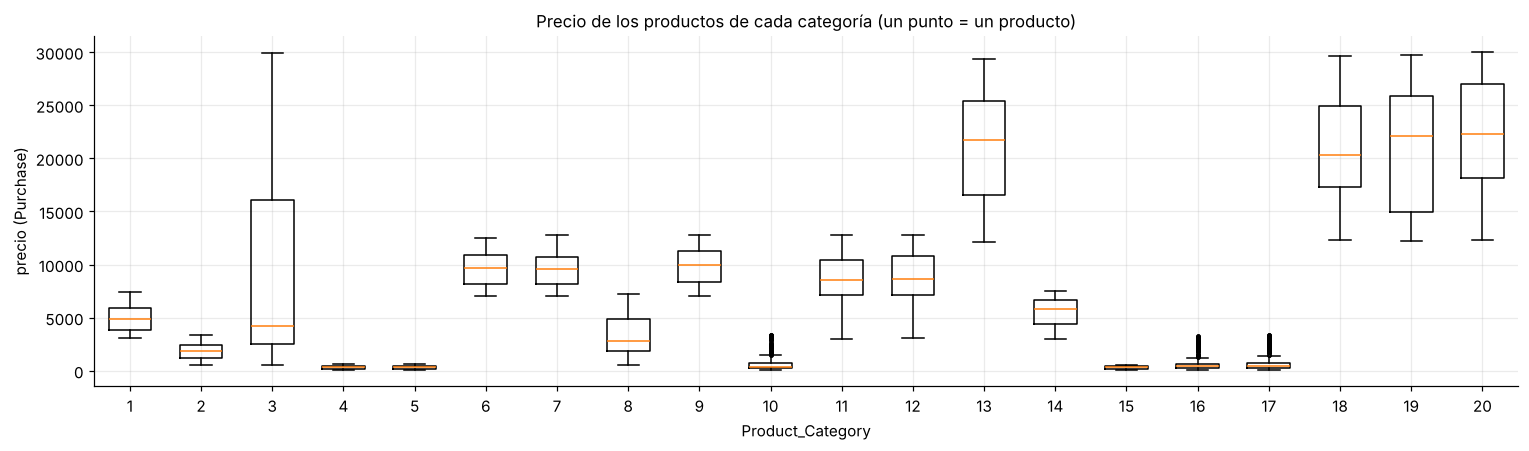

In [32]:
# 2a) ¿Qué columnas explican el gasto promedio? Demografía (a nivel cliente) vs producto (a nivel transacción)
clientes = raw.groupby("User_ID")[DEMO_COLS].first().join(target)

def r2_grupo(claves, y):
    """R² que se obtiene prediciendo y con la media de su grupo (cuánto de la varianza explica la columna sola)."""
    medias = y.groupby(claves).transform("mean")
    return 1 - np.sum((y - medias) ** 2) / np.sum((y - y.mean()) ** 2)

ORDEN = {"Age": ["0-17", "18-25", "26-35", "36-45", "46-50", "51-55", "55+"],
         "Gender": ["F", "M"], "Marital_Status": [0, 1], "City_Category": ["A", "B", "C"],
         "Stay_In_Current_City_Years": ["1", "2", "3", "4", "5+"]}
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
filas = []
for ax, col in zip(axes, DEMO_COLS):
    valores = clientes[col].astype(type(ORDEN[col][0]))
    ax.boxplot([clientes.loc[valores == v, "gasto_promedio"] for v in ORDEN[col]], showfliers=False, widths=0.6)
    ax.set_xticks(range(1, len(ORDEN[col]) + 1), ORDEN[col], rotation=45 if col == "Age" else 0)
    ax.set_title(col, fontsize=10)
    filas.append({"columna": col, "nivel": "cliente", "valores": len(ORDEN[col]),
                  "R² que explica sola": r2_grupo(valores, clientes["gasto_promedio"])})
axes[0].set_ylabel("gasto promedio por cliente")
fig.suptitle("Gasto promedio por cliente según cada variable demográfica", y=1.03)
plt.tight_layout(); plt.show()

sub = raw.assign(**{c: raw[c].fillna(0) for c in ["Product_Subcategory_1", "Product_Subcategory_2"]})
for claves in [["Product_Category"], ["Product_Subcategory_1"], ["Product_Subcategory_2"],
               ["Product_Category", "Product_Subcategory_1"],
               ["Product_Category", "Product_Subcategory_1", "Product_Subcategory_2"], ["Product_ID"]]:
    filas.append({"columna": " + ".join(claves), "nivel": "transacción", "valores": sub.groupby(claves).ngroups,
                  "R² que explica sola": r2_grupo([sub[c] for c in claves], sub["Purchase"])})
display(pd.DataFrame(filas).set_index("columna").style.format({"R² que explica sola": "{:.3f}"}))

precio_producto = raw.groupby("Product_ID").agg(precio=("Purchase", "mean"), desvio=("Purchase", "std"),
                                                cat=("Product_Category", "first"))
print(f"Product_ID: {len(precio_producto):,} productos. Desvío máximo del monto dentro de un mismo producto: "
      f"{precio_producto['desvio'].max():.1f}  -> cada producto tiene UN precio fijo.")

fig, ax = plt.subplots(figsize=(14, 4.2))
cats = sorted(precio_producto["cat"].unique())
ax.boxplot([precio_producto.loc[precio_producto["cat"] == c, "precio"] for c in cats], widths=0.6, showfliers=True,
           flierprops={"markersize": 2})
ax.set_xticks(range(1, len(cats) + 1), cats)
ax.set_title("Precio de los productos de cada categoría (un punto = un producto)")
ax.set_xlabel("Product_Category"); ax.set_ylabel("precio (Purchase)")
plt.tight_layout(); plt.show()


- **La demografía explica poco por separado.** La edad es la que más pesa (R² 0,097): los menores de 26 gastan bastante menos. Le siguen la antigüedad (0,085, con un salto entre 2 y 3 años), la ciudad (0,030, con A > B > C, en el mismo orden que el nivel socioeconómico que describe el enunciado), el estado civil (0,018) y el género (0,005).
- **El producto lo explica casi todo.** La categoría sola explica el 76% de la variación del monto. Combinada con la subcategoría 1 sube al 85% y con las tres juntas al 92%. Los precios están muy agrupados por categoría (gráfico de cajas): hay categorías baratas (4, 5, 15, por debajo de 600), intermedias y caras (13, 18, 19, 20, entre 12.000 y 30.000). La 3 es la única con un rango enorme.
- **`Product_ID` explica el 100%**, porque cada producto tiene un único precio: el desvío del monto dentro de un mismo producto es exactamente 0. Esto es clave para el leakage. Si a cada cliente le asignamos "el precio de lo que compró", reconstruimos su gasto promedio de forma exacta y no estaríamos prediciendo nada.

Decisiones:

- `User_ID` no entra como feature. Es un identificador sin significado y lo usamos solo para agrupar.
- `Product_ID` tampoco entra: con 2.455 valores tiene alta cardinalidad, su información de "tipo de producto" ya está en la categoría y las subcategorías, y usarlo a través de su precio es leakage.
- Todo lo demás se queda. La demografía aporta poco por separado, pero es barata y la red puede combinarla con lo demás. En 2c medimos cuánto aporta realmente.

**Nulos.** Antes de imputar o borrar hay que entender por qué faltan. Revisamos tres cosas: si un mismo producto aparece a veces con subcategoría y a veces sin ella, si los nulos se concentran en alguna categoría y si los productos con nulo tienen precios distintos.

,% nulos,productos con nulos y no nulos mezclados,monto medio si es nulo,monto medio si no es nulo
columna,,,,
Product_Subcategory_1,22.9,0,"8,073","7,786"
Product_Subcategory_2,57.6,0,"8,127","7,477"


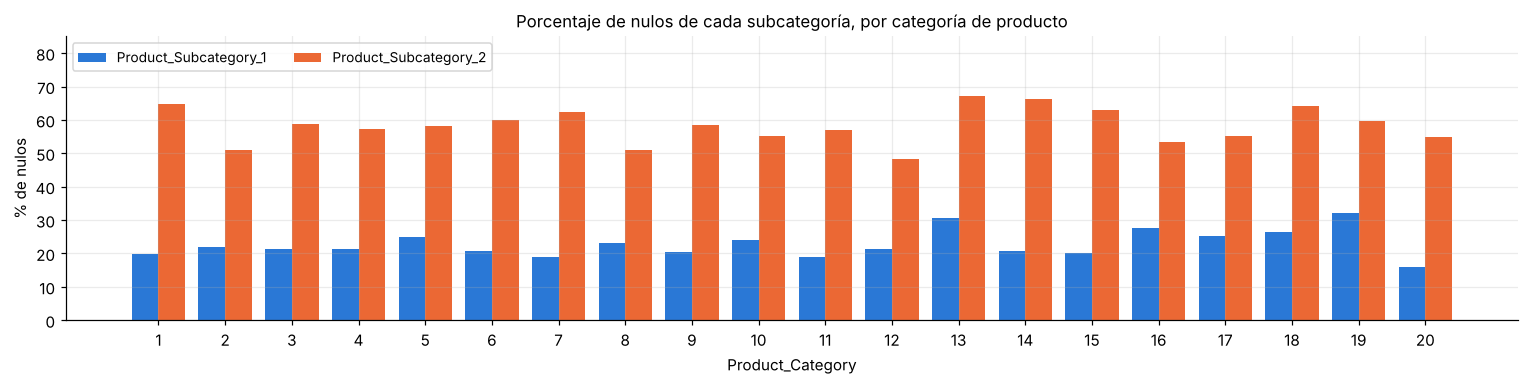

In [33]:
# 2a) Nulos: ¿faltan datos o son productos que no tienen subcategoría?
SUB_COLS = ["Product_Subcategory_1", "Product_Subcategory_2"]
filas = []
for col in SUB_COLS:
    nulo = raw[col].isna()
    mezcla = (raw.assign(nulo=nulo).groupby("Product_ID")["nulo"].nunique() > 1).sum()
    filas.append({"columna": col, "% nulos": 100 * nulo.mean(),
                  "productos con nulos y no nulos mezclados": mezcla,
                  "monto medio si es nulo": raw.loc[nulo, "Purchase"].mean(),
                  "monto medio si no es nulo": raw.loc[~nulo, "Purchase"].mean()})
display(pd.DataFrame(filas).set_index("columna").style.format(
    {"% nulos": "{:.1f}", "monto medio si es nulo": "{:,.0f}", "monto medio si no es nulo": "{:,.0f}"}))

nulos_por_cat = raw.groupby("Product_Category")[SUB_COLS].apply(lambda d: 100 * d.isna().mean())
fig, ax = plt.subplots(figsize=(14, 3.6))
ancho = 0.4; pos = np.arange(len(nulos_por_cat))
ax.bar(pos - ancho / 2, nulos_por_cat[SUB_COLS[0]], ancho, color=C_ACCENT[0], label=SUB_COLS[0])
ax.bar(pos + ancho / 2, nulos_por_cat[SUB_COLS[1]], ancho, color=C_ACCENT[1], label=SUB_COLS[1])
ax.set_xticks(pos, nulos_por_cat.index.astype(str)); ax.set_xlabel("Product_Category"); ax.set_ylabel("% de nulos")
ax.set_ylim(0, 85); ax.set_title("Porcentaje de nulos de cada subcategoría, por categoría de producto")
ax.legend(ncol=2, loc="upper left")
plt.tight_layout(); plt.show()


- **Los nulos son estructurales, no datos perdidos.** Ningún producto mezcla filas con y sin subcategoría: si un producto no tiene subcategoría, no la tiene en ninguna venta. Y los nulos se reparten parejo entre todas las categorías (alrededor de 20% en la subcategoría 1 y de 50-65% en la 2).
- El monto medio con y sin nulo es parecido (8.073 vs 7.786 en la subcategoría 1), así que el nulo no anticipa un precio raro.

Por eso **no imputamos** con la moda ni con la media: inventaríamos una subcategoría que el producto no tiene. Tampoco borramos las filas, porque perderíamos el 58% de las transacciones, ni la columna `Product_Subcategory_2`, aunque tenga 57,6% de nulos, porque el 42% restante sí trae información. Tratamos el nulo como un valor más: **0 = "sin subcategoría"**. Como después estas columnas se convierten en proporciones por cliente, "sin subcategoría" pasa a ser una columna más del perfil de compra.

**Encoding.** El criterio fue el siguiente: si la variable tiene un orden real, se mantiene ese orden en un solo número (ordinal o mapping). Si no lo tiene, nunca la tratamos como número, porque una red interpreta "10 > 5" como algo con significado.

| Variable | Tipo | Encoding | Por qué |
|---|---|---|---|
| `Gender` | binaria | mapping (M = 1, F = 0) | dos valores, una columna alcanza |
| `Marital_Status` | binaria | ya viene 0/1 | nada que hacer |
| `Age` | rangos ordenados | ordinal (0-17 → 0, …, 55+ → 6) | los rangos tienen orden; la relación con el gasto no es lineal (sube y después baja), pero las capas ocultas pueden curvarla, y así ahorramos 6 columnas |
| `City_Category` | categórica con orden | ordinal (C → 0, B → 1, A → 2) | el enunciado define un orden (media-baja, media, alta) y los datos lo confirman: el gasto medio es A > B > C |
| `Stay_In_Current_City_Years` | numérica en texto | mapping ("5+" → 5) | es una cantidad de años; "5+" se toma como 5 |
| `Product_Category`, subcategorías | nominales (códigos) | one-hot, agregado por cliente como proporción | no tienen orden; ver feature engineering |
| `User_ID`, `Product_ID` | identificadores | se descartan | label encoding solo los convertiría en números sin significado |

Label encoding no lo usamos para ninguna variable que entre a la red. Asignarle un entero arbitrario a una categoría nominal le inventa un orden que no existe.

In [34]:
# 2a) Encoding de las variables demográficas (una fila por cliente)
EDAD_ORD = {"0-17": 0, "18-25": 1, "26-35": 2, "36-45": 3, "46-50": 4, "51-55": 5, "55+": 6}
CIUDAD_ORD = {"C": 0, "B": 1, "A": 2}      # media-baja < media < alta

def codificar_demografia(clientes):
    """Devuelve las columnas demográficas ya numéricas, una fila por cliente."""
    out = pd.DataFrame(index=clientes.index)
    out["genero_M"] = (clientes["Gender"] == "M").astype(int)                    # mapping binario
    out["casado"] = clientes["Marital_Status"].astype(int)                        # ya es 0/1
    out["edad"] = clientes["Age"].map(EDAD_ORD)                                   # ordinal (rangos ordenados)
    out["nivel_ciudad"] = clientes["City_Category"].map(CIUDAD_ORD)               # ordinal (nivel socioeconómico)
    out["antiguedad"] = (clientes["Stay_In_Current_City_Years"].astype(str)
                         .str.replace("+", "", regex=False).astype(int))           # mapping: "5+" -> 5
    return out

demo = codificar_demografia(clientes)
display(demo.head())
print("Valores sin mapear:", int(demo.isna().sum().sum()))


,genero_M,casado,edad,nivel_ciudad,antiguedad
User_ID,,,,,
1000035,1,0,1,2,1
1000044,1,1,3,2,4
1000070,1,1,4,1,4
1000087,0,1,6,0,4
1000115,0,1,4,0,2


Valores sin mapear: 0


**Separación train / validation / test.** La hacemos **por cliente** y **antes** de armar las features. Así, todo lo que se calcula con los datos (el vocabulario de categorías, el escalado, cualquier estadística) sale solo de train. Usamos 70/15/15, estratificado por deciles del gasto promedio, para que los tres conjuntos tengan la misma distribución del objetivo. Validation se usa para todas las decisiones de 2b y 2c. Test queda guardado hasta 2d.

In [35]:
# 2a) Separación por CLIENTE en train / validation / test (70 / 15 / 15), antes de armar cualquier feature
usuarios = target.index.to_numpy()
deciles = pd.qcut(target, 10, labels=False)          # estratificamos por deciles del objetivo
u_train, u_resto = train_test_split(usuarios, test_size=0.30, random_state=SEED_P2, stratify=deciles)
u_val, u_test = train_test_split(u_resto, test_size=0.50, random_state=SEED_P2, stratify=deciles.loc[u_resto])
SPLITS = {"train": u_train, "validation": u_val, "test": u_test}

tx = raw.copy()
for col in SUB_COLS:                                  # nulo = "el producto no tiene esa subcategoría" -> categoría 0
    tx[col] = tx[col].fillna(0).astype(int)
tx["Cat_Sub1"] = tx["Product_Category"].astype(str) + "-" + tx["Product_Subcategory_1"].astype(str)   # combinación (ver features)
tx_split = {nombre: tx[tx["User_ID"].isin(u)] for nombre, u in SPLITS.items()}

display(pd.DataFrame({nombre: {"clientes": len(u), "transacciones": len(tx_split[nombre]),
                               "gasto promedio (media)": target.loc[u].mean(),
                               "gasto promedio (desvío)": target.loc[u].std()}
                      for nombre, u in SPLITS.items()}).T.style.format("{:,.0f}"))


,clientes,transacciones,gasto promedio (media),gasto promedio (desvío)
train,"5,202","127,868","6,752","3,306"
validation,"1,115","27,305","6,745","3,300"
test,"1,115","27,548","6,742","3,260"


**Feature engineering: los "gustos" del cliente.** El gasto promedio de un cliente depende sobre todo de **qué tipo de productos compra**. Si la mitad de sus compras son de la categoría 13 (precios de 12.000 a 30.000), su promedio va a ser alto, sin importar cuántas compras haga. Por eso describimos a cada cliente con la **proporción de sus compras** que cae en cada categoría, en cada subcategoría y en cada combinación de categoría y subcategoría 1. Esta última la agregamos porque, según el análisis de columnas, la combinación explica el 85% del precio, contra 76% de la categoría sola.

Tres detalles importantes:

- Son proporciones de **cantidad de compras**, no de dinero. No usan `Purchase` en ningún momento.
- Al ser proporciones, no dependen de cuántas compras hizo el cliente: un cliente con 10 compras y uno con 50 que compran lo mismo en la misma proporción tienen las mismas features. Es justo lo que pide el enunciado.
- El vocabulario de columnas sale de train. Una combinación que solo aparezca en validation o en test se ignora, como pasaría en producción con un producto nuevo.

In [36]:
# 2a) Feature engineering: los "gustos" del cliente como proporción de sus compras
COLS_GUSTO = ["Product_Category", "Product_Subcategory_1", "Product_Subcategory_2", "Cat_Sub1"]
VOCAB = {col: sorted(tx_split["train"][col].unique()) for col in COLS_GUSTO}
PREFIJO = {"Product_Category": "cat", "Product_Subcategory_1": "sub1", "Product_Subcategory_2": "sub2", "Cat_Sub1": "cs1"}

def proporciones(tx_clientes, col):
    """Proporción de las COMPRAS (no del gasto) de cada cliente que cae en cada valor de `col`.
    Las columnas salen del vocabulario de train; un valor que solo aparezca en otro split se ignora."""
    tabla = pd.crosstab(tx_clientes["User_ID"], tx_clientes[col], normalize="index")
    tabla = tabla.reindex(columns=VOCAB[col], fill_value=0.0)
    tabla.columns = [f"{PREFIJO[col]}_{v}" for v in tabla.columns]
    return tabla

def armar_features(tx_clientes):
    """Tabla final por cliente: demografía codificada + proporciones de compra por categoría, subcategorías
    y combinación categoría-subcategoría 1."""
    gustos = [proporciones(tx_clientes, col) for col in COLS_GUSTO]
    return demo.loc[tx_clientes["User_ID"].unique()].join(gustos).sort_index()

X_sets = {nombre: armar_features(t) for nombre, t in tx_split.items()}
y_sets = {nombre: target.loc[X.index] for nombre, X in X_sets.items()}
GRUPOS = {"demografía": list(demo.columns),
          "gustos por categoría": [c for c in X_sets["train"] if c.startswith("cat_")],
          "gustos por subcategoría 1": [c for c in X_sets["train"] if c.startswith("sub1_")],
          "gustos por subcategoría 2": [c for c in X_sets["train"] if c.startswith("sub2_")],
          "gustos por categoría-subcategoría 1": [c for c in X_sets["train"] if c.startswith("cs1_")]}
display(pd.DataFrame({"columnas": {g: len(c) for g, c in GRUPOS.items()}}).T)
print("Forma final:", {k: v.shape for k, v in X_sets.items()}, "| nulos:", int(sum(v.isna().sum().sum() for v in X_sets.values())))
display(X_sets["train"].iloc[:3, :12])


,demografía,gustos por categoría,gustos por subcategoría 1,gustos por subcategoría 2,gustos por categoría-subcategoría 1
columnas,5,20,34,17,374


Forma final: {'train': (5202, 450), 'validation': (1115, 450), 'test': (1115, 450)} | nulos: 0


,genero_M,casado,edad,nivel_ciudad,antiguedad,cat_1,cat_2,cat_3,cat_4,cat_5,cat_6,cat_7
User_ID,,,,,,,,,,,,
1000035,1,0,1,2,1,0.0000,0.0000,0.0000,0.0000,0.1538,0.0000,0.0769
1000044,1,1,3,2,4,0.0233,0.0000,0.1163,0.0233,0.0000,0.0000,0.1163
1000070,1,1,4,1,4,0.0476,0.0238,0.0238,0.0238,0.0238,0.0238,0.1190


**Data leakage.** Para que el riesgo no quede solo en palabras, armamos cuatro features "tentadoras" y medimos qué pasa con cada una usando una regresión lineal como termómetro rápido. Cada una tiene un problema distinto:

1. **Proporción del gasto por categoría** (en lugar de la proporción de compras): usa el `Purchase` del propio cliente, o sea, el mismo dato con el que se calcula el objetivo.
2. **Precio medio de los productos que compró**, tomando el precio de cada producto de las ventas de train: como cada producto tiene un precio fijo, esto **es** el objetivo.
3. **Cantidad total de compras**: no es leakage en sentido estricto, pero el enunciado pide no depender de ella.
4. **Conteos por categoría en lugar de proporciones**: esconden la cantidad de compras dentro de las features.

In [37]:
# 2a) Data leakage: features tentadoras y qué pasa con cada una
def r2_lineal(X_tr, y_tr, X_va, y_va):
    """R² de una regresión lineal (escalada con train) en train y en validation. Sirve de termómetro rápido."""
    esc = StandardScaler().fit(X_tr)
    reg = LinearRegression().fit(esc.transform(X_tr), y_tr)
    return r2_score(y_tr, reg.predict(esc.transform(X_tr))), r2_score(y_va, reg.predict(esc.transform(X_va)))

def proporcion_gasto(tx_clientes):
    """TRAMPA 1: proporción del GASTO del cliente en cada categoría (usa el Purchase del propio cliente)."""
    tabla = pd.crosstab(tx_clientes["User_ID"], tx_clientes["Product_Category"],
                        values=tx_clientes["Purchase"], aggfunc="sum", normalize="index")
    tabla = tabla.reindex(columns=VOCAB["Product_Category"], fill_value=0.0)
    tabla.columns = [f"gasto_cat_{c}" for c in tabla.columns]
    return tabla.fillna(0.0)

def precio_productos(tx_clientes, tx_ref=tx_split["train"]):
    """TRAMPA 2: precio medio (según train) de los productos que compró cada cliente."""
    precio = tx_ref.groupby("Product_ID")["Purchase"].mean()
    p = tx_clientes["Product_ID"].map(precio).fillna(tx_ref["Purchase"].mean())
    return tx_clientes.assign(p=p).groupby("User_ID")["p"].mean().rename("precio_productos")

def conteos(tx_clientes):
    """TRAMPA 3: cantidad (no proporción) de compras por categoría: lleva escondida la cantidad total de compras."""
    tabla = pd.crosstab(tx_clientes["User_ID"], tx_clientes["Product_Category"])
    tabla = tabla.reindex(columns=VOCAB["Product_Category"], fill_value=0)
    tabla.columns = [f"n_cat_{c}" for c in tabla.columns]
    return tabla

Xtr, Xva = X_sets["train"], X_sets["validation"]
ttr, tva = tx_split["train"], tx_split["validation"]
n_compras = compras_por_cliente.rename("n_compras")
casos = {
    "Features honestas (las que usamos)": (Xtr, Xva),
    "+ proporción del GASTO por categoría": (Xtr.join(proporcion_gasto(ttr)), Xva.join(proporcion_gasto(tva))),
    "+ precio medio de los productos comprados": (Xtr.join(precio_productos(ttr)), Xva.join(precio_productos(tva))),
    "+ cantidad total de compras": (Xtr.join(n_compras), Xva.join(n_compras)),
    "conteos por categoría en vez de proporciones": (Xtr.drop(columns=GRUPOS["gustos por categoría"]).join(conteos(ttr)),
                                                     Xva.drop(columns=GRUPOS["gustos por categoría"]).join(conteos(tva))),
}
filas = []
for nombre, (a, b) in casos.items():
    r_tr, r_va = r2_lineal(a, y_sets["train"].loc[a.index], b, y_sets["validation"].loc[b.index])
    filas.append({"variante": nombre, "R² train": r_tr, "R² validation": r_va})
display(pd.DataFrame(filas).set_index("variante").style.format("{:.4f}"))


,R² train,R² validation
variante,,
Features honestas (las que usamos),0.9667,0.9609
+ proporción del GASTO por categoría,0.9729,0.9690
+ precio medio de los productos comprados,1.0000,1.0000
+ cantidad total de compras,0.9668,0.9610
conteos por categoría en vez de proporciones,0.9673,0.9613


Lo que muestra la tabla:

- **Precio medio de los productos comprados: R² = 1,0000** en train y en validation. No es un modelo excelente, es la definición del objetivo. Como cada producto tiene un precio fijo, el promedio de los precios de lo que compró el cliente **es** su gasto promedio. Cualquier feature armada con `Purchase` a nivel producto (target encoding de `Product_ID`, precio medio por producto) cae en esto.
- **Proporción del gasto por categoría: sube de 0,961 a 0,969.** Es el caso más peligroso, porque parece una mejora razonable y no un resultado absurdo. Validation no lo detecta: la fuga no viaja de un split a otro, está dentro de cada cliente. Sus propias features se calculan con el mismo `Purchase` con el que se calcula su objetivo, en train y en validation por igual. Es la trampa de "proporciones como nuevas columnas" que menciona el enunciado.
- **Cantidad total de compras:** aunque está correlacionada +0,60 con el objetivo, no aporta nada (0,9608 → 0,9610). Toda esa correlación ya está explicada por los gustos: los que compran más, compran más productos caros. Como además el enunciado pide no depender de ella, la dejamos afuera.
- **Conteos en lugar de proporciones:** con el historial completo da lo mismo (0,961), pero esconde la cantidad de compras dentro de las features. El mismo perfil de gustos con 10 o con 50 compras daría features distintas. Como el enunciado pide que la predicción no dependa de la cantidad de compras, usamos proporciones.

Por eso las features finales son solo la demografía y las proporciones de **cantidad** de compras. Ninguna usa `Purchase`, ninguna depende de cuántas compras hizo el cliente y todas salen del vocabulario de train.

In [38]:
# 2a) Escalado (ajustado SOLO con train) y dataset final que consume la red
FEATURES = list(X_sets["train"].columns)
escalador = StandardScaler().fit(X_sets["train"][FEATURES])
Xs = {nombre: escalador.transform(X[FEATURES]).astype(np.float32) for nombre, X in X_sets.items()}

# El objetivo también se estandariza para entrenar (media y desvío de train); el R² se reporta en la escala original
Y_MEDIA, Y_DESVIO = y_sets["train"].mean(), y_sets["train"].std()
ys = {nombre: ((y - Y_MEDIA) / Y_DESVIO).to_numpy(np.float32) for nombre, y in y_sets.items()}

print(f"{len(FEATURES)} features por cliente. Media de train tras escalar ~ {Xs['train'].mean():.1e}, desvío ~ {Xs['train'].std():.2f}")
display(X_sets["train"].describe().T[["mean", "std", "min", "max"]].head(12))


450 features por cliente. Media de train tras escalar ~ 7.1e-10, desvío ~ 1.00


,mean,std,min,max
genero_M,0.5334,0.4989,0.0,1.0000
casado,0.5832,0.4931,0.0,1.0000
edad,3.3372,1.7556,0.0,6.0000
nivel_ciudad,1.1219,0.8027,0.0,2.0000
antiguedad,2.6188,1.4177,1.0,5.0000
cat_1,0.0322,0.0431,0.0,0.3333
cat_2,0.0190,0.0312,0.0,0.3000
cat_3,0.0933,0.0715,0.0,0.4000
cat_4,0.0569,0.0690,0.0,0.4545
cat_5,0.0644,0.0732,0.0,0.5000


**Conclusiones de 2a.**

- La unidad de análisis es el cliente: 7.432 clientes, con el gasto promedio como objetivo. Train, validation y test se separan por cliente antes de construir cualquier cosa.
- La demografía explica poco del gasto por sí sola (la edad es lo que más pesa, con R² 0,10). El tipo de producto lo explica casi todo: la categoría sola explica el 76% del precio de cada compra.
- Cada producto tiene un precio fijo. Por eso cualquier feature construida con el precio de lo que compró el cliente reconstruye el objetivo (R² = 1). Esta es la trampa de leakage principal del dataset.
- Los nulos de las subcategorías son estructurales (el producto no tiene subcategoría) y se codifican como un valor propio, 0. Las filas repetidas son recompras y se conservan.
- Codificamos con mapping o ordinal las variables con orden real (edad, nivel de ciudad, antigüedad), con mapping binario el género y con proporciones por cliente las categorías de producto. No usamos label encoding en nada que entre a la red.
- El dataset final tiene 450 columnas por cliente: 5 demográficas y 445 proporciones de compra, todas escaladas con media y desvío de train. Una regresión lineal con estas features ya llega a R² 0,961 en validation. Ese es el número que la red tiene que justificar superar.

### 2b) Modelo Multilayer Perceptron (MLP) (2.5 puntos)
Entrenar un modelo de deep learning usando PyTorch que consuma el dataframe ya pre-procesado en el paso anterior.

Características para el diseño de la red:
- El modelo debe tener un mínimo de 3 capas ocultas.
- El modelo debe tener un mínimo de 32 neuronas por cada capa oculta.
- Cada capa oculta debe tener su respectiva función de activación.
- La elección de la función de activación de las capas ocultas es libre, pero se debe justificar por qué se está eligiendo esa, ya sea mediante conceptos teóricos o con resultados de pruebas empíricas.
- Analizar y justificar cuál es la mejor función de costo, algoritmo de optimización y learning rate para este modelo.
- Analizar cuál sería el mejor número de épocas para entrenar el modelo.
- Opcional: Incluir técnicas de regularización como dropout en las capas ocultas.

#### Resolución 2b)

**La red.** `MLP` es un `nn.Module` que apila capas ocultas (lineal + activación, y opcionalmente dropout) y termina en una neurona lineal sin activación, porque predecimos un número sin límites (regresión). La configuración base tiene tres capas ocultas de 128, 64 y 32 neuronas: cumple el mínimo de 3 capas y 32 neuronas, y achica hacia la salida.

`entrenar` recibe una configuración y una semilla, y entrena con mini-batches mezclados en cada época, igual que el Adam mini-batch de la Pregunta 1. Al final de cada época mide el costo y el R² sobre todo train y todo validation, con la red en modo evaluación (sin dropout), para que las dos curvas sean comparables. También guarda la época con mejor R² de validation.

Entrenamos sobre el objetivo estandarizado (media 0, desvío 1 con los valores de train). Con valores del orden de 7.000, los gradientes del MSE serían enormes al principio y el learning rate perdería sentido. El R² es el mismo en las dos escalas.

In [39]:
# 2b) Red MLP en PyTorch y rutina de entrenamiento
T = {nombre: (torch.tensor(Xs[nombre]), torch.tensor(ys[nombre]).unsqueeze(1)) for nombre in Xs}

ACTIVACIONES = {"ReLU": nn.ReLU, "LeakyReLU": nn.LeakyReLU, "GELU": nn.GELU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
PERDIDAS = {"MSE": nn.MSELoss, "Huber": nn.HuberLoss, "MAE (L1)": nn.L1Loss}
OPTIMIZADORES = {
    "SGD + momentum": lambda p, lr, wd: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=wd),
    "Adam":           lambda p, lr, wd: torch.optim.Adam(p, lr=lr, weight_decay=wd),
    "AMSGrad":        lambda p, lr, wd: torch.optim.Adam(p, lr=lr, weight_decay=wd, amsgrad=True),
    "AdamW":          lambda p, lr, wd: torch.optim.AdamW(p, lr=lr, weight_decay=wd if wd else 1e-2),
}

class MLP(nn.Module):
    """Perceptrón multicapa: cada capa oculta es Linear + activación (+ Dropout opcional). Salida lineal (regresión)."""
    def __init__(self, n_entradas, ocultas=(128, 64, 32), activacion="ReLU", dropout=0.0):
        super().__init__()
        capas, ancho = [], n_entradas
        for n in ocultas:
            capas += [nn.Linear(ancho, n), ACTIVACIONES[activacion]()]
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            ancho = n
        capas.append(nn.Linear(ancho, 1))
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)

BASE = dict(ocultas=(128, 64, 32), activacion="ReLU", dropout=0.0, perdida="MSE",
            optimizador="Adam", lr=1e-3, weight_decay=0.0, batch_size=128, epocas=60)

def evaluar(modelo, nombre, perdida_fn, datos=None):
    """Costo y R² de `modelo` sobre un split completo, en modo evaluación (sin dropout)."""
    X, y = (datos or T)[nombre]
    modelo.eval()
    with torch.no_grad():
        pred = modelo(X)
    return perdida_fn(pred, y).item(), r2_score(y.numpy(), pred.numpy())

def entrenar(config=None, semilla=SEED_P2, splits=("train", "validation"), datos=None):
    """Entrena una MLP con `config` (cambios sobre BASE). Devuelve el modelo, la historia por época y la mejor época.
    Al final de cada época mide costo y R² sobre train y validation completos (sin dropout), así ambas curvas son comparables.
    El R² se calcula sobre el objetivo estandarizado, que es idéntico al R² en pesos (el R² no cambia con una escala lineal).
    `datos` permite entrenar con otro juego de tensores (por ejemplo, un subconjunto de columnas)."""
    cfg = {**BASE, **(config or {})}
    datos = datos or T
    torch.manual_seed(semilla)
    cargador = DataLoader(TensorDataset(*datos["train"]), batch_size=cfg["batch_size"], shuffle=True,
                          generator=torch.Generator().manual_seed(semilla))
    modelo = MLP(datos["train"][0].shape[1], cfg["ocultas"], cfg["activacion"], cfg["dropout"])
    perdida_fn = PERDIDAS[cfg["perdida"]]()
    opt = OPTIMIZADORES[cfg["optimizador"]](modelo.parameters(), cfg["lr"], cfg["weight_decay"])
    hist = {f"{m}_{s}": [] for m in ("loss", "r2") for s in splits}
    mejor = {"r2": -np.inf, "epoca": 0, "estado": None}
    for epoca in range(1, cfg["epocas"] + 1):
        modelo.train()
        for xb, yb in cargador:
            opt.zero_grad()
            perdida_fn(modelo(xb), yb).backward()
            opt.step()
        for s in splits:
            l, r2 = evaluar(modelo, s, perdida_fn, datos)
            hist[f"loss_{s}"].append(l); hist[f"r2_{s}"].append(r2)
        if hist["r2_validation"][-1] > mejor["r2"]:
            mejor = {"r2": hist["r2_validation"][-1], "epoca": epoca,
                     "estado": {k: v.clone() for k, v in modelo.state_dict().items()}}
    return modelo, {k: np.array(v) for k, v in hist.items()}, mejor

t0 = time.perf_counter()
modelo_base, hist_base, mejor_base = entrenar()
print(f"Configuración base: {BASE}")
print(f"{sum(p.numel() for p in modelo_base.parameters()):,} parámetros entrenables | {time.perf_counter() - t0:.1f} s")
print(f"R² época {BASE['epocas']}: train {hist_base['r2_train'][-1]:.4f} | validation {hist_base['r2_validation'][-1]:.4f}  "
      f"(mejor validation {mejor_base['r2']:.4f} en la época {mejor_base['epoca']})")


Configuración base: {'ocultas': (128, 64, 32), 'activacion': 'ReLU', 'dropout': 0.0, 'perdida': 'MSE', 'optimizador': 'Adam', 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 128, 'epocas': 60}
68,097 parámetros entrenables | 8.2 s
R² época 60: train 0.9987 | validation 0.9511  (mejor validation 0.9569 en la época 3)


Antes de ajustar la red necesitamos puntos de comparación. "Predecir siempre la media" es el piso: da R² = 0 por definición. La regresión lineal con las mismas features nos dice cuánto del problema se resuelve sin capas ocultas. Si la MLP no la supera, la profundidad no está aportando.

,R² train,R² validation
predecir siempre la media de train,0.0000,-0.0000
regresión lineal (mismas features),0.9667,0.9608
"MLP base, última época",0.9987,0.9511
"MLP base, mejor época de validation",0.9782,0.9569


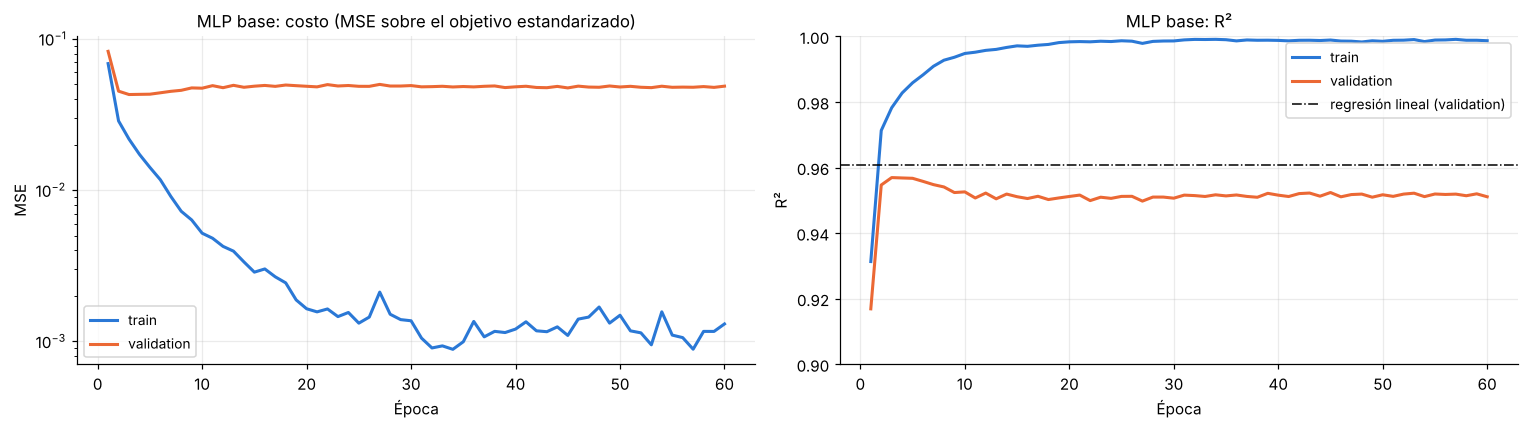

In [40]:
# 2b) Puntos de comparación: predecir la media, una regresión lineal y la MLP con la configuración base
lineal = LinearRegression().fit(Xs["train"], ys["train"])
R2_LINEAL = {s: r2_score(ys[s], lineal.predict(Xs[s])) for s in ("train", "validation")}
referencias = pd.DataFrame({
    "predecir siempre la media de train": {s: r2_score(ys[s], np.zeros_like(ys[s])) for s in ("train", "validation")},
    "regresión lineal (mismas features)": R2_LINEAL,
    "MLP base, última época": {"train": hist_base["r2_train"][-1], "validation": hist_base["r2_validation"][-1]},
    "MLP base, mejor época de validation": {"train": hist_base["r2_train"][mejor_base["epoca"] - 1], "validation": mejor_base["r2"]},
}).T
display(referencias.rename(columns=lambda c: f"R² {c}").style.format("{:.4f}"))

ep = np.arange(1, BASE["epocas"] + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ep, hist_base["loss_train"], color=C_TRAIN, label="train")
axes[0].plot(ep, hist_base["loss_validation"], color=C_VAL, label="validation")
axes[0].set_yscale("log"); axes[0].set_title("MLP base: costo (MSE sobre el objetivo estandarizado)"); axes[0].set_ylabel("MSE")
axes[1].plot(ep, hist_base["r2_train"], color=C_TRAIN, label="train")
axes[1].plot(ep, hist_base["r2_validation"], color=C_VAL, label="validation")
axes[1].axhline(R2_LINEAL["validation"], color="k", ls="-.", lw=1, label="regresión lineal (validation)")
axes[1].set_ylim(0.9, 1.0); axes[1].set_title("MLP base: R²"); axes[1].set_ylabel("R²")
for ax in axes: ax.set_xlabel("Época"); ax.legend()
plt.tight_layout(); plt.show()


Hay dos cosas para tener en cuenta en todo lo que sigue:

1. **La regresión lineal ya llega a R² 0,961 en validation.** Tiene una explicación: el gasto promedio de un cliente es, casi por definición, la suma de "qué fracción de sus compras fue de cada tipo de producto" multiplicada por "cuánto cuesta en promedio ese tipo de producto". Es una suma ponderada de nuestras features, o sea, una relación casi lineal. La red no tiene mucha estructura no lineal para descubrir con el historial completo.
2. **La MLP base sobreajusta muy rápido.** Su mejor R² de validation (0,957) aparece en la época 3. Desde ahí, train sigue subiendo hasta 0,999 y validation baja a 0,951. Con 5.202 clientes y 68 mil parámetros, la red memoriza train en pocas épocas. Por eso, en los experimentos, comparamos cada variante en su mejor época y miramos aparte cuánto sobreajusta.

**Cómo elegimos los hiperparámetros.** Cambiamos una cosa por vez y nos quedamos con la mejor antes de pasar a la siguiente: activación → función de costo → optimizador y learning rate → dropout → épocas. Cada variante se entrena con 3 semillas (cambian la inicialización y el orden de los mini-batches) y reportamos media y desvío. Las diferencias entre variantes a veces están en el tercer decimal, y sin repetir no sabríamos si son reales.

El criterio es el **R² de validation en la mejor época**, porque la red base sobreajusta muy rápido y la última época castiga a todas por igual. Igual mostramos el R² en la última época y el de train, que juntos dicen cuánto sobreajusta cada variante. Todos los experimentos usan 60 épocas y batch de 128.

,R² val (mejor época),± desvío,mejor época (mediana),R² val (última época),R² train (última época),seg por entrenamiento
variante,,,,,,
GELU,0.9577,0.0013,5,0.9485,0.9989,8.1
Sigmoid,0.9574,0.0005,19,0.9486,0.9995,6.9
LeakyReLU,0.9568,0.0009,4,0.9528,0.9991,7.4
ReLU,0.9568,0.0010,4,0.9525,0.9988,7.0
Tanh,0.9492,0.0010,8,0.9423,0.9987,7.1


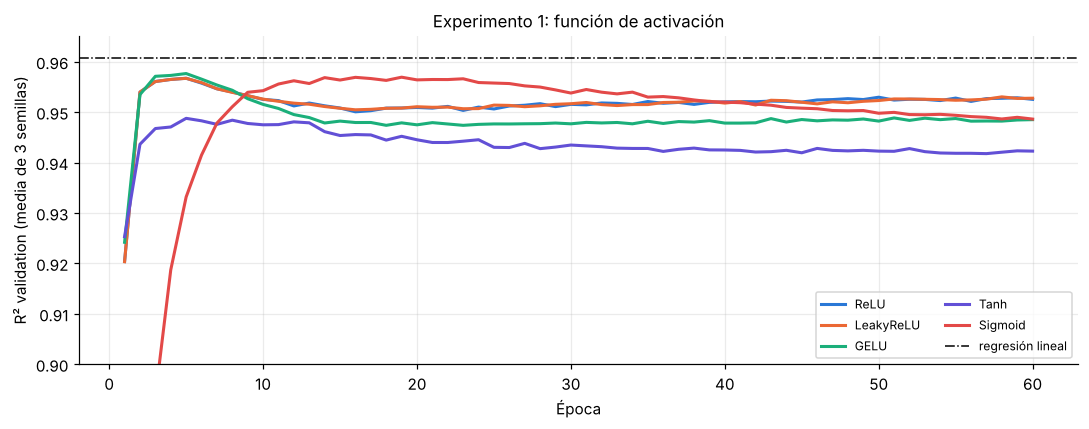

Mejor variante: GELU (+0.0009 sobre ReLU, desvío 0.0013) -> elegimos: ReLU


In [41]:
# 2b) Herramienta de experimentos: cada variante se entrena con 3 semillas y se resume con media ± desvío
SEMILLAS = (0, 1, 2)

def experimento(variantes, base, semillas=SEMILLAS):
    """Entrena cada variante (cambios sobre `base`) con varias semillas. Devuelve una tabla resumen y las historias."""
    filas, historias = [], {}
    for nombre, cambios in variantes.items():
        corridas = []
        for s in semillas:
            t0 = time.perf_counter()
            _, h, mejor = entrenar({**base, **cambios}, semilla=s)
            historias[(nombre, s)] = h
            corridas.append({"mejor": mejor["r2"], "epoca": mejor["epoca"], "final": h["r2_validation"][-1],
                             "train": h["r2_train"][-1], "seg": time.perf_counter() - t0})
        c = pd.DataFrame(corridas)
        filas.append({"variante": nombre,
                      "R² val (mejor época)": c["mejor"].mean(), "± desvío": c["mejor"].std(),
                      "mejor época (mediana)": c["epoca"].median(),
                      "R² val (última época)": c["final"].mean(),
                      "R² train (última época)": c["train"].mean(),
                      "seg por entrenamiento": c["seg"].mean()})
    return pd.DataFrame(filas).set_index("variante"), historias

FORMATO_EXP = {"R² val (mejor época)": "{:.4f}", "± desvío": "{:.4f}", "mejor época (mediana)": "{:.0f}",
               "R² val (última época)": "{:.4f}", "R² train (última época)": "{:.4f}", "seg por entrenamiento": "{:.1f}"}

def mostrar_experimento(tabla, historias, titulo, ylim=(0.90, 0.965), estilos=None):
    """Tabla ordenada + curvas de R² de validation (promedio de las semillas) de cada variante."""
    display(tabla.sort_values("R² val (mejor época)", ascending=False).style.format(FORMATO_EXP))
    fig, ax = plt.subplots(figsize=(10, 4))
    for i, nombre in enumerate(tabla.index):
        curvas = np.array([h["r2_validation"] for (n, _), h in historias.items() if n == nombre])
        color, ls = estilos[nombre] if estilos else (C_ACCENT[i % len(C_ACCENT)], "-")
        ax.plot(np.arange(1, curvas.shape[1] + 1), curvas.mean(axis=0), color=color, ls=ls, label=nombre)
    ax.axhline(R2_LINEAL["validation"], color="k", lw=1, ls="-.", label="regresión lineal")
    ax.set_ylim(*ylim); ax.set_xlabel("Época"); ax.set_ylabel("R² validation (media de 3 semillas)")
    ax.set_title(titulo); ax.legend(fontsize=8, ncol=2)
    plt.tight_layout(); plt.show()

DECISIONES = []

def elegir(tabla, por_defecto, experimento_nombre):
    """Regla de decisión: nos quedamos con la mejor variante solo si le gana a la opción por defecto por más que
    el desvío entre semillas. Si no, la diferencia es ruido y preferimos la opción estándar."""
    mejor = tabla["R² val (mejor época)"].idxmax()
    diferencia = tabla.loc[mejor, "R² val (mejor época)"] - tabla.loc[por_defecto, "R² val (mejor época)"]
    ruido = max(tabla.loc[mejor, "± desvío"], tabla.loc[por_defecto, "± desvío"])
    elegida = mejor if diferencia > ruido else por_defecto
    DECISIONES.append({"experimento": experimento_nombre, "opción por defecto": por_defecto, "mejor variante": mejor,
                       "diferencia de R²": diferencia, "desvío entre semillas": ruido, "elegida": elegida})
    print(f"Mejor variante: {mejor} (+{diferencia:.4f} sobre {por_defecto}, desvío {ruido:.4f}) -> elegimos: {elegida}")
    return elegida

# Experimento 1: función de activación de las capas ocultas
config = dict(BASE)
tabla_act, hist_act = experimento({a: {"activacion": a} for a in ACTIVACIONES}, config)
mostrar_experimento(tabla_act, hist_act, "Experimento 1: función de activación")
config["activacion"] = elegir(tabla_act, "ReLU", "activación")


**Activación.** GELU (0,9577), Sigmoid (0,9574), LeakyReLU y ReLU (0,9568) quedan a menos de un desvío entre semillas unas de otras (~0,001). Para estos datos son equivalentes. Por la regla de decisión nos quedamos con **ReLU**, la opción estándar, que además es la más simple de calcular.

Lo que sí se separa es **Tanh**, claramente última (0,9492). **Sigmoid** llega bien, pero tarda: su mejor época es la 19, contra la 4 de ReLU. Es lo mismo que vimos en la Pregunta 1: las funciones con forma de "S" se saturan, su derivada se vuelve casi cero en los extremos y el aprendizaje se frena. ReLU no se satura del lado positivo, así que el gradiente pasa sin achicarse.

,R² val (mejor época),± desvío,mejor época (mediana),R² val (última época),R² train (última época),seg por entrenamiento
variante,,,,,,
Huber,0.9572,0.0010,5,0.9539,0.9990,6.4
MSE,0.9568,0.0010,4,0.9525,0.9988,6.5
MAE (L1),0.9562,0.0006,5,0.9535,0.9988,6.8


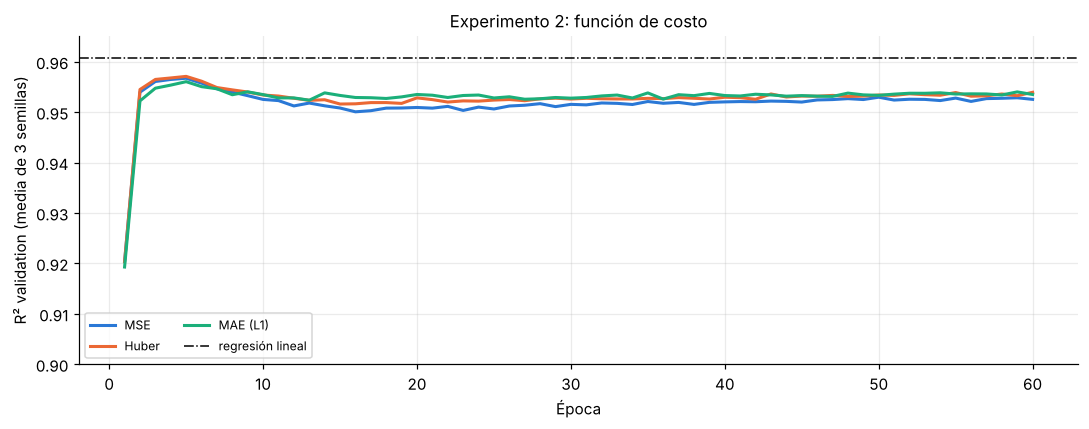

Mejor variante: Huber (+0.0003 sobre MSE, desvío 0.0010) -> elegimos: MSE


In [42]:
# Experimento 2: función de costo (el R² se mide igual para todas, sobre validation)
tabla_loss, hist_loss = experimento({p: {"perdida": p} for p in PERDIDAS}, config)
mostrar_experimento(tabla_loss, hist_loss, "Experimento 2: función de costo")
config["perdida"] = elegir(tabla_loss, "MSE", "función de costo")


**Función de costo.** Las tres quedan dentro del ruido (Huber 0,9572, MSE 0,9568, MAE 0,9562). Elegimos **MSE** por dos razones:

- El R² es justamente 1 − MSE / varianza del objetivo. Minimizar el MSE es optimizar directamente la métrica que pide la consigna.
- Huber y MAE sirven cuando hay valores atípicos que no conviene perseguir. Acá el objetivo es un promedio acotado (275 a 17.231), sin colas extremas, así que esa protección no aporta.

learning rate,0.0001,0.001,0.01
optimizador,,,
AMSGrad,0.9541,0.9568,0.9546
Adam,0.9540,0.9568,0.9544
AdamW,0.9541,0.9568,0.9545
SGD + momentum,0.8403,0.9459,0.9503


,R² val (mejor época),± desvío,mejor época (mediana),R² val (última época),R² train (última época),seg por entrenamiento
variante,,,,,,
"Adam, lr=0.001",0.9568,0.0010,4,0.9525,0.9988,6.1
"AdamW, lr=0.001",0.9568,0.0011,4,0.9531,0.9989,6.3
"AMSGrad, lr=0.001",0.9568,0.0011,4,0.9519,0.9998,6.3
"AMSGrad, lr=0.01",0.9546,0.0015,3,0.9509,0.9994,7.3
"AdamW, lr=0.01",0.9545,0.0017,3,0.9509,0.9976,6.8
"Adam, lr=0.01",0.9544,0.0019,3,0.9501,0.9985,6.1
"AMSGrad, lr=0.0001",0.9541,0.0018,21,0.9473,0.9977,6.5
"AdamW, lr=0.0001",0.9541,0.0018,21,0.9458,0.9985,6.9
"Adam, lr=0.0001",0.9540,0.0018,21,0.9458,0.9985,7.3


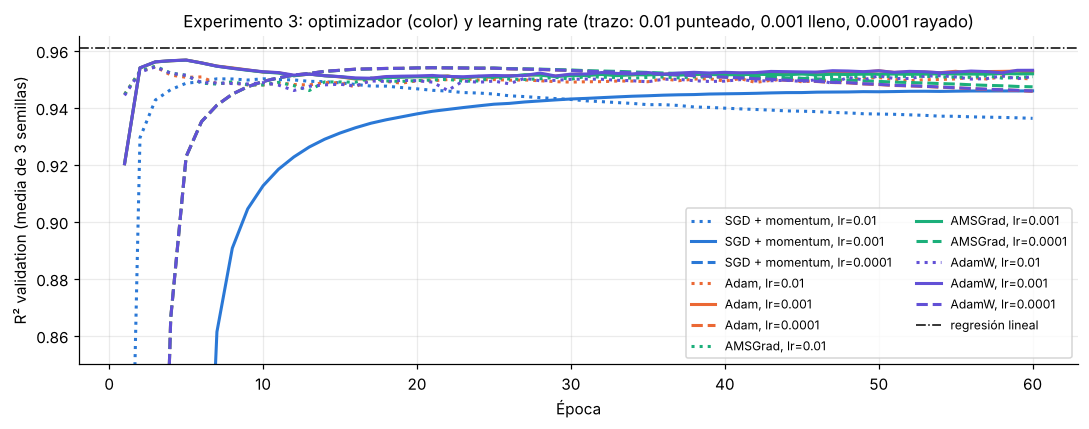

Mejor variante: Adam, lr=0.001 (+0.0000 sobre Adam, lr=0.001, desvío 0.0010) -> elegimos: Adam, lr=0.001


In [43]:
# Experimento 3: algoritmo de optimización x learning rate
# (AdamW usa weight decay desacoplado de 0.01, su valor por defecto en PyTorch)
variantes = {f"{o}, lr={lr:g}": {"optimizador": o, "lr": lr} for o in OPTIMIZADORES for lr in (1e-2, 1e-3, 1e-4)}
tabla_opt, hist_opt = experimento(variantes, config)
grilla = tabla_opt["R² val (mejor época)"].copy()
grilla.index = pd.MultiIndex.from_tuples([tuple(v.split(", lr=")) for v in grilla.index], names=["optimizador", "learning rate"])
display(grilla.unstack().style.format("{:.4f}").set_caption("R² de validation en la mejor época (media de 3 semillas)"))
COLOR_OPTIM = dict(zip(OPTIMIZADORES, C_ACCENT))
TRAZO_LR = {1e-2: ":", 1e-3: "-", 1e-4: "--"}
estilos = {nombre: (COLOR_OPTIM[c["optimizador"]], TRAZO_LR[c["lr"]]) for nombre, c in variantes.items()}
mostrar_experimento(tabla_opt, hist_opt, "Experimento 3: optimizador (color) y learning rate (trazo: 0.01 punteado, 0.001 lleno, 0.0001 rayado)",
                    ylim=(0.85, 0.965), estilos=estilos)
mejor_opt = elegir(tabla_opt, "Adam, lr=0.001", "optimizador y learning rate")
config.update(variantes[mejor_opt])


**Optimizador y learning rate.** La grilla es lo más informativo de 2b:

- **Adam, AdamW y AMSGrad dan prácticamente lo mismo** con cada learning rate (por ejemplo, 0,95684 / 0,95683 / 0,95682 con lr = 0,001). AMSGrad (Reddi et al., 2018, *On the convergence of Adam and beyond*) corrige un caso en el que Adam puede no converger porque "olvida" gradientes grandes. AdamW desacopla el weight decay del paso adaptativo. Ninguna de las dos situaciones aparece en este problema.
- **El learning rate pesa más que el optimizador.** Con 0,01 la red llega a su mejor punto en 3 épocas y después oscila (0,9545). Con 0,0001 necesita 21 épocas y en 60 no termina de alcanzar a 0,001 (0,9540). 0,001, el valor por defecto que proponen Kingma y Ba (2015), es el mejor equilibrio.
- **SGD con momentum depende muchísimo del learning rate:** 0,950 con 0,01, 0,946 con 0,001 (y necesita casi las 60 épocas) y 0,84 con 0,0001, que no alcanza a aprender en 60 épocas. Es el mismo fenómeno de la Pregunta 1: un descenso por gradiente con paso chico avanza en proporción a la pendiente y se queda corto. Adam normaliza el paso por parámetro y es mucho menos sensible a esa elección (Ruder, 2016, *An overview of gradient descent optimization algorithms*).

Elegimos **Adam con lr = 0,001**.

,R² val (mejor época),± desvío,mejor época (mediana),R² val (última época),R² train (última época),seg por entrenamiento
variante,,,,,,
dropout 0.0,0.9568,0.0010,4,0.9525,0.9988,6.6
dropout 0.1,0.9553,0.0020,6,0.9503,0.9959,7.6
dropout 0.2,0.9548,0.0007,12,0.9510,0.9942,8.4
dropout 0.3,0.9540,0.0016,14,0.9495,0.9905,8.9


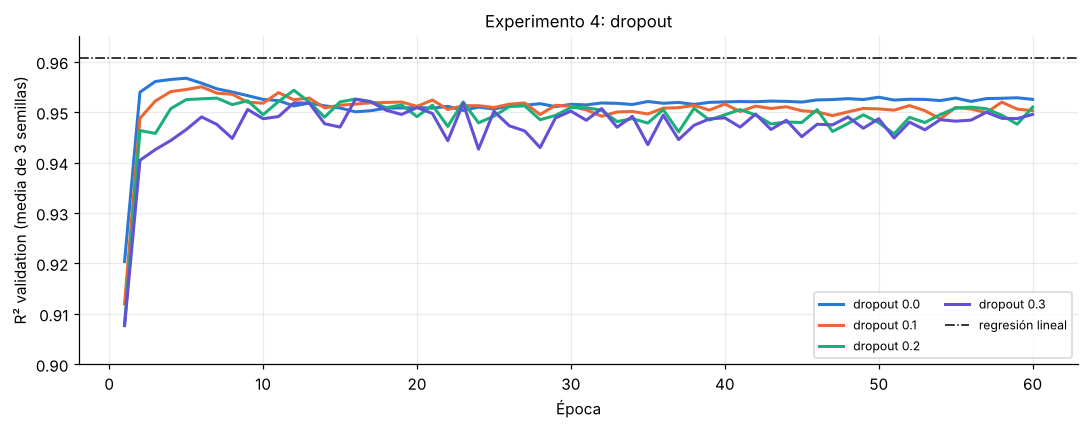

Mejor variante: dropout 0.0 (+0.0000 sobre dropout 0.0, desvío 0.0010) -> elegimos: dropout 0.0


In [44]:
# Experimento 4 (opcional de la consigna): regularización con dropout en las capas ocultas
tabla_drop, hist_drop = experimento({f"dropout {d}": {"dropout": d} for d in (0.0, 0.1, 0.2, 0.3)}, config)
mostrar_experimento(tabla_drop, hist_drop, "Experimento 4: dropout")
config["dropout"] = float(elegir(tabla_drop, "dropout 0.0", "dropout").split()[-1])


**Dropout.** Empeora de forma monótona: 0,9568 sin dropout, 0,9553 con 0,1, 0,9548 con 0,2 y 0,9540 con 0,3. Sí reduce la memorización (el R² de train en la última época baja de 0,999 a 0,990), pero eso no se traduce en mejor validation. El error que queda no viene de que la red memorice, porque eso ya lo resolvemos cortando a tiempo. Viene de lo que las features no pueden explicar. Por eso nos quedamos **sin dropout** para este modelo. En 2c el dropout vuelve a aparecer, en un escenario donde sí ayuda.

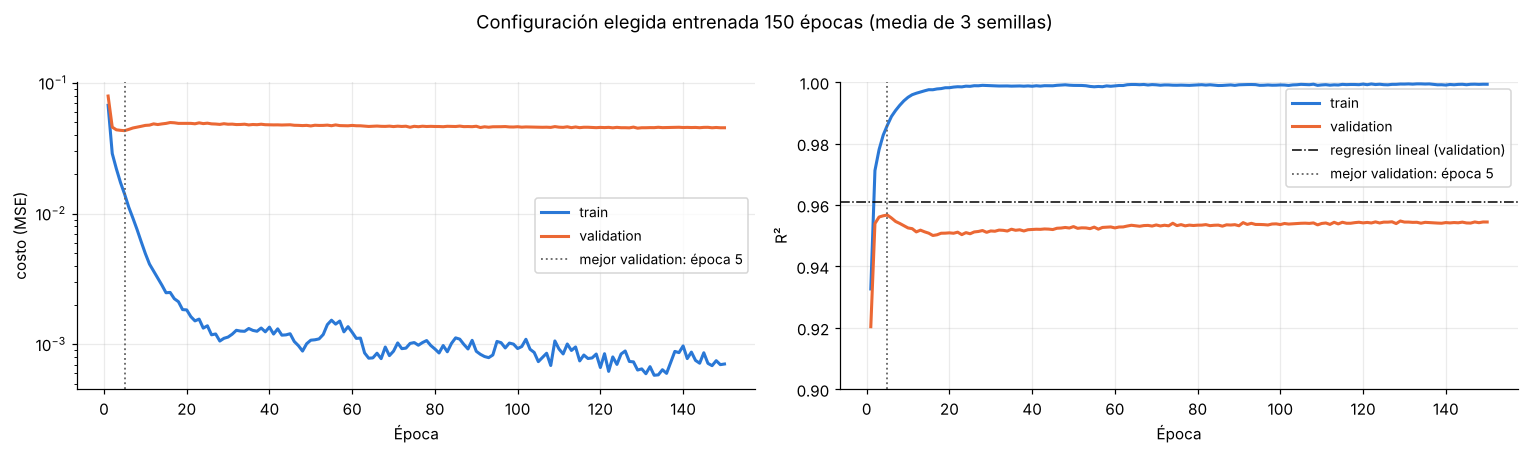

,opción por defecto,mejor variante,diferencia de R²,desvío entre semillas,elegida
experimento,,,,,
activación,ReLU,GELU,+0.0009,0.0013,ReLU
función de costo,MSE,Huber,+0.0003,0.0010,MSE
optimizador y learning rate,"Adam, lr=0.001","Adam, lr=0.001",+0.0000,0.0010,"Adam, lr=0.001"
dropout,dropout 0.0,dropout 0.0,+0.0000,0.0010,dropout 0.0


R² validation máximo 0.9567 en la época 5; en la época 150: 0.9544 (train 0.9993)
Configuración final: {'ocultas': (128, 64, 32), 'activacion': 'ReLU', 'dropout': 0.0, 'perdida': 'MSE', 'optimizador': 'Adam', 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 128, 'epocas': 5}


In [45]:
# Experimento 5: ¿cuántas épocas? Entrenamos la configuración elegida más tiempo y miramos dónde deja de mejorar validation
EPOCAS_LARGO = 150
largas = [entrenar({**config, "epocas": EPOCAS_LARGO}, semilla=s)[1] for s in SEMILLAS]
r2_tr = np.mean([h["r2_train"] for h in largas], axis=0)
r2_va = np.mean([h["r2_validation"] for h in largas], axis=0)
l_tr = np.mean([h["loss_train"] for h in largas], axis=0)
l_va = np.mean([h["loss_validation"] for h in largas], axis=0)
EPOCAS_FINAL = int(np.argmax(r2_va) + 1)

ep = np.arange(1, EPOCAS_LARGO + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ep, l_tr, color=C_TRAIN, label="train"); axes[0].plot(ep, l_va, color=C_VAL, label="validation")
axes[0].set_yscale("log"); axes[0].set_ylabel(f"costo ({config['perdida']})")
axes[1].plot(ep, r2_tr, color=C_TRAIN, label="train"); axes[1].plot(ep, r2_va, color=C_VAL, label="validation")
axes[1].axhline(R2_LINEAL["validation"], color="k", lw=1, ls="-.", label="regresión lineal (validation)")
axes[1].set_ylim(0.9, 1.0); axes[1].set_ylabel("R²")
for ax in axes:
    ax.axvline(EPOCAS_FINAL, color="0.4", ls=":", lw=1.2, label=f"mejor validation: época {EPOCAS_FINAL}")
    ax.set_xlabel("Época"); ax.legend()
fig.suptitle(f"Configuración elegida entrenada {EPOCAS_LARGO} épocas (media de 3 semillas)", y=1.02)
plt.tight_layout(); plt.show()

config["epocas"] = EPOCAS_FINAL
display(pd.DataFrame(DECISIONES).set_index("experimento").style.format({"diferencia de R²": "{:+.4f}", "desvío entre semillas": "{:.4f}"})
        .set_caption("Resumen de decisiones de 2b"))
print(f"R² validation máximo {r2_va.max():.4f} en la época {EPOCAS_FINAL}; en la época {EPOCAS_LARGO}: {r2_va[-1]:.4f} "
      f"(train {r2_tr[-1]:.4f})")
CONFIG_FINAL = dict(config)
print("Configuración final:", CONFIG_FINAL)


**Épocas.** Con la configuración elegida, el R² de validation llega a su máximo (0,9567) en la **época 5**. Desde ahí baja muy despacio (0,9544 en la época 150), mientras train sigue subiendo hasta 0,999 y su costo cae dos órdenes de magnitud. Es sobreajuste de manual: después de unas 5 épocas (unas 200 actualizaciones con batch de 128) la red ya aprendió lo generalizable y el resto es memorizar a los clientes de train.

Por eso, en lugar de fijar un número exacto, en 2c entrenamos con **early stopping**: dejamos correr hasta 60 épocas y nos quedamos con los pesos de la época con mejor validation. Así el corte se adapta a cada entrenamiento.

**Configuración final de 2b:** 3 capas ocultas (128, 64, 32) con ReLU, salida lineal, MSE, Adam con lr = 0,001, batch de 128, sin dropout y con early stopping. La tabla de decisiones resume el criterio: en ningún experimento una alternativa le ganó a la opción estándar por más que el ruido entre semillas. Para estos datos, la elección de hiperparámetros importa mucho menos que las features y que el momento en que se corta el entrenamiento.

### 2c) Evaluación del Modelo (1 punto)
- Graficar las evoluciones por época de la función de costo y del $R^2$, tanto para el set de train como el de validation.
- Gráfica scatter de Real VS Predicho en el set de validation.
- Explicar el proceso estratégico de iteracion utilizado para conseguir los mejores resultados y justificar los resultados obtenidos.
- Un resultado aceptable sería un $R^2$ de por lo menos 0.70 para el set de validation.

#### Resolución 2c)

Entrenamos el modelo final con la configuración elegida en 2b y la semilla del TP, y lo evaluamos de cuatro maneras: las curvas por época que pide la consigna, real vs predicho en validation, una reconstrucción del camino de iteración y una prueba del caso de uso real (clientes nuevos con pocas compras).

In [46]:
# 2c) Modelo final: configuración elegida en 2b, entrenada con la semilla del TP
# Entrenamos durante el mismo horizonte de los experimentos (60 épocas) para ver toda la curva, y nos quedamos
# con los pesos de la mejor época de validation (early stopping), que es lo que concluimos en el experimento 5.
modelo_final, hist_final, mejor_final = entrenar({**CONFIG_FINAL, "epocas": BASE["epocas"]}, semilla=SEED_P2)
modelo_final.load_state_dict(mejor_final["estado"])
E_STOP = mejor_final["epoca"]
print("Configuración:", {**CONFIG_FINAL, "epocas": f"hasta {BASE['epocas']}, con early stopping"})
print(f"Mejor época de validation: {E_STOP} (el experimento 5 sugería {EPOCAS_FINAL})")
print(f"R² en la época elegida -> train {hist_final['r2_train'][E_STOP - 1]:.4f} | validation {hist_final['r2_validation'][E_STOP - 1]:.4f}")
print(f"R² si siguiéramos hasta la época {BASE['epocas']} -> train {hist_final['r2_train'][-1]:.4f} | validation {hist_final['r2_validation'][-1]:.4f}")

def predecir_pesos(modelo, X):
    """Predicción del modelo devuelta a la escala original (pesos)."""
    modelo.eval()
    with torch.no_grad():
        return modelo(torch.tensor(X)).numpy().ravel() * Y_DESVIO + Y_MEDIA


Configuración: {'ocultas': (128, 64, 32), 'activacion': 'ReLU', 'dropout': 0.0, 'perdida': 'MSE', 'optimizador': 'Adam', 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 128, 'epocas': 'hasta 60, con early stopping'}
Mejor época de validation: 3 (el experimento 5 sugería 5)
R² en la época elegida -> train 0.9782 | validation 0.9569
R² si siguiéramos hasta la época 60 -> train 0.9987 | validation 0.9511


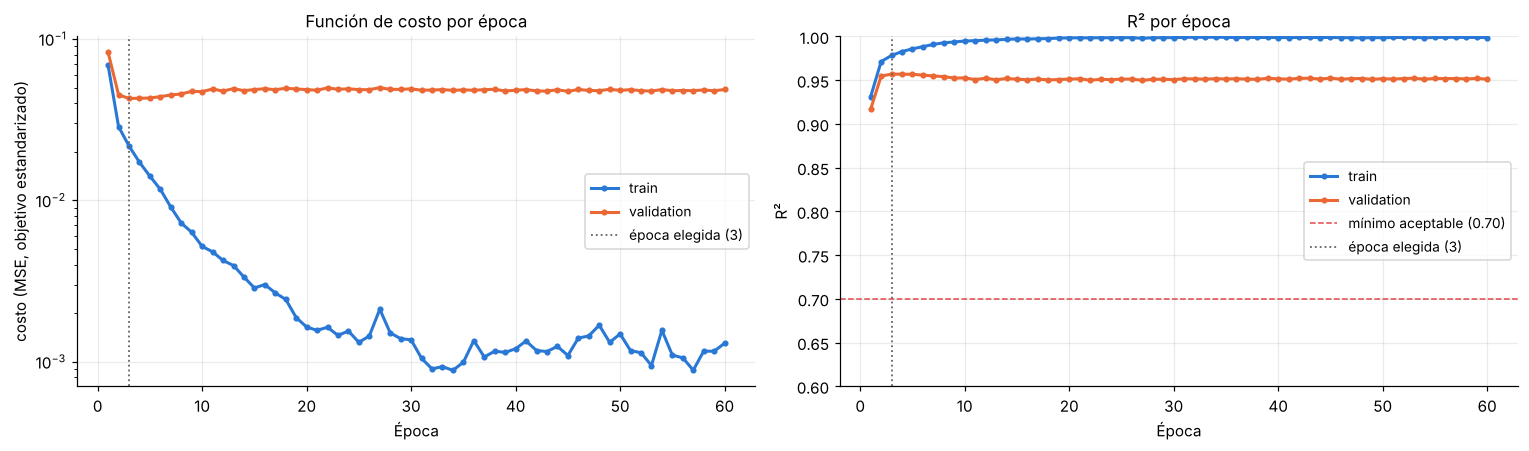

In [47]:
# 2c) Evolución por época del costo y del R² (train y validation) del modelo final
ep = np.arange(1, len(hist_final["r2_train"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(ep, hist_final["loss_train"], "o-", ms=3, color=C_TRAIN, label="train")
axes[0].plot(ep, hist_final["loss_validation"], "o-", ms=3, color=C_VAL, label="validation")
axes[0].set_ylabel(f"costo ({CONFIG_FINAL['perdida']}, objetivo estandarizado)"); axes[0].set_yscale("log")
axes[0].set_title("Función de costo por época")
axes[1].plot(ep, hist_final["r2_train"], "o-", ms=3, color=C_TRAIN, label="train")
axes[1].plot(ep, hist_final["r2_validation"], "o-", ms=3, color=C_VAL, label="validation")
axes[1].axhline(0.70, color="#e34948", lw=1, ls="--", label="mínimo aceptable (0.70)")
axes[1].set_ylabel("R²"); axes[1].set_title("R² por época")
axes[1].set_ylim(min(0.6, hist_final["r2_validation"].min() - 0.02), 1.0)
for ax in axes:
    ax.axvline(E_STOP, color="0.4", ls=":", lw=1.2, label=f"época elegida ({E_STOP})")
    ax.set_xlabel("Época"); ax.legend()
plt.tight_layout(); plt.show()


Las curvas muestran el mismo patrón que en los experimentos. Con la semilla del TP, la mejor época de validation es la **3**: ahí el R² es 0,978 en train y **0,957 en validation**. Si dejáramos entrenar hasta la época 60, train llegaría a 0,999 y validation bajaría a 0,951. El costo lo muestra todavía más claro: el MSE de train cae dos órdenes de magnitud mientras el de validation queda plano desde la época 3. Todo lo que la red aprende después es específico de los clientes de train.

El modelo final usa los pesos de la época 3 y supera con amplitud el mínimo aceptable de 0,70.

Validation: R² 0.9569 | MAE 535 | RMSE 684 | error relativo medio 10.6%


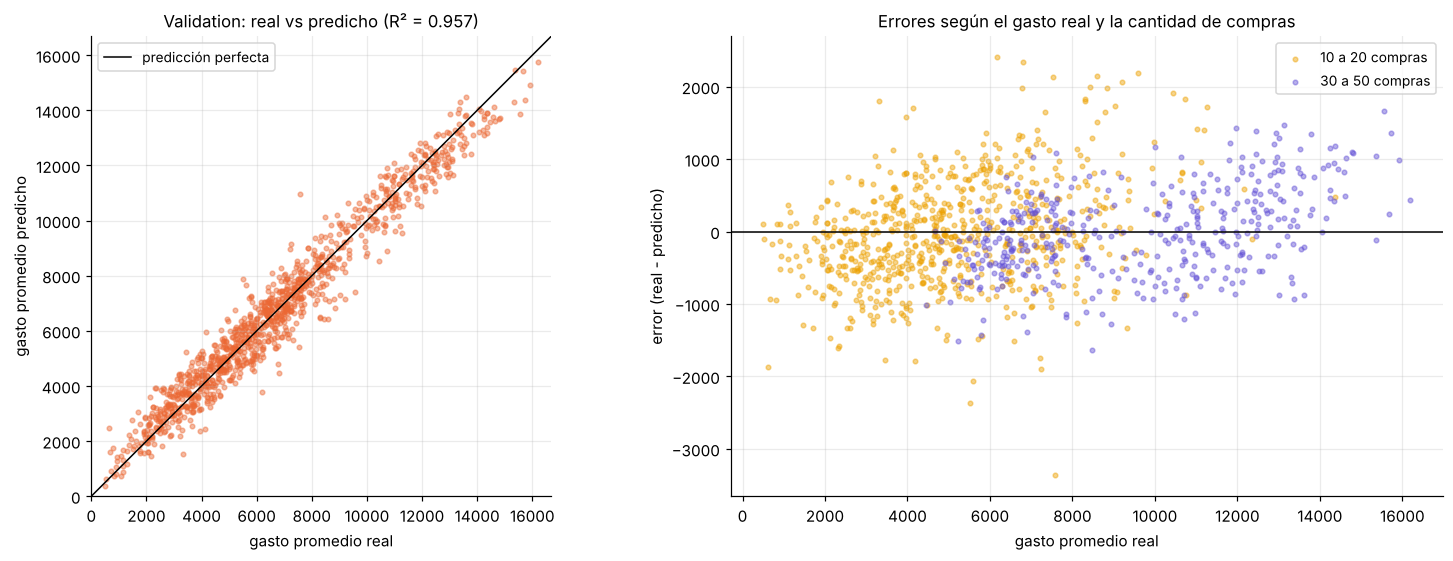

,clientes,MAE
10 a 20 compras,720,563
30 a 50 compras,395,484


In [48]:
# 2c) Real vs predicho en validation (en pesos)
y_val = y_sets["validation"].to_numpy()
p_val = predecir_pesos(modelo_final, Xs["validation"])
residuo = y_val - p_val
mae, rmse = np.mean(np.abs(residuo)), np.sqrt(np.mean(residuo ** 2))
print(f"Validation: R² {r2_score(y_val, p_val):.4f} | MAE {mae:,.0f} | RMSE {rmse:,.0f} | "
      f"error relativo medio {np.mean(np.abs(residuo) / y_val):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
lim = [0, max(y_val.max(), p_val.max()) * 1.03]
axes[0].scatter(y_val, p_val, s=9, alpha=0.45, color=C_VAL)
axes[0].plot(lim, lim, color="k", lw=1, label="predicción perfecta")
axes[0].set_xlim(lim); axes[0].set_ylim(lim); axes[0].set_aspect("equal")
axes[0].set_xlabel("gasto promedio real"); axes[0].set_ylabel("gasto promedio predicho")
axes[0].set_title(f"Validation: real vs predicho (R² = {r2_score(y_val, p_val):.3f})"); axes[0].legend()

n_val = compras_por_cliente.loc[y_sets["validation"].index].to_numpy()
for etiqueta, mascara, color in [("10 a 20 compras", n_val <= 20, C_ACCENT[5]), ("30 a 50 compras", n_val >= 30, C_ACCENT[3])]:
    axes[1].scatter(y_val[mascara], residuo[mascara], s=9, alpha=0.45, color=color, label=etiqueta)
axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("gasto promedio real"); axes[1].set_ylabel("error (real - predicho)")
axes[1].set_title("Errores según el gasto real y la cantidad de compras"); axes[1].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({"clientes": [np.sum(n_val <= 20), np.sum(n_val >= 30)],
                      "MAE": [np.mean(np.abs(residuo[n_val <= 20])), np.mean(np.abs(residuo[n_val >= 30]))]},
                     index=["10 a 20 compras", "30 a 50 compras"]).style.format("{:,.0f}"))


- En validation el modelo tiene R² **0,957**, error absoluto medio de **535** y error relativo medio de 10,6%. Los puntos siguen la diagonal en todo el rango, incluido el segundo grupo de clientes con gasto alto (alrededor de 12.000).
- Los errores son más chicos para los clientes con más compras (MAE 484 con 30-50 compras, contra 563 con 10-20). Tiene sentido: con más compras, las proporciones describen mejor los gustos reales del cliente.
- En los clientes de gasto más alto, el modelo tiende a quedarse un poco corto (residuos mayormente positivos a la derecha). Es el típico "encogimiento hacia la media" de un modelo entrenado con MSE en los extremos de la distribución.

**Proceso de iteración.** Iteramos en dos ejes: qué información le damos a la red (features) y cómo la entrenamos (hiperparámetros). La primera tabla agrega los grupos de features de a uno, siempre con la configuración final de la red. La segunda reconstruye cómo cambió el resultado con cada decisión de 2b.

In [49]:
# 2c) Proceso de iteración (1): qué aportó cada grupo de features, con la configuración de la red de 2b
def tensores_con(columnas, origen=None):
    """Tensores de train/validation usando solo un subconjunto de columnas (ya escaladas)."""
    idx = [FEATURES.index(c) for c in columnas]
    return {s: (torch.tensor(Xs[s][:, idx]), torch.tensor(ys[s]).unsqueeze(1)) for s in ("train", "validation")}

etapas = {
    "1. solo demografía": GRUPOS["demografía"],
    "2. solo gustos por categoría": GRUPOS["gustos por categoría"],
    "3. demografía + categoría": GRUPOS["demografía"] + GRUPOS["gustos por categoría"],
    "4. + subcategorías 1 y 2": GRUPOS["demografía"] + GRUPOS["gustos por categoría"]
                                + GRUPOS["gustos por subcategoría 1"] + GRUPOS["gustos por subcategoría 2"],
    "5. + combinación categoría-subcategoría 1": FEATURES,
}
filas = []
for nombre, cols in etapas.items():
    datos = tensores_con(cols)
    r2_mlp = [entrenar(CONFIG_FINAL, semilla=s, datos=datos)[2]["r2"] for s in SEMILLAS]
    lin = LinearRegression().fit(datos["train"][0].numpy(), ys["train"])
    filas.append({"features": nombre, "columnas": len(cols), "R² val MLP (media 3 semillas)": np.mean(r2_mlp),
                  "± desvío": np.std(r2_mlp, ddof=1),
                  "R² val regresión lineal": r2_score(ys["validation"], lin.predict(datos["validation"][0].numpy()))})
display(pd.DataFrame(filas).set_index("features").style.format(
    {"R² val MLP (media 3 semillas)": "{:.4f}", "± desvío": "{:.4f}", "R² val regresión lineal": "{:.4f}"})
    .set_caption("Iteración sobre las features (red de 2b, mejor época de validation)"))


,columnas,R² val MLP (media 3 semillas),± desvío,R² val regresión lineal
features,,,,
1. solo demografía,5,0.3500,0.0019,0.2697
2. solo gustos por categoría,20,0.9435,0.0013,0.9428
3. demografía + categoría,25,0.9418,0.0026,0.9427
4. + subcategorías 1 y 2,76,0.9449,0.0020,0.9462
5. + combinación categoría-subcategoría 1,450,0.9568,0.0010,0.9608


- **Demografía sola: R² 0,35.** Es el único escenario donde la red le gana con claridad a la regresión lineal (0,27). La edad tiene un efecto que sube y después baja, y la antigüedad tiene un salto, así que hay algo no lineal que aprovechar.
- **Los gustos por categoría solos ya dan 0,944.** Agregarles la demografía no suma nada (0,942): una vez que se sabe qué compra el cliente, su edad o su ciudad no agregan información sobre cuánto gasta. La demografía influye en el gasto a través de lo que la persona elige comprar.
- **Las subcategorías suman poco** (0,945). Lo que más aporta es la **combinación categoría-subcategoría 1** (0,957, +0,012), porque el precio depende de la combinación y no de cada código por separado (85% del precio explicado, contra 76% de la categoría sola).
- En todos los pasos con gustos, la regresión lineal empata o le gana a la red. Es coherente con lo que anticipamos en 2b: con el historial completo, el gasto promedio es casi una suma ponderada de las proporciones de compra.

En resumen, la mejora vino de las **features** (de 0,944 a 0,957) y de **cortar a tiempo** (de 0,951 a 0,957). Los hiperparámetros, según la tabla de decisiones de 2b, movieron el resultado menos que el ruido entre semillas.

**El caso de uso real: clientes nuevos.** El enunciado dice que el modelo se va a usar con clientes que "solo llevan unas pocas visitas y compras". Todos los clientes del dataset tienen al menos 10 compras, así que lo simulamos: para cada cliente de validation elegimos al azar k de sus compras, armamos sus features solo con esas k y comparamos la predicción contra su gasto promedio real, el de todas sus compras. Repetimos el sorteo 5 veces por cada k.

Lo comparamos con la forma más directa de estimar el gasto de un cliente nuevo sin ningún modelo: promediar lo que pagó en esas k compras.

,MLP de 2b,regresión lineal,promedio de lo que pagó en esas k compras
compras observadas (k),,,
1,-3.629,-3.501,-3.789
3,-0.365,-0.378,-0.421
5,0.291,0.270,0.270
10,0.740,0.733,0.759
todas,0.957,0.961,nan


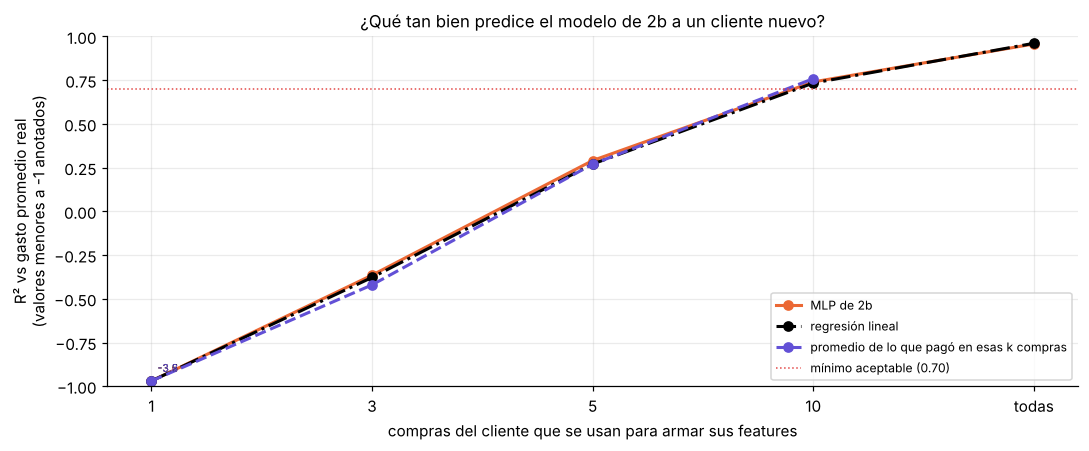

In [50]:
# 2c) El caso de uso real: clientes nuevos con pocas compras
# Para cada cliente de validation tomamos al azar k de sus compras, armamos las features SOLO con esas k
# y comparamos la predicción contra su gasto promedio real (el de todas sus compras).
def recortar(tx_clientes, k, semilla):
    """Se queda con k compras al azar de cada cliente (todas si k == "todas")."""
    if k == "todas":
        return tx_clientes
    mezcla = tx_clientes.sample(frac=1, random_state=semilla)
    return mezcla[mezcla.groupby("User_ID").cumcount() < k]

def escenario(tx_clientes, k, semilla):
    """Features escaladas armadas con k compras por cliente, el objetivo real y el promedio de lo pagado en esas k."""
    sub = recortar(tx_clientes, k, semilla)
    F = armar_features(sub)
    return {"k": k, "X": escalador.transform(F[FEATURES]).astype(np.float32),
            "y": target.loc[F.index].to_numpy(),
            "ingenuo": sub.groupby("User_ID")["Purchase"].mean().loc[F.index].to_numpy()}

K_VALORES = [1, 3, 5, 10, "todas"]
REPETICIONES = 5
ESC_VAL = {k: [escenario(tx_split["validation"], k, 1000 * r + i) for r in range(REPETICIONES if k != "todas" else 1)]
           for i, k in enumerate(K_VALORES)}

lineal_final = LinearRegression().fit(Xs["train"], ys["train"])   # referencia: regresión lineal con las mismas features

def tabla_escenarios(predictores, escenarios):
    """R² medio (sobre las repeticiones) de cada predictor en cada escenario de k compras.
    Un predictor puede devolver None en un escenario donde no tiene sentido (queda vacío)."""
    def r2_medio(f, reps):
        r = [r2_score(e["y"], p) for e in reps if (p := f(e)) is not None]
        return np.mean(r) if r else np.nan
    return pd.DataFrame({nombre: {str(k): r2_medio(f, reps) for k, reps in escenarios.items()}
                         for nombre, f in predictores.items()}).rename_axis("compras observadas (k)")

PRED_2B = {
    "MLP de 2b": lambda e: predecir_pesos(modelo_final, e["X"]),
    "regresión lineal": lambda e: lineal_final.predict(e["X"]) * Y_DESVIO + Y_MEDIA,
    "promedio de lo que pagó en esas k compras": lambda e: None if e["k"] == "todas" else e["ingenuo"],   # con todas es el objetivo
}
nuevos = tabla_escenarios(PRED_2B, ESC_VAL)
display(nuevos.style.format("{:.3f}").set_caption("R² en validation según cuántas compras del cliente se conocen"))

def graficar_escenarios(tabla, titulo, estilos):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    for col in tabla.columns:
        color, ls = estilos[col]
        valores = tabla[col].to_numpy()
        ax.plot(tabla.index, np.clip(valores, -0.97, None), "o", ls=ls, color=color, label=col)
        for x, v in zip(tabla.index, valores):
            if v < -1:   # fuera de escala: lo marcamos con su valor
                ax.annotate(f"{v:.1f}", (x, -0.97), xytext=(4, 6), textcoords="offset points", fontsize=7, color=color)
    ax.axhline(0.70, color="#e34948", lw=1, ls=":", label="mínimo aceptable (0.70)")
    ax.set_ylim(-1.0, 1.0)
    ax.set_xlabel("compras del cliente que se usan para armar sus features")
    ax.set_ylabel("R² vs gasto promedio real\n(valores menores a -1 anotados)")
    ax.set_title(titulo); ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout(); plt.show()

ESTILOS = {"MLP de 2b": (C_VAL, "-"), "regresión lineal": ("k", "-."),
           "promedio de lo que pagó en esas k compras": (C_ACCENT[3], "--"),
           "regresión lineal con recortes": (C_ACCENT[5], "-."),
           "MLP robusta (entrenada con recortes)": (C_TEST, "-")}
graficar_escenarios(nuevos, "¿Qué tan bien predice el modelo de 2b a un cliente nuevo?", ESTILOS)


**El modelo de 2b no sirve para el caso de uso que plantea el enunciado.** Con el historial completo da 0,957, pero con 10 compras baja a 0,74, con 5 a 0,29, con 3 a -0,37 y con una sola a -3,6. Con pocas compras es mucho peor que predecir siempre el promedio. La regresión lineal falla exactamente igual, y también la estimación ingenua (promediar lo que pagó en esas k compras).

La causa es que en train todos los clientes tienen entre 10 y 50 compras, así que la red nunca vio un perfil armado con 1 o 3 compras. Si de un cliente solo conocemos una compra en la categoría 13 (productos de 12.000 a 30.000), su perfil dice "100% categoría 13" y la red predice un gasto promedio altísimo, cuando lo más probable es que el resto de sus compras sea de categorías más baratas. La red toma esas pocas compras como si fueran un historial completo.

**Iteración guiada por el caso de uso: entrenar con historiales recortados.** El problema anterior tiene una causa clara: en train todos los clientes tienen al menos 10 compras, así que la red nunca vio un perfil armado con 1 o 3 compras (por ejemplo, 100% de una sola categoría). Frente a esos perfiles extrapola sin ninguna prudencia.

La solución es mostrárselos durante el entrenamiento. Para cada cliente de train generamos versiones con k compras al azar (k = 1, 2, 3, 5, 8, 13 y todas, con dos sorteos de cada una), siempre con el mismo objetivo: su gasto promedio real. Así la red aprende que un perfil construido con pocas compras es poco confiable y conviene predecir algo más moderado. Es una forma de *data augmentation*: no inventamos clientes, mostramos a los mismos clientes con menos información.

La época se elige (early stopping) por el R² promedio de validation en los escenarios k = 1, 3, 5, 10 y todas. Probamos tres variantes y, como referencia, una regresión lineal entrenada con los mismos datos aumentados.

In [51]:
# 2c) Iteración (2): entrenar con historiales recortados, para que el modelo aprenda a predecir con pocas compras
K_AUMENTO = [1, 2, 3, 5, 8, 13, "todas"]   # tamaños de historial que simulamos para cada cliente de train
COPIAS = 2                                  # dos sorteos distintos de cada tamaño
COLS_COMPACTAS = (GRUPOS["demografía"] + GRUPOS["gustos por categoría"]
                  + GRUPOS["gustos por subcategoría 1"] + GRUPOS["gustos por subcategoría 2"])

def aumentar(columnas):
    """Train aumentado: cada cliente aparece varias veces, con features armadas sobre k compras al azar,
    siempre con el mismo objetivo (su gasto promedio real)."""
    idx = [FEATURES.index(c) for c in columnas]
    X_, y_ = [], []
    for copia in range(COPIAS):
        for i, k in enumerate(K_AUMENTO):
            e = escenario(tx_split["train"], k, 50_000 + 100 * copia + i)
            X_.append(e["X"][:, idx]); y_.append((e["y"] - Y_MEDIA) / Y_DESVIO)
    return torch.tensor(np.vstack(X_)), torch.tensor(np.concatenate(y_).astype(np.float32)).unsqueeze(1)

ESC_SEL = {k: reps[0] for k, reps in ESC_VAL.items()}   # un sorteo por k para elegir la época (early stopping)

def entrenar_robusto(columnas, config, semilla=SEED_P2, epocas=40):
    """Como `entrenar`, pero sobre el train aumentado. La época se elige por el R² medio en los escenarios de validation."""
    idx = [FEATURES.index(c) for c in columnas]
    Xa, ya = aumentar(columnas)
    torch.manual_seed(semilla)
    cargador = DataLoader(TensorDataset(Xa, ya), batch_size=config["batch_size"], shuffle=True,
                          generator=torch.Generator().manual_seed(semilla))
    modelo = MLP(len(columnas), config["ocultas"], config["activacion"], config["dropout"])
    perdida_fn = PERDIDAS[config["perdida"]]()
    opt = OPTIMIZADORES[config["optimizador"]](modelo.parameters(), config["lr"], config["weight_decay"])
    hist = {"loss_train": [], "loss_validation": [], **{f"r2_k={k}": [] for k in ESC_SEL}, "r2_medio": []}
    mejor = {"r2": -np.inf, "epoca": 0, "estado": None}
    for epoca in range(1, epocas + 1):
        modelo.train()
        for xb, yb in cargador:
            opt.zero_grad(); perdida_fn(modelo(xb), yb).backward(); opt.step()
        modelo.eval()
        with torch.no_grad():
            hist["loss_train"].append(perdida_fn(modelo(Xa), ya).item())
            Xv = torch.tensor(np.vstack([e["X"][:, idx] for e in ESC_SEL.values()]))
            yv = torch.tensor(np.concatenate([(e["y"] - Y_MEDIA) / Y_DESVIO for e in ESC_SEL.values()]).astype(np.float32)).unsqueeze(1)
            hist["loss_validation"].append(perdida_fn(modelo(Xv), yv).item())
            r2s = [r2_score(e["y"], modelo(torch.tensor(e["X"][:, idx])).numpy().ravel() * Y_DESVIO + Y_MEDIA)
                   for e in ESC_SEL.values()]
        for k, r in zip(ESC_SEL, r2s):
            hist[f"r2_k={k}"].append(r)
        hist["r2_medio"].append(np.mean(r2s))
        if hist["r2_medio"][-1] > mejor["r2"]:
            mejor = {"r2": hist["r2_medio"][-1], "epoca": epoca,
                     "estado": {n: v.clone() for n, v in modelo.state_dict().items()}}
    modelo.load_state_dict(mejor["estado"])
    return modelo, {n: np.array(v) for n, v in hist.items()}, mejor

variantes_robustas = {
    "450 features + recortes": (FEATURES, CONFIG_FINAL),
    "76 features + recortes": (COLS_COMPACTAS, CONFIG_FINAL),
    "76 features + recortes + dropout 0.2": (COLS_COMPACTAS, {**CONFIG_FINAL, "dropout": 0.2}),
}
robustos, filas = {}, []
fila_2b = {k: r2_score(e["y"], predecir_pesos(modelo_final, e["X"])) for k, e in ESC_SEL.items()}
filas.append({"variante": "MLP de 2b (450 features, sin recortes)", **{f"k={k}": v for k, v in fila_2b.items()},
              "R² medio": np.mean(list(fila_2b.values())), "época elegida": E_STOP, "seg": np.nan})
for nombre, (cols, cfg) in variantes_robustas.items():
    t0 = time.perf_counter()
    robustos[nombre] = entrenar_robusto(cols, cfg) + (cols,)
    _, h, mejor = robustos[nombre][:3]
    e = mejor["epoca"] - 1
    filas.append({"variante": nombre, **{f"k={k}": h[f"r2_k={k}"][e] for k in ESC_SEL},
                  "R² medio": mejor["r2"], "época elegida": mejor["epoca"], "seg": time.perf_counter() - t0})
# ¿Hace falta la red? Misma idea (train aumentado, 76 features) con una regresión lineal
idx76 = [FEATURES.index(c) for c in COLS_COMPACTAS]
Xa76, ya76 = aumentar(COLS_COMPACTAS)
lineal_rob = LinearRegression().fit(Xa76.numpy(), ya76.numpy().ravel())
fila_lin = {k: r2_score(e["y"], lineal_rob.predict(e["X"][:, idx76]) * Y_DESVIO + Y_MEDIA) for k, e in ESC_SEL.items()}
filas.append({"variante": "regresión lineal, 76 features + recortes", **{f"k={k}": v for k, v in fila_lin.items()},
              "R² medio": np.mean(list(fila_lin.values())), "época elegida": np.nan, "seg": np.nan})
tabla_rob = pd.DataFrame(filas).set_index("variante")
display(tabla_rob.style.format({**{c: "{:.3f}" for c in tabla_rob.columns if c.startswith("k=") or c == "R² medio"},
                                "época elegida": "{:.0f}", "seg": "{:.0f}"})
        .set_caption("R² en validation por cantidad de compras observadas (un sorteo por k)"))
NOMBRE_ROBUSTO = tabla_rob.loc[list(variantes_robustas), "R² medio"].idxmax()
modelo_rob, hist_rob, mejor_rob, COLS_ROB = robustos[NOMBRE_ROBUSTO]
IDX_ROB = [FEATURES.index(c) for c in COLS_ROB]
print("Modelo robusto elegido:", NOMBRE_ROBUSTO)


,k=1,k=3,k=5,k=10,k=todas,R² medio,época elegida,seg
variante,,,,,,,,
"MLP de 2b (450 features, sin recortes)",-3.746,-0.446,0.281,0.750,0.957,-0.441,3,nan
450 features + recortes,0.290,0.470,0.620,0.756,0.881,0.603,5,94
76 features + recortes,0.383,0.503,0.646,0.786,0.909,0.646,7,70
76 features + recortes + dropout 0.2,0.418,0.521,0.656,0.791,0.906,0.658,37,91
"regresión lineal, 76 features + recortes",0.122,0.489,0.588,0.618,0.657,0.495,nan,nan


Modelo robusto elegido: 76 features + recortes + dropout 0.2


- **Entrenar con recortes cambia todo para los clientes nuevos.** Con una sola compra, el R² pasa de -3,7 a valores positivos. Con 3 compras pasa de -0,45 a ~0,5 y con 5, de 0,28 a ~0,65.
- **Con pocas compras conviene usar menos features.** Las 445 columnas de combinaciones ayudan con el historial completo, pero con 1 a 5 compras casi todas valen 0 y las pocas que no, son ruido. Con las 76 columnas de categoría, subcategorías y demografía, el modelo robusto rinde mejor en todos los escenarios (R² medio 0,646 contra 0,603).
- **Acá el dropout sí ayuda** (0,658 contra 0,646). Los datos aumentados son mucho más ruidosos que los originales y el entrenamiento se extiende más: la mejor época es la 37, contra la 3 del modelo de 2b. Es el escenario donde la regularización tiene sentido.
- **La regresión lineal con los mismos recortes no alcanza:** 0,66 con el historial completo y 0,62 con 10 compras. Un modelo lineal aplica los mismos pesos a un perfil de 1 compra que a uno de 50, así que tiene que elegir un término medio que no sirve bien para ninguno. La red puede reconocer cuándo un perfil está construido con poca información (por ejemplo, una sola categoría al 100%) y moderar su predicción solo en esos casos. **Este es el punto del trabajo donde la profundidad de la red marca una diferencia real.**

Elegimos como modelo robusto **76 features + recortes + dropout 0,2**.

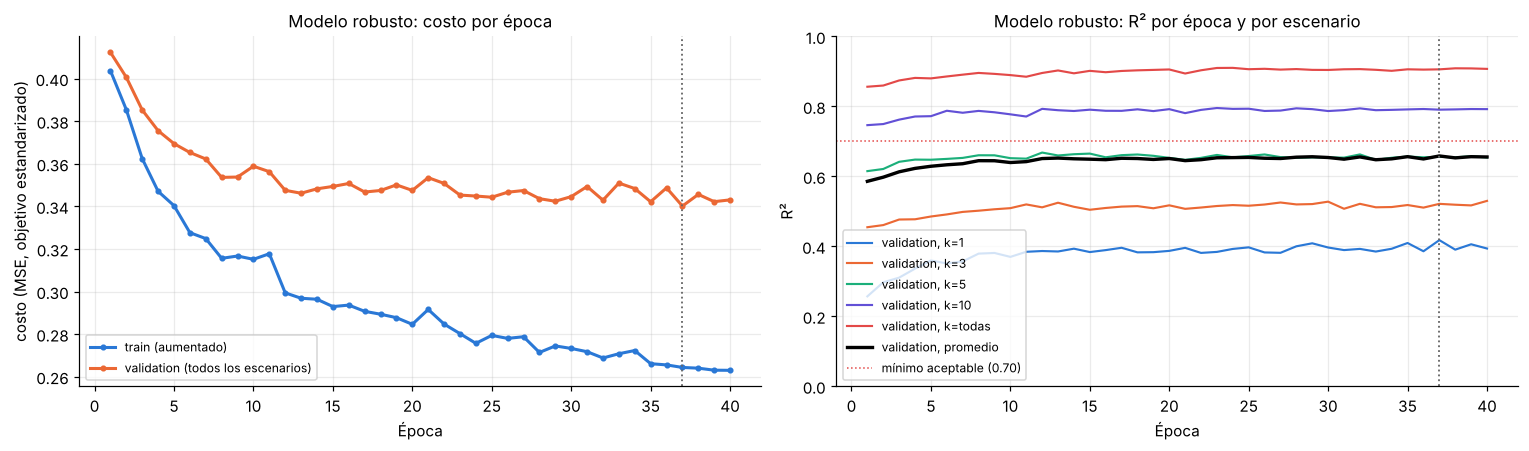

,MLP de 2b,regresión lineal,promedio de lo que pagó en esas k compras,regresión lineal con recortes,MLP robusta (entrenada con recortes)
compras observadas (k),,,,,
1,-3.629,-3.501,-3.789,0.157,0.407
3,-0.365,-0.378,-0.421,0.507,0.535
5,0.291,0.270,0.270,0.582,0.643
10,0.740,0.733,0.759,0.626,0.783
todas,0.957,0.961,nan,0.657,0.906


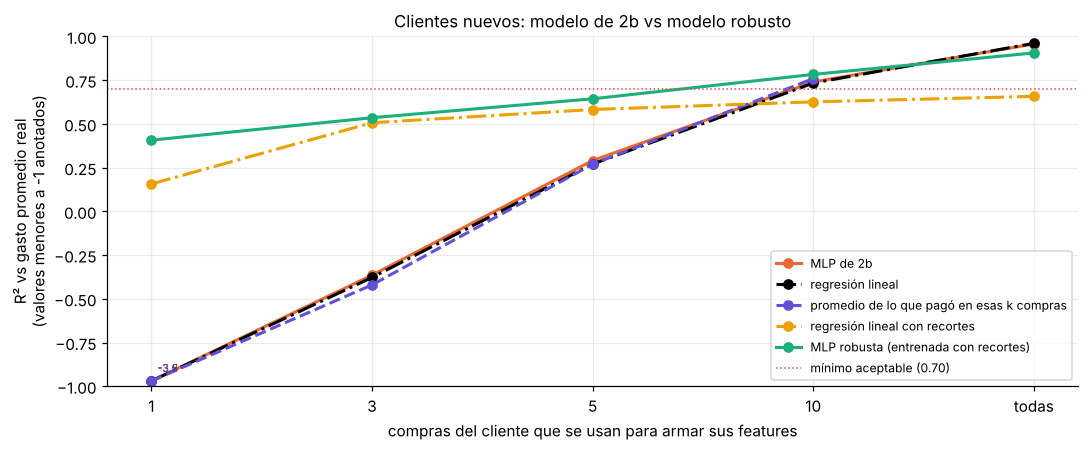

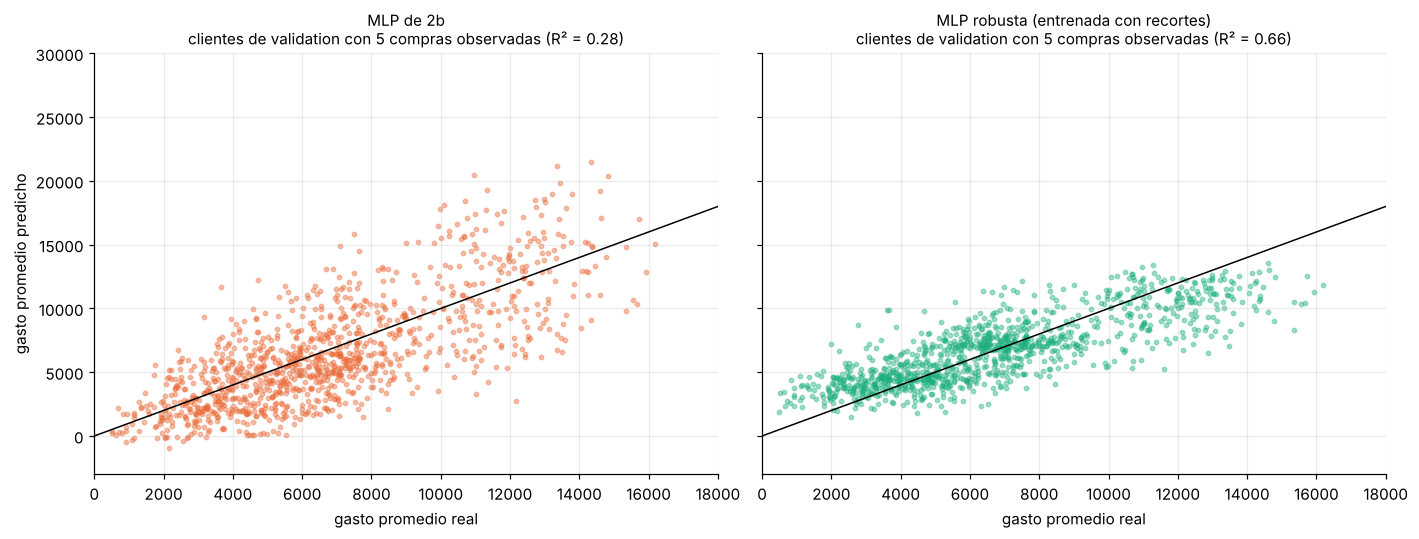

In [52]:
# 2c) Modelo robusto: curvas por época y comparación con el modelo de 2b en todos los escenarios
ep = np.arange(1, len(hist_rob["loss_train"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(ep, hist_rob["loss_train"], "o-", ms=3, color=C_TRAIN, label="train (aumentado)")
axes[0].plot(ep, hist_rob["loss_validation"], "o-", ms=3, color=C_VAL, label="validation (todos los escenarios)")
axes[0].set_ylabel("costo (MSE, objetivo estandarizado)"); axes[0].set_title("Modelo robusto: costo por época")
for i, k in enumerate(ESC_SEL):
    axes[1].plot(ep, hist_rob[f"r2_k={k}"], color=C_ACCENT[i], lw=1.4, label=f"validation, k={k}")
axes[1].plot(ep, hist_rob["r2_medio"], color="k", lw=2.2, label="validation, promedio")
axes[1].axhline(0.70, color="#e34948", lw=1, ls=":", label="mínimo aceptable (0.70)")
axes[1].set_ylim(0, 1); axes[1].set_ylabel("R²"); axes[1].set_title("Modelo robusto: R² por época y por escenario")
for ax in axes:
    ax.axvline(mejor_rob["epoca"], color="0.4", ls=":", lw=1.2)
    ax.set_xlabel("Época"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

PRED_ROB = {"MLP robusta (entrenada con recortes)": lambda e: predecir_pesos(modelo_rob, e["X"][:, IDX_ROB])}
PRED_LIN_ROB = {"regresión lineal con recortes": lambda e: lineal_rob.predict(e["X"][:, idx76]) * Y_DESVIO + Y_MEDIA}
comparacion = tabla_escenarios({**PRED_2B, **PRED_LIN_ROB, **PRED_ROB}, ESC_VAL)
display(comparacion.style.format("{:.3f}").set_caption("R² en validation (media de 5 sorteos por k)"))
graficar_escenarios(comparacion, "Clientes nuevos: modelo de 2b vs modelo robusto", ESTILOS)

# Real vs predicho para un cliente nuevo típico (5 compras observadas)
e5 = ESC_VAL[5][0]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
lim = [0, 18_000]
for ax, (nombre, f) in zip(axes, [("MLP de 2b", PRED_2B["MLP de 2b"]),
                                  ("MLP robusta (entrenada con recortes)", PRED_ROB["MLP robusta (entrenada con recortes)"])]):
    p = f(e5)
    ax.scatter(e5["y"], p, s=8, alpha=0.4, color=ESTILOS[nombre][0])
    ax.plot(lim, lim, color="k", lw=1)
    ax.set_xlim(lim); ax.set_ylim(-3000, 30_000)
    ax.set_title(f"{nombre}\nclientes de validation con 5 compras observadas (R² = {r2_score(e5['y'], p):.2f})", fontsize=10)
    ax.set_xlabel("gasto promedio real")
axes[0].set_ylabel("gasto promedio predicho")
plt.tight_layout(); plt.show()


Promediando 5 sorteos por cada k, el modelo robusto obtiene R² **0,41 con 1 compra, 0,54 con 3, 0,64 con 5 y 0,78 con 10**. El modelo de 2b obtiene -3,6, -0,37, 0,29 y 0,74. El gráfico de real vs predicho con 5 compras muestra la diferencia: el modelo de 2b reparte predicciones desde 0 hasta más de 20.000 (toma las 5 compras al pie de la letra), mientras que el robusto las concentra cerca de la diagonal y modera los casos extremos.

El precio de esa robustez es una baja con el historial completo: **0,906 contra 0,957**. Sigue muy por encima de 0,70, pero es un compromiso real. Un mismo modelo no puede ser a la vez el mejor con clientes conocidos y con clientes nuevos.

### 2d) Conclusiones finales (0.5 puntos)
Redactar de manera detallada las conclusiones finales y si se cumplió con el objetivo o no.

### **RECOMENDACIÓN**:

Voy a valorar mucho que sus análisis, explicaciones y conclusiones sean bastante detalladas y con coherencia en los resultados obtenidos. Donde se evidencie un análisis propio de un humano estudiante de posgrado y no solo copiar y pegar lo que te dijo ChatGPT. Llevo ya años con esto, así que me daré cuenta rapidamente cuando sea así y cuando no.

Les recomiendo revisar el notebook sobre optimizadores que se encuentra en el repo. Pueden acceder mediante el siguiente [enlace](https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/aprendizaje_profundo/blob/ap_2026/CLASE%202/Notebooks/clase2_4_optimizadores.ipynb). En ese notebook vemos cómo aplicar GD y Adam full-batch para una red con relación lineal. Les servirá mucho como guía para realizar esta pregunta. Ahí también podrán ver cómo se hace una animación de un gráfico 3D.

Además, de igual forma tienen disponible el siguiente [material adicional del repo](https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/aprendizaje_profundo/tree/ap_2026/CLASE%202/Teoria/Material%20adicional), el cual le servirá para aplicar Adam, ya no solo en su versión full-batch, sino también en mini-batch